# 02 — The ATB basis and the literature comparison

**Purpose.** This notebook places the learning model next to the published nuclear cost
projections. Section A maps the model onto the basis of the NREL Annual Technology Baseline
(ATB), the cost projection that ReEDS and most US capacity-expansion studies use. The
section finds which learning worlds reach each ATB 2050 cost at the deployment the ATB
itself assumes. Section B puts every other published projection that pairs a cost with a
cumulative build on the same axis, and finds the learning worlds that reproduce each one.
Both sections run the model's overnight-cost engine (the function that turns a cumulative
build into an overnight capital cost, OCC) on designed parameter grids; neither section draws
random worlds, and neither reads ReEDS outputs.

**Inputs.**
- `results/exports/01/mc_perdraw.npz`, the Monte Carlo cost draws (notebook
  `01_monte_carlo_cost_engine`); used only for the engine-parity gate.
- ReEDS fork inputs: `inputs/plant_characteristics/{nuclear,nuclear-smr}_ATB_2024_{scenario}.csv`
  (the ATB cost trajectories), `inputs/nuclear_learning/US_SCHEDULES.csv` (the six target
  trajectories, parity gate only), `inputs/nuclear_learning/rds2_2025_units.csv` (the IAEA
  unit list, through `nlpaper.pris_loader`), `inputs/financials/deflator.csv`.
- `data/literature/` (frozen records, see its README): the Abou-Jaoude deployment
  projections, the transcribed and digitized literature points, the assumptions table, the
  cite-only register and the digitizer records.

**Outputs.**
- `results/exports/02/atb/`: `atb_targets.csv`, `best_fits.csv`, `feasible_share.csv`,
  `feasible_set_{tech}_{scenario}.csv.gz`, `required_deployment_anchors.csv`,
  `min_lr_at_aj_deployment.csv`, `endpoint_feasible_share.csv`,
  `min_lr_at_aj_deployment_his_anchor.csv`, `endpoint_feasible_share_his_anchor.csv`,
  `synthesis.csv`.
- `results/exports/02/`: `c01_assumptions.csv`, `c02_points_2022usd.csv`,
  `c03_implied_rates.csv`, `c04_feasible_shares.csv`, `c05_parameter_ranges.csv`,
  `c06_aj_regression.csv`, `c07_implied_boak.csv`, `c08_cite_only.csv`, `c99_verdict.csv`;
  the panel sources `atb_cost_deployment_plane_{large,smr}.png` and
  `e11_engine_vs_literature_2panel.png` (the Fig. 1 source; notebook 16 composes Fig. 1).
- `results/figures/si/SF01_engine_vs_literature.png`, `results/figures/si/SF02_atb_placement.png`.

**Paper items.** Fig. 1 (source panel e11), Supplementary Fig. 1 (e10), Supplementary Fig. 2
(the two cost–deployment planes, composed here), Supplementary Note 1 (the replication pin in
cell `atb-26-a27_qa` and the endpoint shares).

**Runtime.** About 1.5 minutes on the development machine (4 threads).

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4, seed_note="MASTER_SEED = 20260715; named streams atb/qa1, atb/qa5, "
              "atb/qa6, lit/g0b, lit/g3 (QA sample worlds only)")

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.
seeds: MASTER_SEED = 20260715; named streams atb/qa1, atb/qa5, atb/qa6, lit/g0b, lit/g3 (QA sample worlds only)


{'python': '3.12.3',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'threads': 4,
 'threadpoolctl': True,
 'env_set': {'OMP_NUM_THREADS': '4',
  'MKL_NUM_THREADS': '4',
  'OPENBLAS_NUM_THREADS': '4',
  'NUMEXPR_NUM_THREADS': '4',
  'NUMBA_NUM_THREADS': '4'},
 'matplotlib': '3.8.4',
 'seed_note': 'MASTER_SEED = 20260715; named streams atb/qa1, atb/qa5, atb/qa6, lit/g0b, lit/g3 (QA sample worlds only)'}

In [2]:
# Imports, output folders, the seed convention and the colours both sections share.
import json
import time as _time
import zlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from nlpaper import pris_loader as pl          # the IAEA unit-list loader (one copy, in the ReEDS fork)
from nlpaper.compose import compose

EXPORTS = paths.exports("02")                  # the literature tables (c01-c99) and the panel PNGs
ATB_OUT = EXPORTS / "atb"                      # the ATB-basis tables
ATB_OUT.mkdir(exist_ok=True)
LIT_DATA = paths.DATA / "literature"           # frozen literature records
MC_PERDRAW = paths.require(paths.exports("01") / "mc_perdraw.npz",
                           produced_by="notebook 01_monte_carlo_cost_engine")

# One master seed and independent named streams. Nothing in this notebook is sampled except
# the QA worlds that check the engine; every result is an exhaustive grid evaluation.
MASTER_SEED = 20260715
assert MASTER_SEED == 20260715, "the Monte Carlo master seed of the paper"

def rng_stream(name):
    # An independent, reproducible random generator tied to a label.
    return np.random.default_rng(np.random.SeedSequence((MASTER_SEED, zlib.crc32(name.encode()))))

INK = ps.INK
TECH_COLOR, TECH_LABEL = dict(ps.COL), dict(ps.TECH_LABEL)
# The ATB scenarios are ordered (conservative -> moderate -> advanced), so they are drawn as
# lightness steps of each technology's hue (light = conservative, dark = advanced).
SCEN_ORDER = ["conservative", "moderate", "advanced"]
SCEN_COLOR = {
    "large": {"conservative": "#86b6ef", "moderate": "#3987e5", "advanced": "#184f95"},
    "smr":   {"conservative": "#f2a284", "moderate": "#eb6834", "advanced": "#a33d15"},
}
print(f"exports -> {paths.rel(EXPORTS)}; ATB tables -> {paths.rel(ATB_OUT)}; "
      f"literature records <- {paths.rel(LIT_DATA)}")

exports -> analysis\results\exports\02; ATB tables -> analysis\results\exports\02\atb; literature records <- analysis\data\literature


# Section A — The ATB basis

**What the ATB is.** NREL's Annual Technology Baseline (ATB) 2024 publishes three
overnight-cost trajectories for each nuclear technology (large reactors and small modular
reactors, SMRs): *conservative*, *moderate* and *advanced*. The ATB takes these numbers from
one source, the Idaho National Laboratory meta-analysis by Abou-Jaoude and colleagues. That
source pairs each cost trajectory with a deployment projection: 12, 33 and 199 GW of new
US build between 2030 and 2050 (12, 34 and 200 GW cumulative by 2050, of which 1 GW is
already built by 2030 in the moderate and advanced scenarios). All costs in this section are
in 2022 dollars per kW, excluding interest during construction; that is the ATB basis and
the engine's own basis, so no financing adjustment appears.

**Why a basis mapping is needed.** The ATB is the benchmark that the paper's cost results are
read against, but the ATB's numbers and the learning model count experience differently. The
model pins every cost path to a starting cost in 2030 (the *2030 starting-cost convention*:
OCC(2030) equals the anchor cost BOAK, the cost of each vendor's second unit), and prices
only experience gained after 2030. The ATB source attaches its costs earlier in the build
sequence and carries pre-2030 experience into its curves. A path-by-path comparison would
therefore mix a convention difference with a disagreement. This section maps the model onto
the ATB basis in three steps:

1. **The replication pin.** The source's own learning equation, at its own parameters
   (learning rate 9.5 %, four vendors), reproduces the ATB SMR cost tables to within
   $500/kW, the report's rounding (cell `atb-26-a27_qa`, Supplementary Note 1).
2. **The endpoint basis.** Because the 2030 convention discards pre-2030 experience by
   design, a projection is scored on its **2050 cost and the builds that reach it**, not on
   its path. Each ATB scenario is scored at its own paired deployment.
3. **The tolerance and the one-sided criterion.** The ATB rounds costs to the nearest
   $250/kW, so a cost within one rounding half-step, **±$125/kW**, meets the projection at
   its published precision. A learning world is *feasible* when its 2050 cost is at or below
   the target plus $125/kW. The criterion is one-sided because a cost below the target still
   meets it.

The section first ports the engine and checks it against the Monte Carlo draws (A1), builds
the targets (A2), fits the whole ATB trajectory on a parameter grid (A3, kept as a
diagnostic), derives the closed-form 2050 evaluator and the required deployment (A4), and
then computes the endpoint shares and draws the cost–deployment planes of Supplementary
Fig. 2 (A5).

## A1 — The overnight-cost engine and its parity gate

The next three cells hold the model's overnight-cost engine, identical to the engine of
notebook 01: the model-frame constants, the historical and international experience stocks,
and the cost function. The cost function combines two experience channels. The *own*
channel counts each vendor's own units and learns at the firm-level learning rate LR. The
*cross-firm* channel counts the other vendors' units and the spillover-weighted foreign
units, and learns at a third of that rate (ω = 1/3). A CES aggregator (a power mean with
parameter ρ) combines the two channels; ρ = 0 is the geometric mean.

The engine is evaluated here on **designed worlds**: every dial is set on a grid instead of
drawn. The dials and their ranges are:

| dial | grid in this notebook | range sampled by the Monte Carlo |
|---|---|---|
| firm-level learning rate LR (per technology) | 0.005–0.30, step 0.005 | large 0.03–0.12; SMR 0.03–0.16 |
| anchor cost BOAK | pinned by the ATB scenario (OCC(2030) = BOAK) | large 5,250–7,750; SMR 5,500–10,000 |
| spillover scale s | 0–1, 21 steps | 0–1 |
| international deployment position u | 0–1, 21 steps (Section A3), 3 steps (A4–A5) | 0–1 |
| vendor count m | 4–8 | 4–8 |
| experience base | fresh-start (tiny base) or legacy-fleet-credited (full stock) | 50/50 |
| CES ρ | −1, 0, 1 | uniform choice |

The *experience base* decides what counts as experience at the anchor. Under the fresh-start
convention each vendor starts from its two anchor units. Under the legacy-fleet-credited
convention the 135 completed US light-water reactors are added to the large-reactor base
(never to the SMR base), and the historical foreign fleet enters the cross-firm channel. The
learning-rate grid deliberately extends beyond the Monte Carlo's sampled support, so that a
target reachable only outside the support is visible.

**Gate QA-0** evaluates this engine on the Monte Carlo's own 10,000 drawn worlds and requires
the stored cost trajectories back (all six target trajectories, both technologies, relative
tolerance 1e-9). If the gate passes, every result below runs on the paper's engine.

In [3]:
# Model-frame constants - verbatim from mc_cost_trajectories.ipynb S1 (analysis switches and
# draw-count settings dropped: nothing is drawn here).
YEARS = np.arange(2024, 2051)              # annual grid, 2024-2050
T = len(YEARS)
def yi(y):
    """Index of calendar year y in the YEARS grid."""
    return int(np.where(YEARS == y)[0][0])

ANCHOR = 2030          # the anchor year: costs are pinned to known 2030 estimates (S5)
N_BOAK_UNITS = 2.0     # per-vendor experience at the anchor ("BOAK = 2OAK")
OMEGA = 1.0 / 3.0      # cross-firm learning fraction (Irwin & Klenow 1994)

# Symmetric around 0 since 2026-08-06 (companion S1): the old {-2, -1, 0, 1} grid put half
# its mass on complements, which gate the international channel to ~zero.
CES_RHO_GRID = np.array([-1.0, 0.0, 1.0])

X_SPILL_MAX = 0.30   # cross-tech spillover cap (the MC draws U(0, X_SPILL_MAX) per direction);
                     # this notebook pins x_ls = x_sl = 0.15 - inert here, since no fit ever
                     # passes an other-tech program (n_oth) to the engine

# Per-technology assumptions: unit size, learning-rate range, 2030 anchor-cost range
# (2022 USD per kW; Abou-Jaoude Table A-1 / NREL ATB 2024)
TECH = {
    "large": {"unit_gw": 1.000, "lr_lo": 0.03, "lr_hi": 0.12,
              "boak_lo": 5250.0, "boak_hi": 7750.0},
    "smr":   {"unit_gw": 0.300, "lr_lo": 0.03, "lr_hi": 0.16,
              "boak_lo": 5500.0, "boak_hi": 10000.0},
}
UNIT_FOREIGN_GW = 1.0  # foreign new builds are treated as 1-GW large reactors

U_GRID = np.linspace(0.0, 1.0, 21)   # grid for the international-deployment position u (S3)

print(f"model frame: {YEARS[0]}-{YEARS[-1]} annual (T={T}), anchor {ANCHOR}, "
      f"BOAK=2OAK per vendor, omega={OMEGA:.3f}")

model frame: 2024-2050 annual (T=27), anchor 2030, BOAK=2OAK per vendor, omega=0.333


In [4]:
# Historical + international experience - verbatim from mc_cost_trajectories.ipynb S3.
# Non-US regional milestones (GW): 2024, 2030 Low/High, 2040 Low/High, 2050 Low/High
# (IAEA RDS-1 2025 projections + WNA/CNA).
REGION_MILESTONES = {
    "CA":  (12.7, 12.7, 12.7, 18.8, 23.0, 30.0, 63.7),
    "SAM": (5.1, 5, 5, 8, 11, 8, 20),
    "WEU": (95.4, 86, 92, 81, 114, 68, 136),
    "EEU": (53.6, 57, 57, 58, 82, 68, 103),
    "AF":  (1.9, 4, 5, 7, 12, 12, 30),
    "WA":  (5.8, 11, 11, 12, 20, 15, 35),
    "SA":  (11.1, 18, 22, 25, 43, 45, 85),
    "CEA": (94.5, 136, 144, 215, 264, 242, 328),
    "SEA": (0, 0, 0, 3, 7, 4, 18),
    "OC":  (0, 0, 0, 0, 0, 0, 2),
}
# Kim & Verdolini (2023)-derived knowledge-spillover ceilings (US as recipient)
THETA_KV = {"CA": 0.28, "SAM": 0.14, "WEU": 0.17794117647, "EEU": 0.1325, "AF": 0.16688725490,
            "WA": 0.13375, "SA": 0.185, "CEA": 0.135, "SEA": 0.16583333, "OC": 0.18}
REGIONS = list(THETA_KV.keys())

US_GW_2024 = 97.0
PRIS_UNITS = pl.load_units(str(pl.UNITS_CSV))
_milestones_2024 = {r: REGION_MILESTONES[r][0] for r in REGIONS} | {"US": US_GW_2024}
_issues = pl.validate_units(PRIS_UNITS[PRIS_UNITS["status"] == "operational"], _milestones_2024)
assert not _issues, _issues   # the data file must reproduce the IAEA's own totals

FLEET = PRIS_UNITS[PRIS_UNITS["status"] == "operational"]
UC_UNITS = PRIS_UNITS[PRIS_UNITS["status"] == "under construction"]

def retirement_flow_gw(key, life_yr):
    """GW retiring per model year, from each unit's real grid-connection date + a lifetime rule."""
    return pl.retirement_schedule(FLEET, pd.Index(YEARS), lifetime_years=life_yr,
                                  region=key).to_numpy()

PIPE_END = 2030   # pipeline's real visibility horizon; structurally zero after 2030 (mc S3)
PIPELINE_GW = {r: pl.committed_pipeline(UC_UNITS[UC_UNITS["region"] == r],
                                        pd.Index(np.arange(2025, PIPE_END + 1)),
                                        lead_time_months=72).to_dict()
               for r in REGIONS}

# Under-construction units are excluded: 5 carry PLANNED grid dates (not completed experience)
_ever = PRIS_UNITS[(PRIS_UNITS["status"] != "under construction")
                   & PRIS_UNITS["grid_connection"].notna()]
HIST_UNITS = {r: int((_ever["region"] == r).sum()) for r in REGIONS + ["US"]}

US_LICENSE_LIFE = 80.0   # yr - US subsequent-license-renewal trend; ~0 US retirements before 2050
ONE_FACTOR_DELTA = 0.0   # bounded regional noise on u (0 = one global u; variance-conservative)

def net_path_gw(region, u):
    """Regional net capacity path: interpolate the 2024/2030/2040/2050 milestones, positioned
    between Low and High by the global deployment draw u."""
    c = REGION_MILESTONES[region]
    vals = [c[0], c[1] + u*(c[2]-c[1]), c[3] + u*(c[4]-c[3]), c[5] + u*(c[6]-c[5])]
    return np.interp(YEARS, [2024, 2030, 2040, 2050], vals)

def gross_additions_gw(region, u):
    """The retirement identity: builds = max(0, capacity change + retirements); the committed
    pipeline REPLACES the interpolated path through PIPE_END = 2030 (real units; structurally
    zero after 2030, so it only shapes the pre-anchor record - see mc_cost_trajectories S3)."""
    dnet = np.diff(net_path_gw(region, u), prepend=net_path_gw(region, u)[0])
    ret = retirement_flow_gw(region, 65.0 + 5.0*u)   # IAEA-calibrated lives, 65+5u (mc S3; 2026-08-05)
    g = np.clip(dnet + ret, 0.0, None)
    pipe_mask = YEARS <= PIPE_END
    g[pipe_mask] = [PIPELINE_GW[region].get(int(y), 0.0) for y in YEARS[pipe_mask]]
    return g

def post_anchor_cum(flow):
    """Cumulative builds counted from the 2030 anchor, END-of-year basis. The one-year
    completion lag - a year's builds price only LATER years - is applied at the pricing
    boundary (lag1 in the engine cell), companion-identical."""
    x = flow.copy()
    x[YEARS <= ANCHOR] = 0.0
    return np.cumsum(x)

# Foreign stocks on the u grid (mc S3): unsplit, 1-GW basis - the engine's cross-firm
# channel does not distinguish designs (mc S5 Step 5). The IAEA SMR-share split of the
# foreign fleet lives in the main notebook's S14 own-routing sensitivity, not in any engine.
# REGION_STOCK[r][gi] = cumulative post-anchor units at u = U_GRID[gi]
REGION_STOCK = {}
for r in REGIONS:
    m_a = np.empty((len(U_GRID), T))
    for gi, u in enumerate(U_GRID):
        m_a[gi] = post_anchor_cum(gross_additions_gw(r, u)) / UNIT_FOREIGN_GW
    REGION_STOCK[r] = m_a

US_RET = retirement_flow_gw("US", US_LICENSE_LIFE)

# The six paper schedules, read from the exported single source of truth - needed ONLY by QA-0
# (to reproduce the companion's trajectories); the analysis itself uses the Abou-Jaoude
# deployments built in A3.
OFFSET_GW = 3.0
_sched = pd.read_csv(paths.reeds_inputs() / "nuclear_learning" / "US_SCHEDULES.csv",
                     comment="#").set_index("year")
assert list(_sched.index) == list(YEARS)
SCEN_TOKENS = list(_sched.columns)
USN_NEW = {}     # USN_NEW[tech][token] -> (T,) cumulative post-anchor new units
for tech in TECH:
    USN_NEW[tech] = {}
    for tok in SCEN_TOKENS:
        cap = _sched[tok].to_numpy(float) - OFFSET_GW
        dnet = np.diff(cap, prepend=cap[0])
        USN_NEW[tech][tok] = post_anchor_cum(np.clip(dnet + US_RET, 0.0, None)) / TECH[tech]["unit_gw"]

print(f"PRIS fleet loaded: {len(FLEET)} operational, {len(UC_UNITS)} under construction; "
      f"schedules for QA-0: {SCEN_TOKENS}")

PRIS fleet loaded: 417 operational, 62 under construction; schedules for QA-0: ['eia_aeo_high', 'abou_jaoude', 'iaea_high', 'mckinsey', 'cop28', 'eo2025']


In [5]:
# The OCC engine - verbatim from mc_cost_trajectories.ipynb S5 (draw_world not ported: this
# notebook evaluates designed worlds, it draws none), plus the two additions described above.
H_ALL_W = sum(THETA_KV[r]*HIST_UNITS[r] for r in REGIONS)   # theta-weighted historical foreign stock
OTHER_TECH = {"large": "smr", "smr": "large"}
X_IN_COL = {"large": "x_sl", "smr": "x_ls"}     # incoming cross-tech fraction, per receiving tech

def lag1(a):
    """One-year completion lag along the time axis: the stock ENTERING year t is the builds
    completed through t-1. Cumulative arrays stay end-of-year for accounting; the lag is
    applied here, at the pricing boundary - without it the first post-anchor cohort would
    price on its own not-yet-built units (below BOAK). Companion-identical (mc S5)."""
    a = np.asarray(a, float)
    out = np.zeros_like(a)
    out[..., 1:] = a[..., :-1]
    return out

def experience_channels(world, tech, n_us, n_oth=None):
    """The two experience stocks O_d(t) (own) and A_d(t) (cross-firm), each (n_draws, T).

    n_us:  the schedule's cumulative post-anchor US builds of THIS technology, shape (T,).
    n_oth: the OTHER technology's cumulative post-anchor US builds, (T,) or None. The drawn
           incoming cross-tech fraction x scales it into the cross-firm channel; this
           notebook's single-technology fits never pass it, so x stays inert here.

    International experience enters the CROSS-FIRM channel at weight s*theta, unsplit
    across technologies (mc S5 Step 5): the Kim & Verdolini flows are normalized to the
    domestic INTER-FIRM citation baseline (their eq. (5); self-citations excluded), so
    theta prices the extra national border ON TOP OF the firm wall - omega once for the
    firm wall, theta once for the border.
    """
    n = len(world)
    u_r = np.repeat(world["u"].values[:, None], len(REGIONS), axis=1)
    if ONE_FACTOR_DELTA > 0:   # optional bounded regional noise on u (off by default)
        u_r = np.clip(u_r + rng_stream("one_factor_noise").uniform(
            -ONE_FACTOR_DELTA, ONE_FACTOR_DELTA, (n, len(REGIONS))), 0, 1)
    gi = np.clip(np.rint(u_r * (len(U_GRID)-1)).astype(int), 0, len(U_GRID)-1)
    S_kv = np.zeros((n, T))
    for j, r in enumerate(REGIONS):
        S_kv += THETA_KV[r] * REGION_STOCK[r][gi[:, j], :]
    S_kv = lag1(S_kv)                                    # stock entering year t (built thru t-1)
    N_us = lag1(np.broadcast_to(np.asarray(n_us, float), (n, T)))
    conv = world["conv_full"].values[:, None].astype(float)
    m = world["n_vendors"].values[:, None].astype(float)
    s = world["s"].values[:, None]
    # US historical fleet counts toward LARGE only (D8'): the SMR learning-rate range is
    # empirically derived and already embeds any benefit from prior LWR builds, so crediting
    # the ~140-unit US stock to the SMR base would double-count it. The theta-weighted
    # FOREIGN stock (historical and projected) is not-own-design experience for both
    # technologies alike and enters the cross-firm channel unsplit.
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0
    own0 = N_BOAK_UNITS + conv*hist_us/m                     # per-vendor domestic base (D8/D8')
    own = own0 + N_us/m                                      # own-design units, learn at LR
    oth = (m-1.0)*own0 + N_us*(m-1.0)/m \
          + s*(conv*H_ALL_W + S_kv)                          # others + international, at OMEGA*LR
    if n_oth is not None:                                    # cross-tech: the other technology's
        x = world[X_IN_COL[tech]].values[:, None]            # incoming cross-tech fraction
        oth = oth + x*lag1(np.broadcast_to(np.asarray(n_oth, float), (n, T)))  # US program (Step 5')
    return own, oth

def occ_paths(world, tech, n_us, n_oth=None):
    """Reference engine (D9, sigma = 1). Kept untouched as the regression benchmark for the
    CES engine below - QA-1 asserts occ_paths_ces(rho -> 0) reproduces it exactly. n_oth
    passes through to experience_channels."""
    own, oth = experience_channels(world, tech, n_us, n_oth=n_oth)
    lr = world[f"lr_{tech}"].values[:, None]
    mult = ((own/own[:, [yi(ANCHOR)]])**np.log2(1.0 - lr)
            * (oth/oth[:, [yi(ANCHOR)]])**np.log2(1.0 - OMEGA*lr))
    return world[f"boak_{tech}"].values[:, None] * mult

CES_EPS = 1e-8   # |ces_rho| below this takes the closed-form geometric-mean branch

def occ_paths_ces(world, tech, n_us, n_oth=None, ces_rho=None):
    """Production engine (D11/D12): CES power-mean aggregation of the two channels,
    E = (w O^rho + (1-w) A^rho)^(1/rho), OCC = BOAK (E(t)/E(2030))^(-b), with (w, b)
    derived per-draw from (LR, omega) so the rho -> 0 member reproduces occ_paths EXACTLY.
    n_oth passes through to experience_channels."""
    own, oth = experience_channels(world, tech, n_us, n_oth=n_oth)
    assert own.min() >= N_BOAK_UNITS and oth.min() >= N_BOAK_UNITS, "stock below anchor base; log unsafe"
    lr = world[f"lr_{tech}"].values[:, None]
    b1, b2 = np.log2(1.0 - lr), np.log2(1.0 - OMEGA*lr)     # channel exponents, both < 0
    b, w = -(b1 + b2), b1/(b1 + b2)                         # b > 0, w in (0,1)  (D12)
    rho = world["ces_rho"].values if ces_rho is None else np.full(len(world), float(ces_rho))
    rho = rho[:, None]
    geo = np.abs(rho) < CES_EPS
    lnO, lnA = np.log(own), np.log(oth)
    with np.errstate(over="raise"):
        lnE = np.where(geo, w*lnO + (1.0-w)*lnA,
                       lnO + np.log1p((1.0-w)*np.expm1(np.where(geo, 0.0, rho)*(lnA - lnO)))
                           / np.where(geo, 1.0, rho))
    return world[f"boak_{tech}"].values[:, None] * np.exp(-b*(lnE - lnE[:, [yi(ANCHOR)]]))

def eq12_gen(N, LR, m):
    """Abou-Jaoude eq. (12) generalized to m vendors (companion QA3): the closed form the
    engine collapses to at s = 0, tiny base, rho = 0."""
    return (1-LR)**np.log2(N/m) * (1-OMEGA*LR)**np.log2((m-1)*N/m)

def make_worlds(lr, boak, u, s, m, conv, rho):
    """Designed-world frame for the engine: every input pinned, no draws (adapted from
    smr100_case_export.ipynb's make_world; the lr/boak dials are direct values here, applied
    to BOTH techs' columns - each fit evaluates a single technology, so the twin columns are
    just along for the engine's column layout)."""
    arrs = np.broadcast_arrays(*[np.asarray(a, float) for a in (lr, boak, u, s, m, conv, rho)])
    w = pd.DataFrame(index=range(arrs[0].size))
    for tech in TECH:
        w[f"lr_{tech}"] = arrs[0].ravel()
        w[f"boak_{tech}"] = arrs[1].ravel()
    for k, a in zip(("u", "s", "n_vendors", "conv_full", "ces_rho"),
                    (arrs[2], arrs[3], arrs[4], arrs[5], arrs[6])):
        w[k] = a.ravel()
    w["x_ls"] = 0.15   # cross-tech spillover fractions, pinned at the drawn range's midpoint -
    w["x_sl"] = 0.15   # inert here (no other-tech program is passed; companion S5 Step 5')
    return w

print(f"engine ready: H_ALL_W = {H_ALL_W:.1f} theta-weighted historical foreign units; "
      f"US historical fleet = {HIST_UNITS['US']} units (large only, full-stock convention)")

engine ready: H_ALL_W = 83.5 theta-weighted historical foreign units; US historical fleet = 135 units (large only, full-stock convention)


In [6]:
# QA-0 - engine-port parity: evaluate the ported engine on the companion's OWN drawn worlds
# and require the stored OCC trajectories back, for all six schedules x both technologies.
# This is the smr100_case_export QA-0 pattern, inverted: instead of re-drawing the worlds we
# load them, so the check isolates the ENGINE port (experience stocks, CES aggregation,
# anchor convention) from the sampler. Tolerance is cross-kernel floating-point rounding only.
Z0 = np.load(MC_PERDRAW, allow_pickle=False)
_wcols = [str(c) for c in Z0["world_columns"]]
assert list(Z0["years"]) == list(YEARS)
for tok in SCEN_TOKENS:
    _w = pd.DataFrame(Z0[f"worlds_{tok}"], columns=_wcols)
    for tech in TECH:
        _occ = occ_paths_ces(_w, tech, USN_NEW[tech][tok])
        assert np.allclose(_occ, Z0[f"occ_{tok}_{tech}"], rtol=1e-9, atol=0.0), (tok, tech)
_n0 = Z0[f"worlds_{SCEN_TOKENS[0]}"].shape[0]
print(f"QA-0 PASSED: ported engine reproduces the companion's OCC trajectories on its own "
      f"{_n0:,} drawn worlds, all {len(SCEN_TOKENS)} schedules x both techs (rtol 1e-9)")
del Z0, _w, _occ

QA-0 PASSED: ported engine reproduces the companion's OCC trajectories on its own 10,000 drawn worlds, all 6 schedules x both techs (rtol 1e-9)


## A2 — The targets: ATB cost trajectories and the paired deployments

Two inputs define the comparison.

1. **Cost targets.** The six ATB 2024 files that the ReEDS fork ships, read at the five
   milestone years 2030, 2035, 2040, 2045 and 2050 (the years the source's tables specify;
   the annual files interpolate between them). The 2030 value is not a fit target: the
   2030 starting-cost convention makes OCC(2030) equal BOAK, so each ATB scenario *pins* the
   anchor cost. The cell checks that the ATB advanced and conservative 2030 costs are
   exactly the ends of the Monte Carlo's anchor range.
2. **Deployment paths.** The Abou-Jaoude projections of new US deployment at 5-year
   milestones (`data/literature/abou_jaoude_deployment_projections.csv`). The cell asserts
   them against the published table, converts them to cumulative post-2030 units on the
   annual grid (flows at or before 2030 are zeroed; the 1 GW that the moderate and advanced
   scenarios place by 2030 belongs to the anchor), and divides by the unit size (1 GW
   large, 0.3 GW SMR). Both technologies face the same GW program, because the source
   projects a program size, not a technology split.

**The scoring basis.** The engine has a one-year completion lag: a year's builds price only
later years. The stock that prices the 2050 cost is therefore the build completed through
2049, not the total by 2050 (10.8, 29.6 and 183.8 GW instead of 12, 33 and 199 GW). Every
comparison of a 2050 cost against a paired deployment uses the through-2049 stock. The quoted
program totals (12 / 33 / 199 GW) stay by-2050 where they describe the program itself.

`atb_targets.csv` is the target table that Section B and the captions read.

In [7]:
# Load the ATB targets and build the Abou-Jaoude deployment inputs.
ATB_NAME = {"large": "nuclear", "smr": "nuclear-smr"}
PC_DIR = paths.reeds_inputs() / "plant_characteristics"

def atb_capcost(tech, scen):
    """ATB 2024 capcost on the YEARS grid (2022$/kW, idc-exclusive)."""
    f = PC_DIR / f"{ATB_NAME[tech]}_ATB_2024_{scen}.csv"
    return pd.read_csv(f).set_index("t")["capcost"].loc[YEARS].to_numpy(float)

MILESTONES = [2030, 2035, 2040, 2045, 2050]
MYEARS = MILESTONES[1:]                       # the fit years (2030 is exact by construction)
MI = [yi(y) for y in MILESTONES]

ATB_OCC = {t: {s: atb_capcost(t, s) for s in SCEN_ORDER} for t in TECH}
TARGET = {t: {s: ATB_OCC[t][s][MI] for s in SCEN_ORDER} for t in TECH}     # at MILESTONES
BOAK_PIN = {t: {s: float(TARGET[t][s][0]) for s in SCEN_ORDER} for t in TECH}

# Consistency check (npv_winner_check QA-B): the MC's anchor ranges ARE the ATB
# advanced/conservative 2030 capcosts, so the scenario pins BOAK inside the engine's own range.
for t in TECH:
    assert (BOAK_PIN[t]["advanced"], BOAK_PIN[t]["conservative"]) == \
           (TECH[t]["boak_lo"], TECH[t]["boak_hi"]), t
    assert TECH[t]["boak_lo"] <= BOAK_PIN[t]["moderate"] <= TECH[t]["boak_hi"], t

# Abou-Jaoude deployment projections (GW of new deployment, 5-year milestones)
_aj = pd.read_csv(LIT_DATA / "abou_jaoude_deployment_projections.csv")
AJ_YEARS = _aj["year"].to_numpy(float)
AJ_GW = {s: _aj[s].to_numpy(float) for s in SCEN_ORDER}
# Pin the CSV to the published tables as transcribed in the companion's QA4
_aj_qa4 = {"conservative": {2030: 0, 2035: 1, 2040: 3, 2045: 6, 2050: 12},
           "moderate":     {2030: 1, 2035: 3, 2040: 8.5, 2045: 17, 2050: 34},
           "advanced":     {2030: 1, 2035: 14, 2040: 58, 2045: 124, 2050: 200}}
for s in SCEN_ORDER:
    assert dict(zip(AJ_YEARS.astype(int), AJ_GW[s])) == _aj_qa4[s], s

# Post-anchor deployment basis for Part 2: subtract the 2030 baseline (1 GW in moderate/
# advanced) so the AJ reference deployment shares N_AJ's post-anchor unit basis
# (post_anchor_cum zeroes flows <= 2030; Part 1 already counts this way).
AJ_GW_POST = {s: float(AJ_GW[s][-1] - AJ_GW[s][0]) for s in SCEN_ORDER}

# Entering-2050 scoring basis (adjudicated 2026-08-24): the engine's one-year lag means
# the stock that PRICES 2050 is the build completed through 2049. Wherever the closed-form
# 2050 evaluator (shape_2050 / required_gw, both defined on that contract) is compared
# against the AJ program (T4/T5/T6, the F6 contour, F7's reference line, F8's marker,
# QA-3 (ii)), the paired deployment must be the through-2049 cumulative - feeding the
# by-2050 total credits 2050's own completions (advanced: ~15.2 GW/yr over 2045-2050,
# a ~7.6% overstatement). Part 1 / F9 run the AJ annual path through the full engine
# (lag applied internally) and were already on this basis. The QUOTED paired-program
# totals (12/33/199 GW by 2050) stay by-2050 wherever they describe the program itself.
AJ_GW_ENT50 = {s: float(np.interp(2049.0, AJ_YEARS, AJ_GW[s]) - AJ_GW[s][0])
               for s in SCEN_ORDER}

# n_us: cumulative post-anchor new-build units on the annual grid. New-build additions, not
# net capacity: no retirement identity. Flows at or before 2030 are zeroed (anchor convention).
N_AJ = {}
for tech in TECH:
    N_AJ[tech] = {}
    for s in SCEN_ORDER:
        cap = np.interp(YEARS, AJ_YEARS, AJ_GW[s])
        dnet = np.diff(cap, prepend=cap[0])
        N_AJ[tech][s] = post_anchor_cum(np.clip(dnet, 0.0, None)) / TECH[tech]["unit_gw"]

# T1 - the inversion targets at the milestone years
_t1 = pd.DataFrame({(t, s): TARGET[t][s] for t in TECH for s in SCEN_ORDER},
                   index=pd.Index(MILESTONES, name="year"))
_t1.columns = pd.MultiIndex.from_tuples(_t1.columns, names=["tech", "scenario"])
_t1.to_csv(ATB_OUT / "atb_targets.csv")
_dep = pd.DataFrame({s: {"GW by 2050 (post-2030)": AJ_GW_POST[s],
                         "large units by 2050": round(N_AJ['large'][s][-1]),
                         "SMR units by 2050": round(N_AJ['smr'][s][-1])}
                     for s in SCEN_ORDER}).T
print("T1 - ATB OCC targets ($/kW 2022) at the milestone years -> exports/02/atb/atb_targets.csv")
print(_t1.to_string())
print("\nAbou-Jaoude deployment scenarios (post-2030 new builds):")
print(_dep.to_string())

T1 - ATB OCC targets ($/kW 2022) at the milestone years -> exports/02/atb/atb_targets.csv


tech            large                            smr                  
scenario conservative moderate advanced conservative moderate advanced
year                                                                  
2030           7750.0   5750.0   5250.0      10000.0   8000.0   5500.0
2035           7750.0   5500.0   4000.0       9500.0   6500.0   3250.0
2040           7500.0   4750.0   3000.0       8000.0   5250.0   2500.0
2045           6750.0   4250.0   2500.0       7000.0   4500.0   2250.0
2050           6000.0   3750.0   2250.0       6250.0   4000.0   2000.0

Abou-Jaoude deployment scenarios (post-2030 new builds):
              GW by 2050 (post-2030)  large units by 2050  SMR units by 2050
conservative                    12.0                 12.0               40.0
moderate                        33.0                 33.0              110.0
advanced                       199.0                199.0              663.0


## A3 — The full-trajectory fit (diagnostic)

**What this computes.** For each technology and scenario, deployment is fixed at the paired
Abou-Jaoude path and BOAK at the ATB 2030 cost. The engine is then evaluated on the full cross
product of the other dials: LR (60 values) × s (21) × u (21) × m (5) × experience base (2)
× ρ (3), which is 793,800 designed worlds per fit. BOAK enters the engine as a factor
(OCC = BOAK × shape), so each world's *shape* (OCC / BOAK at the milestone years) is computed
once per technology and deployment and reused for every cost scenario. The anchor identity
shape(2030) = 1 is asserted for every world (QA-4).

**How to read it.** The *misfit* of a world is its largest absolute deviation from the ATB
trajectory over 2035–2050, in $/kW. A world fits the trajectory when its misfit is at most
$250/kW. `best_fits.csv` lists the best world per fit; `feasible_share.csv` gives the share of
worlds that fit at $100, $250 and $500, over the whole grid and within the Monte Carlo's
sampled learning-rate support; `feasible_set_*.csv.gz` lists every world that fits at $250.
This full-path criterion is a diagnostic. The paper's criterion is the one-sided 2050
endpoint of A5, because the 2030 convention guarantees that a path cannot match exactly.
Section B re-derives these feasible sets as its gate G2.

In [8]:
# The parameter grid, and one shape table per (technology, deployment).
import time as _time

LR_GRID = np.round(np.arange(0.005, 0.3001, 0.005), 3)      # 60 values, past the MC support
S21 = np.round(np.linspace(0.0, 1.0, 21), 3)
U21 = U_GRID.copy()
M_GRID = np.array([4.0, 5.0, 6.0, 7.0, 8.0])
CONV_GRID = np.array([0.0, 1.0])
DISC_COMBOS = [(rho, conv, m) for rho in CES_RHO_GRID for conv in CONV_GRID for m in M_GRID]

_mesh = np.meshgrid(LR_GRID, S21, U21, indexing="ij")
LRv, Sv, Uv = (a.ravel() for a in _mesh)
NPTS = LRv.size                                              # 60 x 21 x 21 = 26,460
NW = len(DISC_COMBOS) * NPTS                                 # 1,058,400 worlds per fit
GRID_SHAPE = (len(CES_RHO_GRID), len(CONV_GRID), len(M_GRID),
              len(LR_GRID), len(S21), len(U21))              # reshape order of the full grid

# Flat parameter columns, aligned with every misfit/shape array below
P = {"lr": np.tile(LRv, len(DISC_COMBOS)), "s": np.tile(Sv, len(DISC_COMBOS)),
     "u": np.tile(Uv, len(DISC_COMBOS)),
     "ces_rho": np.repeat([c[0] for c in DISC_COMBOS], NPTS),
     "conv_full": np.repeat([c[1] for c in DISC_COMBOS], NPTS),
     "n_vendors": np.repeat([c[2] for c in DISC_COMBOS], NPTS)}

# SHAPES[(tech, dep_scen)][:, k] = OCC/BOAK at MILESTONES[k]; shape(2030) == 1 asserted (QA-4)
SHAPES = {}
_t0 = _time.time()
for tech in TECH:
    for dep in SCEN_ORDER:
        shp = np.empty((NW, len(MILESTONES)), dtype=np.float32)
        n_us = N_AJ[tech][dep]
        for ci, (rho, conv, m) in enumerate(DISC_COMBOS):
            w = make_worlds(LRv, 1.0, Uv, Sv, m, conv, rho)
            occ = occ_paths_ces(w, tech, n_us)
            assert np.allclose(occ[:, yi(ANCHOR)], 1.0, rtol=0, atol=1e-12)   # QA-4 anchor identity
            shp[ci*NPTS:(ci+1)*NPTS] = occ[:, MI]
        SHAPES[(tech, dep)] = shp
print(f"QA-4 PASSED en route: shape(2030) == 1 for every world "
      f"(anchor identity OCC(2030) == BOAK)")
print(f"built {len(SHAPES)} shape tables x {NW:,} worlds in {_time.time()-_t0:.0f}s "
      f"({len(TECH)*len(SCEN_ORDER)*len(DISC_COMBOS)} engine calls)")

QA-4 PASSED en route: shape(2030) == 1 for every world (anchor identity OCC(2030) == BOAK)
built 6 shape tables x 793,800 worlds in 45s (180 engine calls)


In [9]:
# The matched-pair fits: misfit per world, feasible sets, best fits.
TOL = 250.0                      # trajectory (milestone) fit tolerance ($/kW, max-abs at 2035-2050)
TOL_END = 125.0                  # endpoint feasibility tolerance ($/kW) - 08-29 (Ethan): the ATB
                                 # rounds to the nearest $250/kW, so the true value lies within one
                                 # half-step ($125) of the published number; supersedes the
                                 # one-increment $250 endpoint criterion in F8/F9/F10 + the exports
TOLS = [100.0, 250.0, 500.0]     # robustness ladder

def misfit(tech, cost_scen, dep_scen):
    """(NW,) worst absolute deviation from the ATB trajectory over the fit milestones."""
    pred = BOAK_PIN[tech][cost_scen] * SHAPES[(tech, dep_scen)][:, 1:].astype(np.float64)
    return np.abs(pred - TARGET[tech][cost_scen][1:]).max(axis=1)

def eff_rate(lr):
    """Firm-level LR -> effective industry rate per fleet doubling (companion QA5): the
    number comparable to published program-level learning rates (~1.3 x LR)."""
    return 1.0 - (1.0 - lr)*(1.0 - OMEGA*lr)

FITS = {}                        # FITS[(tech, scen)] -> dict(mis, best index)
for tech in TECH:
    for scen in SCEN_ORDER:
        mis = misfit(tech, scen, scen)
        FITS[(tech, scen)] = {"mis": mis, "best": int(np.argmin(mis))}

# T2 - best-fit worlds (plus the Abou-Jaoude precedent row for orientation)
_rows = []
for (tech, scen), f in FITS.items():
    i = f["best"]
    in_sup = TECH[tech]["lr_lo"] <= P["lr"][i] <= TECH[tech]["lr_hi"]
    _rows.append({"tech": tech, "scenario": scen, "lr": P["lr"][i],
                  "eff_industry_rate": round(eff_rate(P["lr"][i]), 4),
                  "s": P["s"][i], "u": P["u"][i], "m": int(P["n_vendors"][i]),
                  "base": "full" if P["conv_full"][i] else "tiny",
                  "ces_rho": P["ces_rho"][i], "misfit_$kW": round(float(f["mis"][i]), 1),
                  "lr_in_MC_support": in_sup})
best_fits = pd.DataFrame(_rows).set_index(["tech", "scenario"])
best_fits.to_csv(ATB_OUT / "best_fits.csv")
print("T2 - best-fit worlds per tech x scenario -> exports/atb/best_fits.csv")
print("     (Abou-Jaoude's own SMR setting for reference: LR = 9.5%, m = 4, tiny base, s = 0)")
print(best_fits.to_string())

# T3 - feasible-set shares: over the whole grid, and within the MC's sampled LR support
_rows = []
for (tech, scen), f in FITS.items():
    sup = (P["lr"] >= TECH[tech]["lr_lo"]) & (P["lr"] <= TECH[tech]["lr_hi"])
    row = {"tech": tech, "scenario": scen, "min_misfit_$kW": round(float(f["mis"].min()), 1)}
    for tol in TOLS:
        feas = f["mis"] <= tol
        row[f"share_grid_<=${tol:.0f}"] = round(float(feas.mean()), 4)
        row[f"share_support_<=${tol:.0f}"] = round(float(feas[sup].mean()), 4)
    _rows.append(row)
feas_share = pd.DataFrame(_rows).set_index(["tech", "scenario"])
feas_share.to_csv(ATB_OUT / "feasible_share.csv")
print("\nT3 - feasible shares (of the full grid / of the grid restricted to the sampled LR "
      "support) -> exports/atb/feasible_share.csv")
print(feas_share.to_string())

# The feasible sets at the primary tolerance, as compressed CSVs (Section B's gate G2 reads them).
for (tech, scen), f in FITS.items():
    idx = np.flatnonzero(f["mis"] <= TOL)
    # gzip with a fixed mtime so the file is byte-identical on every run
    pd.DataFrame({k: P[k][idx] for k in P} | {"misfit": np.round(f["mis"][idx], 1)}) \
        .to_csv(ATB_OUT / f"feasible_set_{tech}_{scen}.csv.gz", index=False,
                compression={"method": "gzip", "mtime": 0})
print(f"\nwrote 6 feasible_set_*.csv.gz (tolerance ${TOL:.0f}/kW)")

T2 - best-fit worlds per tech x scenario -> exports/atb/best_fits.csv
     (Abou-Jaoude's own SMR setting for reference: LR = 9.5%, m = 4, tiny base, s = 0)
                       lr  eff_industry_rate     s     u  m  base  ces_rho  misfit_$kW  lr_in_MC_support
tech  scenario                                                                                          
large conservative  0.200             0.2533  0.05  0.00  8  tiny     -1.0       231.9             False
      moderate      0.135             0.1739  0.05  0.45  4  tiny      1.0        78.9             False
      advanced      0.130             0.1677  0.35  1.00  4  tiny      1.0        38.2             False
smr   conservative  0.175             0.2231  1.00  1.00  6  full     -1.0       208.0             False
      moderate      0.130             0.1677  0.70  1.00  5  tiny      1.0        71.9              True
      advanced      0.125             0.1615  0.85  0.80  4  tiny      1.0       213.6              True

T3


wrote 6 feasible_set_*.csv.gz (tolerance $250/kW)


## A4 — The 2050 endpoint with deployment free

**Why deployment collapses to one number.** The engine prices year t from the cumulative
experience stocks at t only:

$$\mathrm{OCC}(t) = \mathrm{BOAK}\cdot\Big(\tfrac{E(O(t),\,A(t))}{E(O(2030),\,A(2030))}\Big)^{-b},$$

with the own stock $O(t) = \mathrm{own}_0 + N_{us}(t)/m$ and the cross-firm stock
$A(t) = (m-1)\,\mathrm{own}_0 + N_{us}(t)\,(m-1)/m + s\,(H_{KV} + S_{KV}(t))$, where $E$ is
the CES aggregate, $H_{KV}$ the spillover-weighted historical foreign fleet and $S_{KV}$ the
foreign builds after 2030. Every deployment path with the same cumulative build therefore
gives the same 2050 cost, however the builds are timed (QA-5b checks this through the full
engine). The next cell writes the closed-form 2050 evaluator `shape_2050` and checks it
against the full engine (QA-5a) and for monotonicity in the build (QA-5c).

The second cell uses that evaluator in two ways. It finds, by bisection, the **required
cumulative build** that reaches each ATB 2050 cost from its own 2030 anchor for every grid
world (QA-6 plugs the solutions back in). It also writes two tables: `required_deployment_anchors.csv`
gives the required build at three reference worlds (the source's own setting, and a central
Monte Carlo world under each experience base), and `min_lr_at_aj_deployment.csv` gives the
**minimum firm-level learning rate** that reaches each ATB 2050 cost at the paired
deployment (m = 6, u = 0.5, ρ = 0; NaN = unreachable even at LR 30 %). Supplementary Fig. 2's
caption quotes the second table.

In [10]:
# The closed-form 2050 evaluator (single-year restriction of occ_paths_ces), and QA-5.
I2050 = yi(2050)

def skv_2050(u):
    """Theta-weighted foreign stock ENTERING the 2050 price, per world: builds through 2049
    (the engine's one-year completion lag), post-anchor basis (years <= 2030 zeroed);
    unsplit across technologies (the cross-firm channel does not distinguish designs)."""
    gi = np.clip(np.rint(np.asarray(u, float) * (len(U_GRID)-1)).astype(int), 0, len(U_GRID)-1)
    return sum(THETA_KV[r] * REGION_STOCK[r][gi, I2050 - 1] for r in REGIONS)

def shape_2050(tech, lr, s, u, m, conv, rho, n2050):
    """OCC(2050)/BOAK for a post-anchor stock of n2050 units ENTERING the 2050 price (builds
    completed through 2049, per the engine's one-year lag) - vectorized over worlds.
    Identical algebra to occ_paths_ces restricted to the 2050 and anchor columns: the
    theta*s-weighted foreign stock (and, under full-stock, the all-LWR historical fleet)
    sits in the cross-firm channel, unsplit across technologies (companion S5 Step 5).
    No other-tech US program appears here (Part 2 prices a single technology's deployment;
    n_oth stays None throughout), so the drawn cross-tech x never enters."""
    lr, s, m, conv, rho, n2050 = np.broadcast_arrays(
        *[np.asarray(a, float) for a in (lr, s, m, conv, rho, n2050)])
    skv = np.broadcast_to(skv_2050(u), lr.shape)
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0
    H_kv = conv*H_ALL_W                                  # foreign historical: both techs alike
    own0 = N_BOAK_UNITS + conv*hist_us/m
    ownA = own0
    own50 = own0 + n2050/m
    othA = (m-1.0)*own0 + s*H_kv                         # S_KV at the anchor is 0
    oth50 = (m-1.0)*own0 + n2050*(m-1.0)/m + s*(H_kv + skv)
    b1, b2 = np.log2(1.0 - lr), np.log2(1.0 - OMEGA*lr)
    b, w = -(b1 + b2), b1/(b1 + b2)
    geo = np.abs(rho) < CES_EPS
    rho_safe = np.where(geo, 1.0, rho)
    def _lnE(o, a):
        lnO, lnA = np.log(o), np.log(a)
        return np.where(geo, w*lnO + (1.0-w)*lnA,
                        lnO + np.log1p((1.0-w)*np.expm1(rho_safe*(lnA - lnO)))/rho_safe)
    return np.exp(-b*(_lnE(own50, oth50) - _lnE(ownA, othA)))

# --- QA-5a: the closed form equals the full engine's 2050 column (random worlds, both techs)
_rng5 = rng_stream("atb/qa5")
_n5 = 400
_qa = {k: _rng5.uniform(*b, _n5) for k, b in
       [("lr", (0.005, 0.30)), ("s", (0, 1)), ("u", (0, 1))]}
_qa["m"] = _rng5.integers(4, 9, _n5).astype(float)
_qa["conv"] = _rng5.integers(0, 2, _n5).astype(float)
_qa["rho"] = _rng5.choice(CES_RHO_GRID, _n5)
for tech in TECH:
    n2050 = _rng5.uniform(0.0, 3000.0, _n5)
    for i in range(0, _n5, 50):      # engine takes one n_us per call -> spot-check 8 worlds/tech
        sl = slice(i, i + 1)
        ramp = np.where(YEARS <= ANCHOR, 0.0, (YEARS - ANCHOR)/(2050.0 - ANCHOR)) * n2050[i]
        w1 = make_worlds(_qa["lr"][sl], 1.0, _qa["u"][sl], _qa["s"][sl],
                         _qa["m"][sl], _qa["conv"][sl], _qa["rho"][sl])
        full = occ_paths_ces(w1, tech, ramp)[0, I2050]
        closed = shape_2050(tech, _qa["lr"][sl], _qa["s"][sl], _qa["u"][sl], _qa["m"][sl],
                            _qa["conv"][sl], _qa["rho"][sl],
                            np.array([ramp[I2050 - 1]]))[0]     # stock ENTERING 2050
        assert abs(full - closed) < 1e-10, (tech, i, full, closed)
print("QA-5a PASSED: closed-form 2050 evaluator == full engine's 2050 column "
      "(8 random worlds x both techs x linear-ramp schedules)")

# --- QA-5b: path invariance - different build timings, same cumulative 2050 stock, same OCC(2050)
_w5 = make_worlds([0.11], 1.0, [0.6], [0.5], [5.0], [0.0], [-1.0])
# Equal cumulative stock ENTERING 2050 (= builds through 2049, the engine's lag) under
# three different timings; the 2050 price must agree.
_lin = np.minimum(np.where(YEARS <= ANCHOR, 0.0, (YEARS - ANCHOR)/19.0), 1.0) * 300.0
_late = np.minimum(np.where(YEARS <= 2044, 0.0, (YEARS - 2044)/5.0), 1.0) * 300.0   # builds 2045-2049
_early = np.minimum(np.where(YEARS <= ANCHOR, 0.0, (YEARS - ANCHOR)/5.0), 1.0) * 300.0
_v = [occ_paths_ces(_w5, "smr", p)[0, I2050] for p in (_lin, _late, _early)]
assert np.ptp(_v) < 1e-12, _v
print(f"QA-5b PASSED: OCC(2050) is path-invariant at fixed cumulative completed build "
      f"(linear / back-loaded / front-loaded schedules agree to {np.ptp(_v):.1e})")

# --- QA-5c: monotonicity in the cumulative build (validates bisection)
_Ns = np.logspace(-2, 4.5, 300)
for tech in TECH:
    sh = shape_2050(tech, 0.08, 0.5, 0.5, 6.0, 0.0, 0.0, _Ns)
    assert (np.diff(sh) < 0).all(), tech
    sh_full = shape_2050(tech, 0.08, 0.5, 0.5, 6.0, 1.0, 0.0, _Ns)
    assert (np.diff(sh_full) < 0).all(), tech
print("QA-5c PASSED: OCC(2050) strictly decreasing in cumulative build (both techs, both bases)")

QA-5a PASSED: closed-form 2050 evaluator == full engine's 2050 column (8 random worlds x both techs x linear-ramp schedules)
QA-5b PASSED: OCC(2050) is path-invariant at fixed cumulative completed build (linear / back-loaded / front-loaded schedules agree to 0.0e+00)
QA-5c PASSED: OCC(2050) strictly decreasing in cumulative build (both techs, both bases)


In [11]:
# Solve for the required deployment D (GW by 2050) across the parameter grid, by bisection.
D_MAX_GW = 10000.0               # censoring bound: "even 10 TW doesn't get there"

def required_gw(tech, ratio, lr, s, u, m, conv, rho):
    """GW of cumulative post-anchor new build, completed through 2049 (the stock that
    prices 2050 under the engine's lag), needed for OCC(2050)/BOAK <= ratio.
    Returns 0 where international spillover alone suffices, inf where censored at D_MAX_GW."""
    lr, s, u, m, conv, rho, ratio = (np.atleast_1d(a) for a in np.broadcast_arrays(
        *[np.asarray(a, float) for a in (lr, s, u, m, conv, rho, ratio)]))
    n_hi = np.full(lr.shape, D_MAX_GW / TECH[tech]["unit_gw"])
    out = np.full(lr.shape, np.nan)
    sh0 = shape_2050(tech, lr, s, u, m, conv, rho, 0.0)
    sh_hi = shape_2050(tech, lr, s, u, m, conv, rho, n_hi)
    out[sh0 <= ratio] = 0.0
    out[sh_hi > ratio] = np.inf
    todo = np.isnan(out)
    if todo.any():
        lo = np.zeros(todo.sum())
        hi = n_hi[todo]
        args = [a[todo] for a in (lr, s, u, m, conv, rho)]
        target = ratio[todo]
        for _ in range(70):
            mid = 0.5*(lo + hi)
            above = shape_2050(tech, *args, mid) > target
            lo = np.where(above, mid, lo)
            hi = np.where(above, hi, mid)
        out[todo] = 0.5*(lo + hi)*TECH[tech]["unit_gw"]
    return out

# Part-2 grid: LR x s x u3 per discrete combo (u collapses to three named worlds)
U3 = np.array([0.0, 0.5, 1.0])
_m2 = np.meshgrid(LR_GRID, S21, U3, indexing="ij")
LR2, S2, U2 = (a.ravel() for a in _m2)
NP2 = LR2.size
P2_SHAPE = (len(CES_RHO_GRID), len(CONV_GRID), len(M_GRID), len(LR_GRID), len(S21), len(U3))

REQ_D = {}       # REQ_D[(tech, scen)] -> (n_combos*NP2,) required GW, boak pinned at the ATB anchor
_t0 = _time.time()
for tech in TECH:
    for scen in SCEN_ORDER:
        ratio = TARGET[tech][scen][-1] / BOAK_PIN[tech][scen]
        req = np.empty(len(DISC_COMBOS)*NP2)
        for ci, (rho, conv, m) in enumerate(DISC_COMBOS):
            req[ci*NP2:(ci+1)*NP2] = required_gw(tech, ratio, LR2, S2, U2, m, conv, rho)
        REQ_D[(tech, scen)] = req
print(f"required-deployment surfaces solved for {len(REQ_D)} tech x scenario targets "
      f"({len(DISC_COMBOS)*NP2:,} worlds each) in {_time.time()-_t0:.0f}s")

# QA-6: plugging the solution back in reproduces the target ratio (finite, nonzero solutions)
_rngq = rng_stream("atb/qa6")
for (tech, scen), req in REQ_D.items():
    fin = np.flatnonzero(np.isfinite(req) & (req > 0))
    if fin.size == 0:
        continue
    pick = _rngq.choice(fin, size=min(200, fin.size), replace=False)
    ci, k = np.divmod(pick, NP2)
    rho = np.array([DISC_COMBOS[c][0] for c in ci])
    conv = np.array([DISC_COMBOS[c][1] for c in ci])
    m = np.array([DISC_COMBOS[c][2] for c in ci])
    sh = shape_2050(tech, LR2[k], S2[k], U2[k], m, conv, rho,
                    req[pick]/TECH[tech]["unit_gw"])
    ratio = TARGET[tech][scen][-1] / BOAK_PIN[tech][scen]
    assert np.abs(sh - ratio).max() < 1e-6, (tech, scen)
print("QA-6 PASSED: bisection solutions reproduce their target 2050 ratio to <1e-6 "
      "(200 random finite solutions per fit)")

# T4 - required deployment at literature anchor points (u = 0.5, rho = 0)
_anchors = [("Abou-Jaoude (LR 9.5%, m=4, tiny, s=0)", dict(lr=0.095, s=0.0, m=4.0, conv=0.0)),
            ("MC central, tiny base (LR mid-support, m=6, s=0.5)", None),   # lr set per tech below
            ("MC central, full stock", None)]
_rows = []
for tech in TECH:
    lr_mid = 0.5*(TECH[tech]["lr_lo"] + TECH[tech]["lr_hi"])
    settings = [(_anchors[0][0], _anchors[0][1]),
                (_anchors[1][0], dict(lr=lr_mid, s=0.5, m=6.0, conv=0.0)),
                (_anchors[2][0], dict(lr=lr_mid, s=0.5, m=6.0, conv=1.0))]
    for scen in SCEN_ORDER:
        ratio = TARGET[tech][scen][-1] / BOAK_PIN[tech][scen]
        row = {"tech": tech, "scenario": scen, "AJ deployment (GW)": AJ_GW_POST[scen],
               "AJ completed through 2049 (GW)": round(AJ_GW_ENT50[scen], 1)}
        for name, st in settings:
            d = required_gw(tech, ratio, st["lr"], st["s"], 0.5,
                            st["m"], st["conv"], 0.0).item()
            row[name] = round(d, 1) if np.isfinite(d) else np.inf
        _rows.append(row)
req_anchors = pd.DataFrame(_rows).set_index(["tech", "scenario"])
req_anchors.to_csv(ATB_OUT / "required_deployment_anchors.csv")
print("\nT4 - required post-2030 build completed through 2049 (GW - the stock that prices "
      "2050) to hit the ATB 2050 cost, at literature anchor worlds (u=0.5, rho=0) "
      "-> exports/atb/required_deployment_anchors.csv")
print(req_anchors.to_string())

# T5 - the inverse read: minimum LR that reaches the ATB 2050 cost at the paired AJ deployment
_rows = []
for tech in TECH:
    for scen in SCEN_ORDER:
        ratio = TARGET[tech][scen][-1] / BOAK_PIN[tech][scen]
        n50 = AJ_GW_ENT50[scen] / TECH[tech]["unit_gw"]   # scoring basis: builds thru 2049
        for conv in (0.0, 1.0):
            row = {"tech": tech, "scenario": scen,
                   "base": "full" if conv else "tiny"}
            for s_val in (0.0, 0.5, 1.0):
                sh = shape_2050(tech, LR_GRID, s_val, 0.5, 6.0, conv, 0.0, n50)
                ok = np.flatnonzero(sh <= ratio)
                row[f"min LR @ s={s_val}"] = LR_GRID[ok[0]] if ok.size else np.nan
            _rows.append(row)
min_lr = pd.DataFrame(_rows).set_index(["tech", "scenario", "base"])
min_lr.to_csv(ATB_OUT / "min_lr_at_aj_deployment.csv")
print("\nT5 - minimum firm-level LR to reach the ATB 2050 cost at the paired deployment, "
      "scored on the through-2049 stock that prices 2050 (m=6, u=0.5, rho=0; NaN = "
      "unreachable even at LR 30%) -> exports/atb/min_lr_at_aj_deployment.csv")
print(min_lr.to_string())

required-deployment surfaces solved for 6 tech x scenario targets (113,400 worlds each) in 21s
QA-6 PASSED: bisection solutions reproduce their target 2050 ratio to <1e-6 (200 random finite solutions per fit)



T4 - required post-2030 build completed through 2049 (GW - the stock that prices 2050) to hit the ATB 2050 cost, at literature anchor worlds (u=0.5, rho=0) -> exports/atb/required_deployment_anchors.csv
                    AJ deployment (GW)  AJ completed through 2049 (GW)  Abou-Jaoude (LR 9.5%, m=4, tiny, s=0)  MC central, tiny base (LR mid-support, m=6, s=0.5)  MC central, full stock
tech  scenario                                                                                                                                                                           
large conservative                12.0                            10.8                                   22.7                                                47.8                   713.1
      moderate                    33.0                            29.6                                   67.5                                               191.4                  2615.0
      advanced                   199.0              

## A5 — The endpoint shares and the cost–deployment planes (Supplementary Fig. 2)

**Endpoint feasible shares.** For each technology and scenario, the next cell scores every
world of the A3 grid on the 2050 endpoint at the paired deployment. A world is feasible when
OCC(2050) ≤ target + $125/kW (one-sided). `endpoint_feasible_share.csv` gives the share over
the whole grid, within the sampled learning-rate support, and within the support split by
experience base; two comparison columns give the two-sided band (|OCC(2050) − target| ≤ $125)
and the A3 full-trajectory criterion. These are the shares the Supplementary Fig. 2 panels
print and that the SF2 caption quotes.

**The anchor-attachment sensitivity.** The following cell repeats the minimum-learning-rate
table and the endpoint shares with one change: the anchor attaches where the ATB source
attaches it (the SMR cost at the first 1 GW, 0.83 units per vendor across four vendors; the
large cost at industry unit 2, 0.5 units per vendor), instead of at each vendor's second
unit. The two columns isolate the premium that the 2030 convention carries (Supplementary
Note 1): the model needs 2–11 learning-rate points more than the source to reach the same
endpoint.

**The cost–deployment planes.** Supplementary Fig. 2 draws, for each technology, the 2050
cost against the cumulative build completed through 2049 (log axis). The fans are the
5th–95th and 25th–75th percentiles and the median over every grid world whose learning rate
lies in the Monte Carlo's sampled support (uniform weights over LR, s, u, m and ρ; no dial held
fixed); the dashed lines are the lowest and highest supported world. The rows split the worlds
by experience base (fresh-start above, legacy-fleet-credited below); the columns are the ATB
scenarios, each scaled by its own 2030 anchor. At each paired deployment the black bar spans
the target ± $125/kW and is labelled with the share of the row's supported worlds inside
the band; the red bracket runs from the lowest supported cost to target + $125/kW and is
labelled with the one-sided share. The bracket is omitted where that share is zero (the
large-reactor legacy-fleet-credited row: the target lies below every supported world).

In [12]:
# Endpoint feasibility, ONE-SIDED: a world is
# feasible when it REACHES the ATB 2050 cost at the paired deployment,
# OCC(2050) <= target + TOL_END ($125 since 08-29: one rounding half-step of the
# ATB's nearest-$250 reporting). Ruling 08-24: the section asks whether the cost is
# reachable, not matchable - the earlier two-sided band counted fast-learning worlds as
# infeasible by overshoot, which inverted the apparent LR ordering across scenarios.
# GAP50 = max(OCC(2050) - target, 0) is the shortfall; the two-sided misfit is kept as a
# comparison column in the exported table.
GAP50, MIS50 = {}, {}
for tech in TECH:
    for scen in SCEN_ORDER:
        pred50 = BOAK_PIN[tech][scen] * SHAPES[(tech, scen)][:, -1].astype(np.float64)
        GAP50[(tech, scen)] = np.maximum(pred50 - TARGET[tech][scen][-1], 0.0)
        MIS50[(tech, scen)] = np.abs(pred50 - TARGET[tech][scen][-1])

_rows = []
for (tech, scen), gap in GAP50.items():
    sup = (P["lr"] >= TECH[tech]["lr_lo"]) & (P["lr"] <= TECH[tech]["lr_hi"])
    tiny, full = P["conv_full"] == 0, P["conv_full"] == 1
    feas = gap <= TOL_END
    _rows.append({
        "tech": tech, "scenario": scen,
        "share_grid": round(float(feas.mean()), 4),
        "share_support": round(float(feas[sup].mean()), 4),
        "share_support_tiny": round(float(feas[sup & tiny].mean()), 4),
        "share_support_full": round(float(feas[sup & full].mean()), 4),
        "share_support_twosided": round(float((MIS50[(tech, scen)] <= TOL_END)[sup].mean()), 4),
        "share_support_milestone": round(float((FITS[(tech, scen)]["mis"] <= TOL)[sup].mean()), 4),
    })
end_share = pd.DataFrame(_rows).set_index(["tech", "scenario"])
end_share.to_csv(ATB_OUT / "endpoint_feasible_share.csv")
print("endpoint feasible shares, ONE-SIDED (reaches the 2050 cost: OCC(2050) <= target + "
      "$125/kW at the paired deployment; comparison columns: two-sided endpoint band, "
      "Part-1 milestone criterion) -> exports/atb/endpoint_feasible_share.csv")
print(end_share.to_string())
print("\n(min LR that reaches the 2050 cost at the paired deployment: T5, "
      "exports/02/atb/min_lr_at_aj_deployment.csv - already one-sided by construction)")

endpoint feasible shares, ONE-SIDED (reaches the 2050 cost: OCC(2050) <= target + $125/kW at the paired deployment; comparison columns: two-sided endpoint band, Part-1 milestone criterion) -> exports/atb/endpoint_feasible_share.csv
                    share_grid  share_support  share_support_tiny  share_support_full  share_support_twosided  share_support_milestone
tech  scenario                                                                                                                        
large conservative      0.2784         0.0570              0.1140              0.0000                  0.0247                   0.0000
      moderate          0.2754         0.0189              0.0377              0.0000                  0.0149                   0.0174
      advanced          0.2769         0.0011              0.0021              0.0000                  0.0011                   0.0045
smr   conservative      0.4559         0.1003              0.1627              0.0379        

In [13]:
# T5-his + endpoint-shares-his - dual-convention sensitivity (08-28, memo companion).
# Identical computations to T5 (atb-20-a21_solve_d) and the F9 share export, with ONLY the
# anchor attachment moved from our per-vendor 2OAK (own0 = 2 units/firm) to the attachment
# Abou-Jaoude's published tables apply: SMR first 1 GW = 3.333 industry units = 0.833/firm
# (companion QA4); large industry unit 2 = 0.5/firm (companion QA4b; eq. (10) "BOAK = 2OAK"
# with N counted industry-wide). own0 is per-firm in the engine, so his attachment is
# carried as a per-firm value at every m (it was derived at his m = 4). Lag, through-2049
# scoring basis, and all other dials unchanged - the columns isolate the convention.
OWN0_HIS = {"smr": (1.0/0.3)/4.0, "large": 2.0/4.0}

def shape_2050_at_own0(own0_val, tech, *args):
    """shape_2050 with the global anchor attachment temporarily overridden."""
    global N_BOAK_UNITS
    _saved = N_BOAK_UNITS
    N_BOAK_UNITS = float(own0_val)
    try:
        return shape_2050(tech, *args)
    finally:
        N_BOAK_UNITS = _saved

# Guard: the override round-trips (later cells keep the production anchor).
_probe = shape_2050("smr", 0.1, 0.5, 0.5, 6.0, 0.0, 0.0, 100.0)
_ = shape_2050_at_own0(OWN0_HIS["smr"], "smr", 0.1, 0.5, 0.5, 6.0, 0.0, 0.0, 100.0)
assert N_BOAK_UNITS == 2.0 and np.allclose(
    shape_2050("smr", 0.1, 0.5, 0.5, 6.0, 0.0, 0.0, 100.0), _probe)

# (1) T5 under his attachment - same loops, evaluator swapped.
_rows = []
for tech in TECH:
    for scen in SCEN_ORDER:
        ratio = TARGET[tech][scen][-1] / BOAK_PIN[tech][scen]
        n50 = AJ_GW_ENT50[scen] / TECH[tech]["unit_gw"]
        for conv in (0.0, 1.0):
            row = {"tech": tech, "scenario": scen, "base": "full" if conv else "tiny"}
            for s_val in (0.0, 0.5, 1.0):
                sh = shape_2050_at_own0(OWN0_HIS[tech], tech,
                                        LR_GRID, s_val, 0.5, 6.0, conv, 0.0, n50)
                ok = np.flatnonzero(sh <= ratio)
                row[f"min LR @ s={s_val}"] = LR_GRID[ok[0]] if ok.size else np.nan
            _rows.append(row)
min_lr_his = pd.DataFrame(_rows).set_index(["tech", "scenario", "base"])
min_lr_his.to_csv(ATB_OUT / "min_lr_at_aj_deployment_his_anchor.csv")
print("T5-his - minimum firm-level LR at the paired deployment under HIS attachment "
      "(all else as T5) -> exports/atb/min_lr_at_aj_deployment_his_anchor.csv")
_cmp = min_lr.join(min_lr_his, lsuffix=" [ours]", rsuffix=" [his]")
print(_cmp.to_string())
_delta = (min_lr - min_lr_his).stack()
print(f"\nours-minus-his spread over finite cells: "
      f"{_delta.min():.3f} to {_delta.max():.3f} LR points "
      f"(median {_delta.median():.3f})")

# (2) One-sided endpoint feasible shares under his attachment, on the same flat Part-1
# population; closed-form evaluation (QA-5a: closed form == engine 2050 column), with a
# baseline cross-check against the SHAPES-based F9 export before trusting the new column.
_rows = []
for tech in TECH:
    sup = (P["lr"] >= TECH[tech]["lr_lo"]) & (P["lr"] <= TECH[tech]["lr_hi"])
    tiny, full = P["conv_full"] == 0, P["conv_full"] == 1
    for scen in SCEN_ORDER:
        n50 = AJ_GW_ENT50[scen] / TECH[tech]["unit_gw"]
        t50 = TARGET[tech][scen][-1]
        args = (P["lr"], P["s"], P["u"], P["n_vendors"], P["conv_full"], P["ces_rho"], n50)
        base50 = BOAK_PIN[tech][scen] * shape_2050(tech, *args)
        chk = float((np.maximum(base50 - t50, 0.0) <= TOL_END)[sup].mean())
        ref = float((GAP50[(tech, scen)] <= TOL_END)[sup].mean())
        assert abs(chk - ref) < 2e-3, (tech, scen, chk, ref)   # float32 SHAPES vs float64
        his50 = BOAK_PIN[tech][scen] * shape_2050_at_own0(OWN0_HIS[tech], tech, *args)
        feas = np.maximum(his50 - t50, 0.0) <= TOL_END
        _rows.append({"tech": tech, "scenario": scen,
                      "share_support_his": round(float(feas[sup].mean()), 4),
                      "share_support_tiny_his": round(float(feas[sup & tiny].mean()), 4),
                      "share_support_full_his": round(float(feas[sup & full].mean()), 4),
                      "share_support_ours": round(ref, 4)})
end_share_his = pd.DataFrame(_rows).set_index(["tech", "scenario"])
end_share_his.to_csv(ATB_OUT / "endpoint_feasible_share_his_anchor.csv")
print("\nendpoint feasible shares (one-sided, support-restricted) under HIS attachment "
      "-> exports/atb/endpoint_feasible_share_his_anchor.csv")
print(end_share_his.to_string())

T5-his - minimum firm-level LR at the paired deployment under HIS attachment (all else as T5) -> exports/atb/min_lr_at_aj_deployment_his_anchor.csv
                         min LR @ s=0.0 [ours]  min LR @ s=0.5 [ours]  min LR @ s=1.0 [ours]  min LR @ s=0.0 [his]  min LR @ s=0.5 [his]  min LR @ s=1.0 [his]
tech  scenario     base                                                                                                                                       
large conservative tiny                  0.195                  0.145                  0.130                 0.085                 0.075                 0.070
                   full                    NaN                    NaN                    NaN                   NaN                   NaN                   NaN
      moderate     tiny                  0.170                  0.150                  0.145                 0.090                 0.085                 0.085
                   full                    NaN           


endpoint feasible shares (one-sided, support-restricted) under HIS attachment -> exports/atb/endpoint_feasible_share_his_anchor.csv
                    share_support_his  share_support_tiny_his  share_support_full_his  share_support_ours
tech  scenario                                                                                           
large conservative             0.3053                  0.6106                  0.0000              0.0570
      moderate                 0.2407                  0.4814                  0.0000              0.0189
      advanced                 0.1471                  0.2942                  0.0000              0.0011
smr   conservative             0.3656                  0.4771                  0.2541              0.1003
      moderate                 0.3364                  0.4244                  0.2484              0.1137
      advanced                 0.4059                  0.4818                  0.3301              0.2744


saved -> analysis\results\exports\02\atb_cost_deployment_plane_large.png


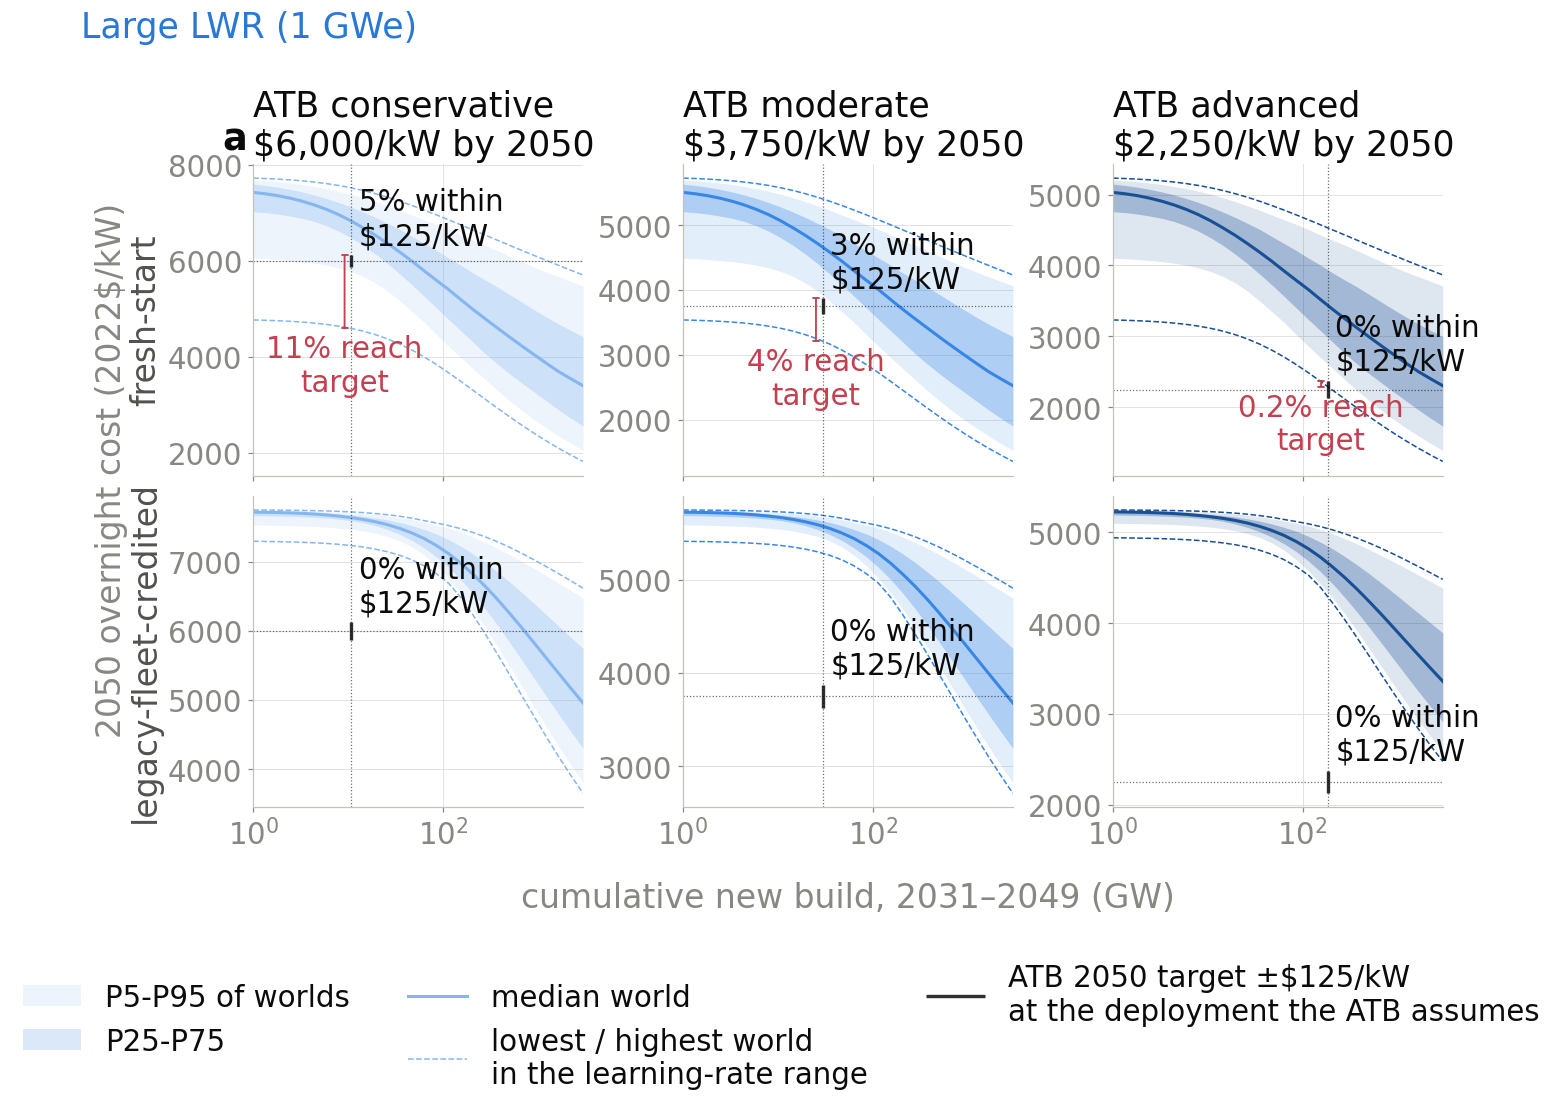

saved -> analysis\results\exports\02\atb_cost_deployment_plane_smr.png


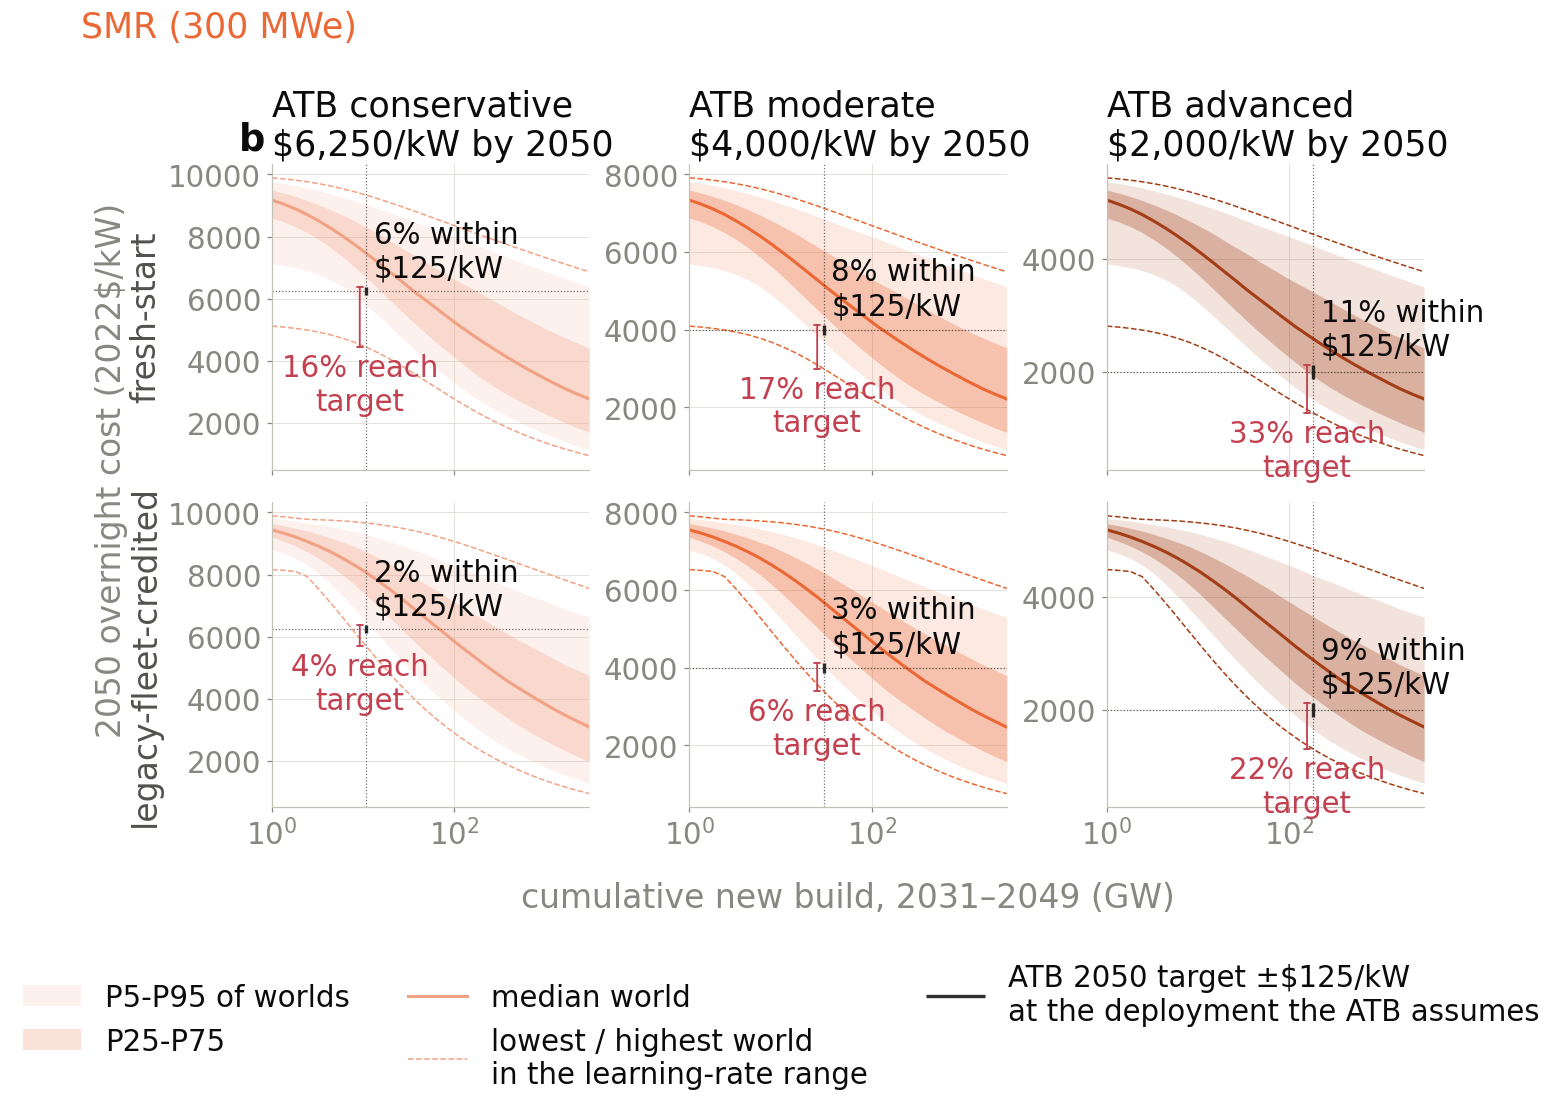

In [14]:
# F8 (Fig 1a/b, augmented 08-28) - the 2050 cost-deployment plane: the 2050 OCC each amount of
# cumulative building can buy, across the support-restricted grid worlds, with the ATB
# (paired deployment, 2050 cost) point overlaid. One figure per technology; rows = the
# experience-base strata (matching F3/F6); the quantile fan is over all grid worlds in the
# stratum with LR restricted to the MC sampled support (uniform grid weights over
# LR x s x u3 x m x rho, the Part-2 grid — no dial held fixed). The shape quantiles are
# computed once per stratum and scaled by each scenario's pinned anchor (quantiles commute
# with the positive per-scenario BOAK scaling).
# 08-28 (Ethan): Fig 1 = these two figures STACKED (a = large over b = smr); the endpoint
# maps (F9) leave the composition. Per panel: dashed P0/P100 envelope (lowest and highest
# supported world at each deployment) plus two reads at the paired deployment (second
# 08-28 spec, amended 08-29): a black bar spanning the target +-TOL_END band labeled
# with the stratum share of supported worlds inside the band (two-sided), and a red
# dimension bracket from the envelope floor to target + TOL_END labeled with the
# ONE-SIDED criterion share (OCC(2050) <= target + $125) - the S1 share itself, so
# panel and prose cannot drift; the bracket is omitted where that share is zero (the
# large legacy-fleet rows). The strictly-below read is retired (08-29). Both shares
# are SHAPES-based (the endpoint_feasible_share.csv population).
# 08-29 (Ethan): row labels de-jargonned - the internal stratum names (tiny-base /
# full-stock) stay out of paper-facing pixels; the descriptive labels match the
# Fig 1 caption (fresh-start / legacy-fleet-credited).
# 09-03 (Ethan, coauthor review): the remaining labels read in plain words - "occ",
# "supported world", "paired deployment", "reach" and the x label; no numeric change.
D_PLANE_GW = np.logspace(0.0, np.log10(3000.0), 28)          # 1 -> 3,000 GW by 2050

for tech in TECH:
    sup2 = (LR2 >= TECH[tech]["lr_lo"]) & (LR2 <= TECH[tech]["lr_hi"])
    sup1 = (P["lr"] >= TECH[tech]["lr_lo"]) & (P["lr"] <= TECH[tech]["lr_hi"])
    # 09-24 (Ethan E11): one type specification for the whole paper and its SI. The two
    # panels of this figure are stacked into SF42_atb_placement.png, 13.25 in wide, which
    # the page prints at 6.5 in; the sizes are scaled to that composed width so they PRINT
    # at plotstyle.PAPER_FONT.
    # 09-24, third pass: with the titles wrapped and the two axis labels shared, the panel
    # no longer overflows its grid, so its width returns to the canvas it asks for and the
    # stacked composite SF42_atb_placement.png is that plus one 0.16 in pad each side.
    # 09-24, fifth pass (agent SIF): SF42_atb_placement.png stays ONE composed item, and it
    # is height-capped - stacked it is 13.26 x 20.08 in, so the page prints it 5.68 in wide,
    # not 6.5, and the constant has to absorb that: 6.5 * 13.26 / 5.68 = 15.18.
    # 09-24, converged (agent SIF): SF42_atb_placement.png is ONE composed item and it is
    # HEIGHT-capped, so height feeds back as hard as width - a taller composite is printed
    # narrower and its type shrinks with it. The fixed point was solved on a layout
    # stand-in rather than by re-running this notebook: 15.60 gives a 14.7 x 20.7 in
    # composite, which the page prints 6.11 in wide, and the type lands at 8.0 pt.
    CW_SF2 = 15.60
    _PF2 = ps.fonts(CW_SF2)
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), sharex=True)
    for r, conv in enumerate(CONV_GRID):
        combos = [(rho, m) for (rho, cv, m) in DISC_COMBOS if cv == conv]
        lr = np.concatenate([LR2[sup2]] * len(combos))
        s = np.concatenate([S2[sup2]] * len(combos))
        u = np.concatenate([U2[sup2]] * len(combos))
        m = np.concatenate([np.full(int(sup2.sum()), mm) for _, mm in combos])
        rho = np.concatenate([np.full(int(sup2.sum()), rr) for rr, _ in combos])
        q = np.empty((len(D_PLANE_GW), 5))
        env = np.empty((len(D_PLANE_GW), 2))     # P0/P100: lowest/highest supported world
        for k, d in enumerate(D_PLANE_GW):
            sh = shape_2050(tech, lr, s, u, m, conv, rho, d / TECH[tech]["unit_gw"])
            q[k] = np.quantile(sh, [0.05, 0.25, 0.50, 0.75, 0.95])
            env[k] = sh.min(), sh.max()
        for c, scen in enumerate(SCEN_ORDER):
            ax = axes[r, c]
            occ_q = q * BOAK_PIN[tech][scen]
            occ_env = env * BOAK_PIN[tech][scen]
            col = SCEN_COLOR[tech][scen]
            ax.fill_between(D_PLANE_GW, occ_q[:, 0], occ_q[:, 4], color=col, alpha=0.14,
                            lw=0, label="P5-P95 of worlds")
            ax.fill_between(D_PLANE_GW, occ_q[:, 1], occ_q[:, 3], color=col, alpha=0.30,
                            lw=0, label="P25-P75")
            ax.plot(D_PLANE_GW, occ_q[:, 2], color=col, lw=2, label="median world")
            ax.plot(D_PLANE_GW, occ_env[:, 0], color=col, lw=1.0, ls="--",
                    label="lowest / highest world\nin the learning-rate range")
            ax.plot(D_PLANE_GW, occ_env[:, 1], color=col, lw=1.0, ls="--")
            t50, d_aj = TARGET[tech][scen][-1], AJ_GW_ENT50[scen]   # thru-2049 scoring basis
            ax.axhline(t50, color=INK, lw=0.8, ls=":", alpha=0.6)
            ax.axvline(d_aj, color=INK, lw=0.8, ls=":", alpha=0.6)
            # 08-29 (Ethan): the target dot is removed - the +-$125 bar below IS the
            # target marker (it sits exactly at the paired deployment and target).
            # Panel reads at the paired deployment (third spec, 08-29, Ethan): each label
            # reads off the geometry it annotates. Populations identical to
            # endpoint_feasible_share.csv (SHAPES-based, support-restricted stratum); the
            # red bracket carries the paper's ONE-SIDED criterion share directly.
            pred50 = BOAK_PIN[tech][scen] * SHAPES[(tech, scen)][:, -1].astype(np.float64)
            strat = sup1 & (P["conv_full"] == conv)
            share_band = float((np.abs(pred50[strat] - t50) <= TOL_END).mean())
            share_feas = float((pred50[strat] <= t50 + TOL_END).mean())
            # Envelope floor exactly at the paired deployment (not interpolated).
            sh_aj = shape_2050(tech, lr, s, u, m, conv, rho, d_aj / TECH[tech]["unit_gw"])
            floor_aj = float(sh_aj.min()) * BOAK_PIN[tech][scen]
            # Black bar: the +-TOL band around the target; label = share inside the band.
            ax.plot([d_aj, d_aj], [t50 - TOL_END, t50 + TOL_END], color=INK, lw=2.2, alpha=0.85,
                    solid_capstyle="butt", zorder=4,
                    label="ATB 2050 target ±$125/kW\nat the deployment the ATB assumes")
            ax.annotate(f"{100*share_band:.0f}% within\n$125/kW", (d_aj, t50 + TOL_END),
                        xytext=(5, 3), textcoords="offset points",
                        fontsize=_PF2["annotation"], color=INK, va="bottom")
            # Red dimension bracket (left of the bar): envelope floor -> the upper
            # tolerance bound (target + $125); label = the one-sided criterion share
            # (worlds at or below the bound). Omitted where that share is zero
            # (08-29 spec - the large legacy-fleet rows). Sub-1% shares keep one
            # decimal so the large-advanced 0.2% stays visible.
            if share_feas > 0:
                x_dim = d_aj * 0.85
                bound = t50 + TOL_END
                lo_d, hi_d = min(bound, floor_aj), max(bound, floor_aj)
                ax.annotate("", (x_dim, hi_d), xytext=(x_dim, lo_d),
                            arrowprops=dict(arrowstyle="|-|,widthA=0.22,widthB=0.22",
                                            color=ps.ACCENT["red"], lw=1.2,
                                            shrinkA=0, shrinkB=0))
                lbl = (f"{100*share_feas:.1f}%" if share_feas < 0.01
                       else f"{100*share_feas:.0f}%")
                # 09-24 (Ethan E11): centred UNDER the bracket, not right-aligned beside
                # it. At the printed type specification the two-line label is about 1.5 in
                # wide and has about 1.1 in between the bracket and the left spine, so
                # beside the bracket it ran over the y tick labels. The bracket, the share
                # it reports and its colour are unchanged.
                ax.annotate(lbl + " reach\ntarget", (x_dim, lo_d),
                            xytext=(0, -4), textcoords="offset points",
                            fontsize=_PF2["annotation"], color=ps.ACCENT["red"],
                            ha="center", va="top")
            ax.set_xscale("log")
            ax.set_xlim(1.0, 3000.0)
            if r == 0:
                # 09-24: wrapped, and the second line shortened from "(2050 target $N/kW)"
                # to "$N/kW by 2050". On one line the three titles of a row ran into each
                # other and past the grid; wrapped but still 23 characters, their second
                # lines ran into each other too, at 22.8 pt on a 3.9 in panel.
                ax.set_title(f"ATB {scen}\n${t50:,.0f}/kW by 2050",
                             fontsize=_PF2["panel_title"])
            if c == 0:
                # the stratum name alone; the unit moves to one shared y label (09-24)
                ax.set_ylabel("fresh-start" if conv == 0 else "legacy-fleet-credited",
                              fontsize=_PF2["axis_label"])
            ax.tick_params(axis="both", labelsize=_PF2["tick"])
    # Paper Fig 1 letters baked at source (house rule): "a" (large) / "b" (smr); the
    # composed Fig 1 stacks a over b since 08-28 (the F9 maps left the composition).
    ps.panel_letter(axes[0, 0], "a" if tech == "large" else "b",
                    size=_PF2["panel_letter"])
    # At the specification a six-entry legend does not fit inside a panel of this grid, so
    # the six panels share one below the figure (09-24, E11).
    _h2, _l2 = axes[0, 0].get_legend_handles_labels()
    # One shared y unit and one shared x label: at the specification each per-panel label is
    # longer than the panel it belongs to, so the six panels share both (09-24, E11).
    fig.supylabel("2050 overnight cost (2022$/kW)", fontsize=_PF2["axis_label"],
                  color=ps.FAINT)
    fig.tight_layout()
    _xc2 = 0.5 * (axes[1, 0].get_position().x0 + axes[1, 2].get_position().x1)
    fig.text(_xc2, -0.02, "cumulative new build, 2031–2049 (GW)", ha="center",
             va="top", fontsize=_PF2["axis_label"], color=ps.FAINT)
    fig.legend(_h2, _l2, ncol=3, fontsize=_PF2["legend"], frameon=False,
               loc="upper center", bbox_to_anchor=(0.5, -0.09))
    fig.suptitle(TECH_LABEL[tech], color=TECH_COLOR[tech], x=0.01, ha="left", y=1.08,
                 fontsize=_PF2["panel_title"])
    ps.savefig(fig, EXPORTS / f"atb_cost_deployment_plane_{tech}.png")
    plt.show()

**Composing Supplementary Fig. 2.** The two planes are stacked, large reactors (a) over SMRs
(b), at their native pixel size. Both source figures carry their own panel letters, so the
composition stamps none. The cell then prints the numbers the SF2 caption quotes: the
endpoint shares and the range of the minimum learning rate at the paired deployment.

composed -> analysis\results\figures\si\SF02_atb_placement.png  (4358x6206 px)


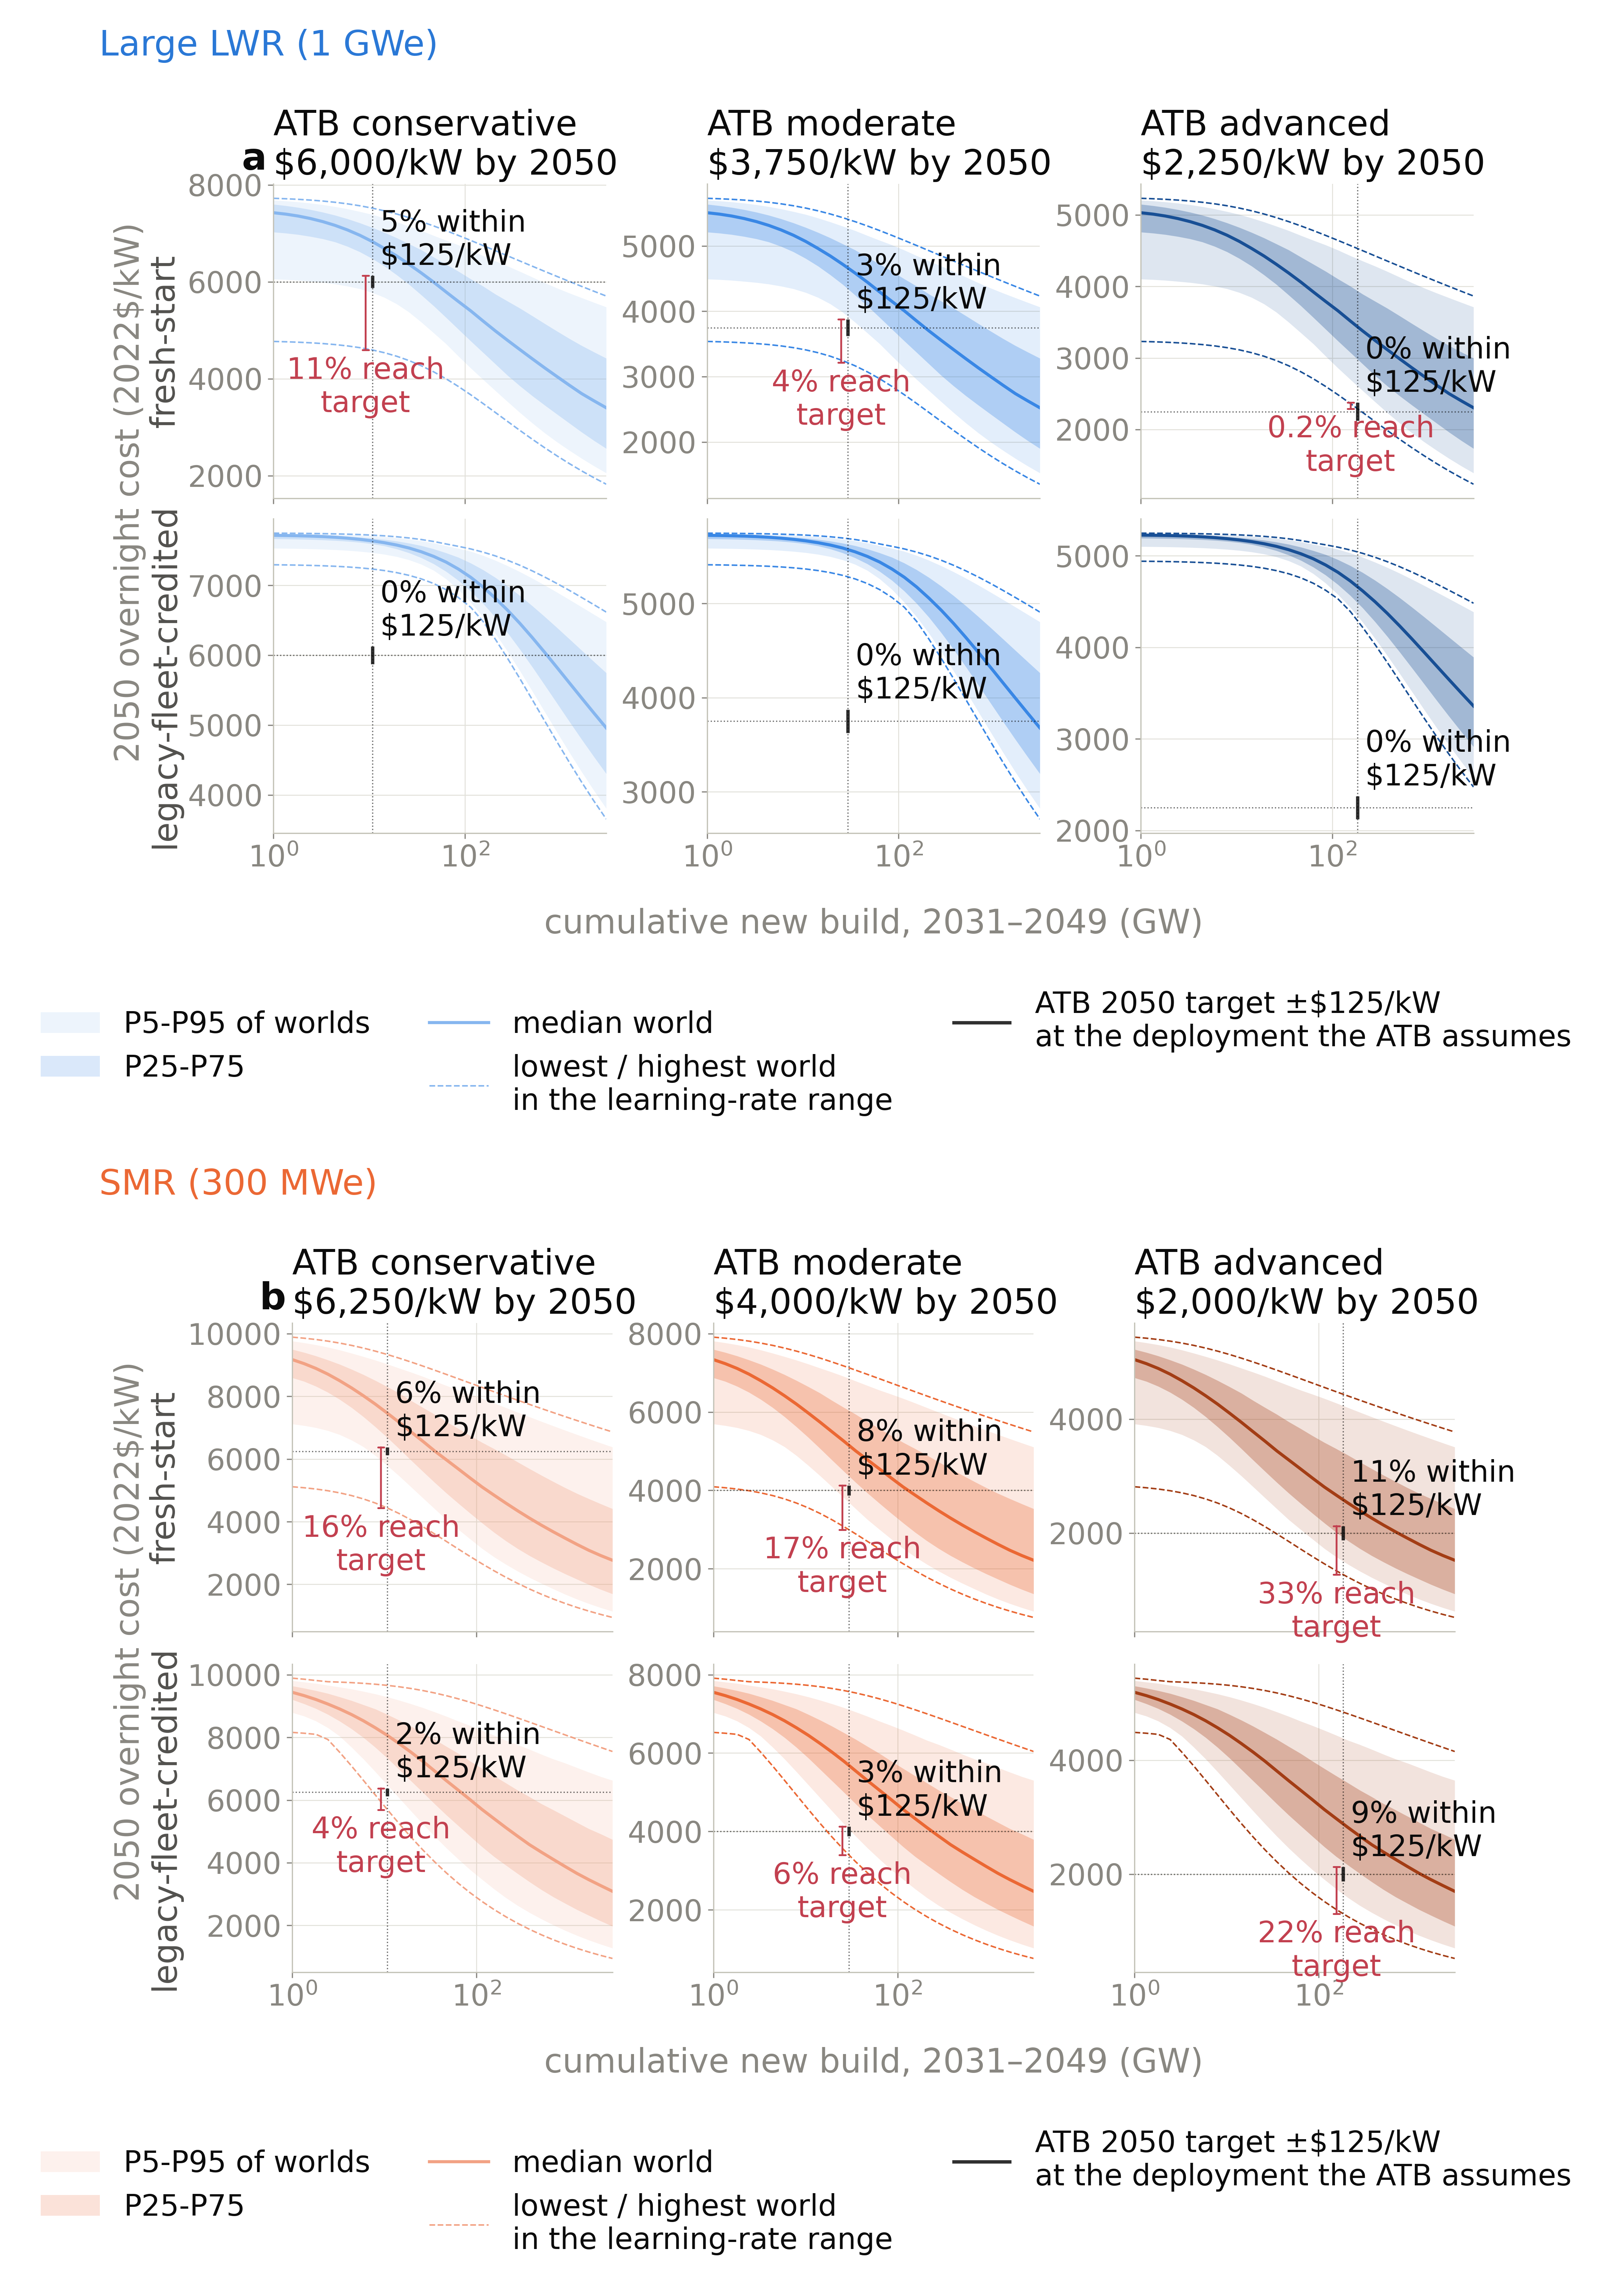

 tech     scenario  share_grid  share_support  share_support_tiny  share_support_full  share_support_twosided  share_support_milestone
large conservative      0.2784         0.0570              0.1140              0.0000                  0.0247                   0.0000
large     moderate      0.2754         0.0189              0.0377              0.0000                  0.0149                   0.0174
large     advanced      0.2769         0.0011              0.0021              0.0000                  0.0011                   0.0045
  smr conservative      0.4559         0.1003              0.1627              0.0379                  0.0396                   0.0032
  smr     moderate      0.4805         0.1137              0.1671              0.0604                  0.0546                   0.0086
  smr     advanced      0.5846         0.2744              0.3335              0.2153                  0.0986                   0.0003

min firm-level LR to reach the 2050 cost at the paired

In [15]:
compose(
    [[EXPORTS / "atb_cost_deployment_plane_large.png"],
     [EXPORTS / "atb_cost_deployment_plane_smr.png"]],
    "SF02_atb_placement.png", out_dir=paths.FIGS_SI,
    letters="",  # both sources carry their letters (a = large, b = smr); stacked a over b
    center=True,
)

es = pd.read_csv(ATB_OUT / "endpoint_feasible_share.csv")
print(es.to_string(index=False))
t5 = pd.read_csv(ATB_OUT / "min_lr_at_aj_deployment.csv")
tiny = t5[t5["base"] == "tiny"]
lr_cols = [c for c in t5.columns if c.startswith("min LR")]
lr_lo, lr_hi = tiny[lr_cols].min().min(), tiny[lr_cols].max().max()
print(f"\nmin firm-level LR to reach the 2050 cost at the paired deployment "
      f"(tiny base, central world): {lr_lo:.3f}-{lr_hi:.3f}")
lg, sm = es[es["tech"] == "large"], es[es["tech"] == "smr"]
assert float(lg["share_support_full"].max()) == 0.0, "no legacy-fleet-credited large world reaches any ATB 2050 cost"
print(f"support-restricted feasible shares (one-sided, $125 criterion; split by "
      f"experience accounting): fresh start smr "
      f"{100*sm['share_support_tiny'].min():.1f}-{100*sm['share_support_tiny'].max():.1f}%, "
      f"large {100*lg['share_support_tiny'].min():.1f}-{100*lg['share_support_tiny'].max():.1f}%; "
      f"legacy credited smr "
      f"{100*sm['share_support_full'].min():.1f}-{100*sm['share_support_full'].max():.1f}%, "
      f"large: 0 in all three scenarios")

## A6 — Synthesis and the remaining QA

`synthesis.csv` combines both reads per technology and scenario: whether the full ATB
trajectory is reproducible inside the Monte Carlo's sampled learning-rate support (a), only
outside it (b), or nowhere on the grid (c), next to the build that a central in-support world
needs to reach the 2050 cost (LR at mid-support, fresh-start, s = 0.5, u = 0.5, m = 6, ρ = 0).

The QA cell then runs the remaining checks:

- **QA-1** — the CES engine at ρ = 0 equals the reference geometric-mean engine exactly.
- **QA-2** — at s = 0, fresh-start, ρ = 0 the engine reduces to the source's learning
  equation (Abou-Jaoude eq. 12), generalised to m vendors.
- **QA-3 (the replication pin, Supplementary Note 1).** (i) The source's own eq. 12, at
  LR 9.5 % and four vendors, reproduces the ATB SMR cost tables within $500/kW (the report's
  rounding). (ii) The same setting run through this engine overshoots the 2050 targets, by
  $400–980/kW, because the 2030 convention re-anchors at each vendor's second unit; every ATB SMR
  trajectory still has fitting worlds inside the sampled learning-rate support.

In [16]:
# The synthesis table (T6): Part-1 feasibility verdict + Part-2 required deployment, per fit.
_rows = []
for tech in TECH:
    lr_mid = 0.5*(TECH[tech]["lr_lo"] + TECH[tech]["lr_hi"])
    for scen in SCEN_ORDER:
        f = FITS[(tech, scen)]
        sup = (P["lr"] >= TECH[tech]["lr_lo"]) & (P["lr"] <= TECH[tech]["lr_hi"])
        feas_any = f["mis"].min() <= TOL
        feas_sup = f["mis"][sup].min() <= TOL
        verdict = ("(a) inside MC support" if feas_sup else
                   "(b) outside support only" if feas_any else
                   "(c) not on the grid")
        ratio = TARGET[tech][scen][-1] / BOAK_PIN[tech][scen]
        d_ctr = required_gw(tech, ratio, lr_mid, 0.5, 0.5, 6.0, 0.0, 0.0).item()
        _rows.append({
            "tech": tech, "scenario": scen, "verdict": verdict,
            "min_misfit_grid_$kW": round(float(f["mis"].min()), 1),
            "min_misfit_support_$kW": round(float(f["mis"][sup].min()), 1),
            f"share_support_<=${TOL:.0f}": round(float((f['mis'][sup] <= TOL).mean()), 4),
            "AJ_deployment_GW": AJ_GW_POST[scen],
            "AJ_completed_2049_GW": round(AJ_GW_ENT50[scen], 1),
            "required_GW_central_world": (round(d_ctr, 1) if np.isfinite(d_ctr) else np.inf),
        })
synthesis = pd.DataFrame(_rows).set_index(["tech", "scenario"])
synthesis.to_csv(ATB_OUT / "synthesis.csv")
print("T6 - the RQ2 synthesis (central world = LR mid-support, tiny base, s=0.5, u=0.5, m=6, "
      "rho=0) -> exports/atb/synthesis.csv")
print(synthesis.to_string())

T6 - the RQ2 synthesis (central world = LR mid-support, tiny base, s=0.5, u=0.5, m=6, rho=0) -> exports/atb/synthesis.csv
                                     verdict  min_misfit_grid_$kW  min_misfit_support_$kW  share_support_<=$250  AJ_deployment_GW  AJ_completed_2049_GW  required_GW_central_world
tech  scenario                                                                                                                                                                    
large conservative  (b) outside support only                231.9                   277.4                0.0000              12.0                  10.8                       47.8
      moderate         (a) inside MC support                 78.9                   100.9                0.0174              33.0                  29.6                      191.4
      advanced         (a) inside MC support                 38.2                    79.0                0.0045             199.0                 183.8           

In [17]:
# QA-1 - CES(rho -> 0) == the sigma = 1 reference engine, on designed worlds spanning the grid
_rng1 = rng_stream("atb/qa1")
_n1 = 300
_wq = make_worlds(_rng1.uniform(0.005, 0.30, _n1), _rng1.uniform(4000, 10000, _n1),
                  _rng1.uniform(0, 1, _n1), _rng1.uniform(0, 1, _n1),
                  _rng1.integers(4, 9, _n1).astype(float),
                  _rng1.integers(0, 2, _n1).astype(float), 0.0)
for tech in TECH:
    a = occ_paths_ces(_wq, tech, N_AJ[tech]["advanced"], ces_rho=0.0)
    b = occ_paths(_wq, tech, N_AJ[tech]["advanced"])
    assert np.allclose(a, b, rtol=1e-12), tech
print("QA-1 PASSED: occ_paths_ces(rho=0) == occ_paths exactly on 300 designed worlds "
      "spanning the extended LR grid (both techs, AJ advanced deployment)")

# QA-2 - eq.(12) identity: at s = 0, tiny base, the engine equals generalized eq. (12),
# per-vendor re-anchored (the companion's QA3, on this notebook's own deployment inputs)
_wq2 = make_worlds(_rng1.uniform(0.005, 0.30, 4), 1.0, _rng1.uniform(0, 1, 4), 0.0,
                   _rng1.integers(4, 9, 4).astype(float), 0.0, 0.0)
_nus2 = N_AJ["smr"]["advanced"]
_m2q = _wq2["n_vendors"].values[:, None]
_N_ind = _m2q*N_BOAK_UNITS + lag1(np.broadcast_to(_nus2, (4, T)))   # engine prices lagged stock
_lr2 = _wq2["lr_smr"].values[:, None]
_analytic = eq12_gen(_N_ind, _lr2, _m2q) / eq12_gen(_m2q*N_BOAK_UNITS, _lr2, _m2q)
assert np.allclose(occ_paths(_wq2, "smr", _nus2), _analytic, rtol=1e-12)
print("QA-2 PASSED: engine reduces exactly to generalized eq.(12) at s=0, tiny base "
      "(SMR, AJ advanced deployment)")

# QA-3 - the published-source pin, two halves.
# (i) VERBATIM companion QA4: Abou-Jaoude's own eq. (12) at LR 9.5%, m=4 reproduces his
#     published SMR OCC tables (= the ATB SMR trajectories) within report rounding.
def eq12_factor(N, LR):
    N = np.asarray(N, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return (1/(1-LR)) * (1-LR)**np.log2(N/4) * (1-LR/3)**np.log2(3*N/4)

_worst = 0.0
for s in SCEN_ORDER:
    N = np.array([_aj_qa4[s][y] for y in MILESTONES], float) / 0.3
    fref = eq12_factor(1.0/0.3, 0.095)
    mult = np.minimum(1.0, np.where(N > 0, eq12_factor(N, 0.095)/fref, 1.0))
    boak = {"conservative": 10000.0, "moderate": 8000.0, "advanced": 5500.0}[s]
    _worst = max(_worst, float(np.abs(boak*mult - TARGET["smr"][s]).max()))
assert _worst <= 500.0, _worst
print(f"QA-3 (i) PASSED: Abou-Jaoude eq.(12) @ LR 9.5%, m=4 reproduces the ATB SMR tables, "
      f"max error ${_worst:,.0f}/kW (report rounding)")

# (ii) The same setting evaluated through THIS engine, whose 2030-anchor convention discards
#      pre-2030 experience and re-anchors at the per-vendor 2OAK point - so it needs a somewhat
#      higher LR than Abou-Jaoude's own 9.5% to deliver the same curve. Report the gap, and
#      assert the substantive claim: every SMR trajectory has feasible worlds INSIDE the MC's
#      sampled LR support at the paired deployment.
for s in SCEN_ORDER:
    prec = BOAK_PIN["smr"][s] * shape_2050("smr", 0.095, 0.0, 0.5, 4.0, 0.0, 0.0,
                                           AJ_GW_ENT50[s]/0.3)   # thru-2049 scoring basis
    print(f"    engine @ AJ precedent world, {s:12s}: OCC(2050) = ${float(prec):,.0f}/kW "
          f"vs ATB ${TARGET['smr'][s][-1]:,.0f}/kW")
for s in SCEN_ORDER:
    sup = (P["lr"] >= TECH["smr"]["lr_lo"]) & (P["lr"] <= TECH["smr"]["lr_hi"])
    assert (FITS[("smr", s)]["mis"][sup] <= TOL).any(), s
print("QA-3 (ii) PASSED: every ATB SMR trajectory is reachable within the MC's sampled LR "
      "support at the paired AJ deployment (the anchor-convention LR premium stays in-support)")

QA-1 PASSED: occ_paths_ces(rho=0) == occ_paths exactly on 300 designed worlds spanning the extended LR grid (both techs, AJ advanced deployment)
QA-2 PASSED: engine reduces exactly to generalized eq.(12) at s=0, tiny base (SMR, AJ advanced deployment)
QA-3 (i) PASSED: Abou-Jaoude eq.(12) @ LR 9.5%, m=4 reproduces the ATB SMR tables, max error $500/kW (report rounding)
    engine @ AJ precedent world, conservative: OCC(2050) = $7,228/kW vs ATB $6,250/kW
    engine @ AJ precedent world, moderate    : OCC(2050) = $4,885/kW vs ATB $4,000/kW
    engine @ AJ precedent world, advanced    : OCC(2050) = $2,402/kW vs ATB $2,000/kW
QA-3 (ii) PASSED: every ATB SMR trajectory is reachable within the MC's sampled LR support at the paired AJ deployment (the anchor-convention LR premium stays in-support)


# Section B — The literature comparison

**What this section does.** Several cost projections besides the ATB source are in wide use:
DOE's Liftoff report, MIT's bottom-up AP1000 and SMR projections (ANP-201) and Stewart &
Shirvan's eight architectures (ANP-194), INL's cost-reduction pathways study and its 2023
literature review, the EIA / Sargent & Lundy capital cost study, EPRI's pooled first- and
Nth-of-a-kind values, the IEA/NEA country estimates, the Breakthrough Institute's
endogenous-learning model, the IEA's 2025 SMR outlook, and Vanatta et al.'s industrial SMR
model. This section answers three questions in order: what each projection assumes (`c01`);
what each predicts, as every (cost, cumulative build) pair it publishes (`c02`, `c03`); and
where each sits in the engine's parameter space (`c04`–`c07`). Studies that give no (cost,
unit-count) pair are listed in a cite-only register (`c08`) and are never plotted or scored.

**How each estimate is placed.** Every published estimate is placed at the cumulative
deployment that its own source assumes, not at its calendar year. A cost that a source
reaches after 20 units is compared with the engine's cost after 20 units, so estimates are
read at a like deployment rather than a like year. The engine anchors each vendor's cost at
its second unit, so a source's cumulative unit N is post-anchor unit N − 2. Two reads of a
single-design series exist: read **R1** takes the source's units as the whole national
program, spread over the engine's m vendors; read **R2** gives each of the engine's vendors the
source's own count.

**The gates.** G0 is the engine-parity gate QA-0 of Section A. G0b checks the closed form at
any year. G1 and G1b re-assert that the digitized series reproduce the values the reports
state in their text. G2 re-derives Section A's feasible sets and endpoint shares from this
section's machinery. G3 runs the full engine through sample feasible worlds. The kill rules
record outcomes: K3 marks a series with no feasible world, K5 the cite-only studies. Every
gate and kill disposition goes to `c99_verdict.csv`.

In [18]:
# The verdict table starts with gate G0: QA-0 in Section A1 already ran the engine-parity check.
VERDICT = []                       # (kind, name, result, detail) rows -> c99_verdict.csv
VERDICT.append(("gate", "G0", "PASS", "ported engine reproduces mc_perdraw.npz (6 schedules x 2 techs, rtol 1e-9)"))

# Dollar years: deflator.csv gives Deflator(t) relative to 2004; X_2022 = X_y * D(y)/D(2022).
DEFL = pd.read_csv(paths.deflator_path())
DEFL.columns = ["t", "Deflator"]
DEFL = DEFL.set_index("t")["Deflator"]

def to2022(x, dollar_year):
    # Convert a $ amount stated in `dollar_year` dollars to 2022 dollars.
    return np.asarray(x, float) * float(DEFL.loc[int(dollar_year)]) / float(DEFL.loc[2022])

assert abs(to2022(8300, 2024) - 7749) < 5, to2022(8300, 2024)     # hand check: MIT 8,300 (2024$)
INK, MUTED, FAINT = ps.INK, ps.MUTED, ps.FAINT                     # Section B's grey tokens
print(f"2024$ -> 2022$: x{float(DEFL.loc[2024])/float(DEFL.loc[2022]):.4f};  "
      f"2019$ -> 2022$: x{float(DEFL.loc[2019])/float(DEFL.loc[2022]):.4f}")

2024$ -> 2022$: x0.9335;  2019$ -> 2022$: x1.1443


## B1 — The closed form at any year, and the scoring grid

The Section A evaluator `shape_2050` depends on the year only through the foreign experience
stock, so `shape_at(..., year)` evaluates the same algebra at any year. Gate G0b checks it
against the full engine at 2035, 2040, 2045 and 2050 on random worlds and random build paths.
The scoring grid is Section A4's grid: LR × s × three positions of u × m × experience base × ρ,
113,400 worlds, of which the Monte Carlo's learning-rate support keeps 35,910 (large) and
51,030 (SMR).

In [19]:
# shape_at: the closed form at ANY year (own code; algebra identical to shape_2050, the
# foreign stock indexed at the requested year). n = post-anchor US units ENTERING the
# price of `year` (completed through year-1, the engine's one-year lag).
def skv_at(u, year):
    gi = np.clip(np.rint(np.asarray(u, float) * (len(U_GRID)-1)).astype(int), 0, len(U_GRID)-1)
    return sum(THETA_KV[r] * REGION_STOCK[r][gi, yi(year) - 1] for r in REGIONS)

def shape_at(tech, lr, s, u, m, conv, rho, n, year):
    """OCC(year)/BOAK for a post-anchor stock of n units entering the price of `year`."""
    lr, s, m, conv, rho, n = np.broadcast_arrays(
        *[np.asarray(a, float) for a in (lr, s, m, conv, rho, n)])
    skv = np.broadcast_to(skv_at(u, year), lr.shape)
    hist_us = HIST_UNITS["US"] if tech == "large" else 0.0
    H_kv = conv*H_ALL_W
    own0 = N_BOAK_UNITS + conv*hist_us/m
    ownA = own0
    ownT = own0 + n/m
    othA = (m-1.0)*own0 + s*H_kv
    othT = (m-1.0)*own0 + n*(m-1.0)/m + s*(H_kv + skv)
    b1, b2 = np.log2(1.0 - lr), np.log2(1.0 - OMEGA*lr)
    b, w = -(b1 + b2), b1/(b1 + b2)
    geo = np.abs(rho) < CES_EPS
    rho_safe = np.where(geo, 1.0, rho)
    def _lnE(o, a):
        lnO, lnA = np.log(o), np.log(a)
        return np.where(geo, w*lnO + (1.0-w)*lnA,
                        lnO + np.log1p((1.0-w)*np.expm1(rho_safe*(lnA - lnO)))/rho_safe)
    return np.exp(-b*(_lnE(ownT, othT) - _lnE(ownA, othA)))

# G0b: shape_at == the full engine's column at 2035/2040/2045/2050 on random worlds and
# random (non-decreasing, zero through 2030) cumulative paths; and == shape_2050 at 2050.
_rng = rng_stream("lit/g0b")
_n = 400
_g = {"lr": _rng.uniform(0.005, 0.30, _n), "s": _rng.uniform(0, 1, _n), "u": _rng.uniform(0, 1, _n),
      "m": _rng.integers(4, 9, _n).astype(float), "conv": _rng.integers(0, 2, _n).astype(float),
      "rho": _rng.choice(CES_RHO_GRID, _n)}
_worst = 0.0
_t0 = _time.time()
for tech in TECH:
    for i in range(_n):
        flows = _rng.uniform(0.0, 1.0, T)
        flows[YEARS <= ANCHOR] = 0.0
        path = np.cumsum(flows)
        path *= _rng.uniform(0.0, 3000.0) / TECH[tech]["unit_gw"] / path[-1]
        w1 = make_worlds(_g["lr"][i:i+1], 1.0, _g["u"][i:i+1], _g["s"][i:i+1],
                         _g["m"][i:i+1], _g["conv"][i:i+1], _g["rho"][i:i+1])
        full = occ_paths_ces(w1, tech, path)[0]
        for y in (2035, 2040, 2045, 2050):
            closed = shape_at(tech, _g["lr"][i:i+1], _g["s"][i:i+1], _g["u"][i:i+1], _g["m"][i:i+1],
                              _g["conv"][i:i+1], _g["rho"][i:i+1], np.array([path[yi(y) - 1]]), y)[0]
            _worst = max(_worst, abs(full[yi(y)] - closed))
assert _worst < 1e-9, _worst
_v = shape_2050("smr", _g["lr"], _g["s"], _g["u"], _g["m"], _g["conv"], _g["rho"], _g["lr"]*1000)
_w = shape_at("smr", _g["lr"], _g["s"], _g["u"], _g["m"], _g["conv"], _g["rho"], _g["lr"]*1000, 2050)
assert np.array_equal(_v, _w)
print(f"G0b PASSED: shape_at == full engine at 2035/40/45/50 on {2*_n} random worlds x paths "
      f"(worst |diff| {_worst:.1e}); shape_at(2050) == shape_2050 exactly  [{_time.time()-_t0:.0f}s]")
VERDICT.append(("gate", "G0b", "PASS", f"closed form at any year == full engine, worst diff {_worst:.1e}"))

# The grids of Section A (A3 and A4), restated so this section reads on its own.
LR_GRID = np.round(np.arange(0.005, 0.3001, 0.005), 3)
S21 = np.round(np.linspace(0.0, 1.0, 21), 3)
U21 = U_GRID.copy()
M_GRID = np.array([4.0, 5.0, 6.0, 7.0, 8.0])
CONV_GRID = np.array([0.0, 1.0])
DISC_COMBOS = [(rho, conv, m) for rho in CES_RHO_GRID for conv in CONV_GRID for m in M_GRID]
U3 = np.array([0.0, 0.5, 1.0])
_m2 = np.meshgrid(LR_GRID, S21, U3, indexing="ij")
LR2, S2, U2 = (a.ravel() for a in _m2)
NP2 = LR2.size
G = {"lr": np.tile(LR2, len(DISC_COMBOS)), "s": np.tile(S2, len(DISC_COMBOS)),
     "u": np.tile(U2, len(DISC_COMBOS)),
     "rho": np.repeat([c[0] for c in DISC_COMBOS], NP2),
     "conv": np.repeat([c[1] for c in DISC_COMBOS], NP2),
     "m": np.repeat([c[2] for c in DISC_COMBOS], NP2)}
NG = G["lr"].size
G_SHAPE = (len(CES_RHO_GRID), len(CONV_GRID), len(M_GRID), len(LR_GRID), len(S21), len(U3))
assert NW == len(DISC_COMBOS) * len(LR_GRID) * len(S21) * len(U21) == 793_800, \
    "Section A's full-trajectory grid has 793,800 worlds per fit"
SUPPORT = {t: (G["lr"] >= TECH[t]["lr_lo"]) & (G["lr"] <= TECH[t]["lr_hi"]) for t in TECH}
print(f"Part-2 scoring grid: {NG:,} worlds (LR {len(LR_GRID)} x s {len(S21)} x u {len(U3)} x m {len(M_GRID)} "
      f"x base {len(CONV_GRID)} x rho {len(CES_RHO_GRID)}); support-restricted: "
      + ", ".join(f"{t} {int(SUPPORT[t].sum()):,}" for t in TECH))

G0b PASSED: shape_at == full engine at 2035/40/45/50 on 800 random worlds x paths (worst |diff| 0.0e+00); shape_at(2050) == shape_2050 exactly  [7s]
Part-2 scoring grid: 113,400 worlds (LR 60 x s 21 x u 3 x m 5 x base 2 x rho 3); support-restricted: large 35,910, smr 51,030


## B2 — The projections and what each assumes

**The data layer.** Hand-transcribed points live in `data/literature/lit_sources.csv` (each
row quotes its page or table). Series that exist only as figures were digitized: INL's
Figure 10, Stewart & Shirvan's Figures 2.24–2.25 and the IEA's Figures 2.4 and 2.11 are
vector graphics, so their values are exact up to the axis calibration; MIT's Figure 2 is a
raster, read against the chart's own gridlines (read error about $190/kW); Breakthrough's
Figure 2-6 is a raster, so only the 2050 end point of each curve is read. The Abou-Jaoude/ATB
rows are generated from `atb_targets.csv` (Section A2) and the deployment table, never
transcribed by hand. The INL 2023 literature review gives a parametric curve, generated here
from its published quartiles.

**Three conventions apply to every point.**
- *Band.* Each point carries the source's stated range where it gives one, the ATB's
  ±$125/kW rounding half-step for the Abou-Jaoude milestones, and ±10 % where the source gives
  a bare number. Digitized points add their read error.
- *Units.* A source's cumulative unit N is the engine's post-anchor unit N − 2. First- and
  second-of-a-kind points are kept in `c02` but never scored.
- *Dollars.* Every cost is converted to 2022 dollars with the fork's deflator table.

`c02_points_2022usd.csv` is the table of every point (Fig. 1 and Supplementary Fig. 1 draw
it); `c01` is the assumptions table; `c08` the cite-only register; `c03` the Wright learning
rate implied between consecutive scored points of each series, and the first-of-a-kind premium.

In [20]:
# Load and assemble every projection into one table of points (c02), in 2022 dollars with bands.
ATB_T = pd.read_csv(ATB_OUT / "atb_targets.csv", header=[0, 1], index_col=0)
AJ_CSV = LIT_DATA / "abou_jaoude_deployment_projections.csv"
_aj = pd.read_csv(AJ_CSV).set_index("year")
AJ_YEARS = _aj.index.values.astype(float)
MILESTONES = [2030, 2035, 2040, 2045, 2050]
AJ_GW = {s: _aj[s].values.astype(float) for s in SCEN_ORDER}
AJ_GW_POST = {s: AJ_GW[s][-1] - AJ_GW[s][0] for s in SCEN_ORDER}
AJ_GW_ENT50 = {s: float(np.interp(2049.0, AJ_YEARS, AJ_GW[s]) - AJ_GW[s][0]) for s in SCEN_ORDER}

def aj_units_entering(scen, tech, year):
    """Post-anchor AJ units ENTERING the price of `year` (builds through year-1; flows at or
    before 2030 zeroed - the sibling's N_AJ convention)."""
    gw = float(np.interp(year - 1, AJ_YEARS, AJ_GW[scen]) - AJ_GW[scen][0])
    return max(gw, 0.0) / TECH[tech]["unit_gw"]

rows = []
# --- Abou-Jaoude / ATB 2024: 2 techs x 3 scenarios x 5 milestones, paired with his deployment path
for tech in TECH:
    for scen in SCEN_ORDER:
        for y in MILESTONES:
            occ = float(ATB_T[(tech, scen)].loc[y])
            gw_post = float(AJ_GW[scen][list(AJ_YEARS).index(y)] - AJ_GW[scen][0])
            rows.append(dict(source_id="atb_aj", series_id=f"aj_{scen}", tech=tech, point_id=str(y),
                             label=f"ATB {scen} {y}", n_units=np.nan, n_post=aj_units_entering(scen, tech, y),
                             cum_gw=gw_post, year=y, occ=occ, occ_lo=occ - 125.0, occ_hi=occ + 125.0,
                             dollar_year=2022, basis="BOAK" if y == 2030 else "milestone", provenance="table",
                             band_rule="atb125", scored=1, read_set="R1", n_lo=np.nan, n_hi=np.nan,
                             note="ATB 2024 file value at the paired Abou-Jaoude deployment"))
# --- hand-transcribed points
src = pd.read_csv(LIT_DATA / "lit_sources.csv")
for r in src.itertuples(index=False):
    n = r.n_units
    npost = (n - N_BOAK_UNITS) if pd.notna(n) else np.nan
    scored = int(r.scored) and pd.notna(n) and (n > N_BOAK_UNITS) and (r.basis != "FOAK")   # A2: FOAK never scored
    rows.append(dict(source_id=r.source_id, series_id=r.series_id, tech=r.tech, point_id=r.point_id,
                     label=r.label, n_units=n, n_post=npost, cum_gw=r.cum_gw, year=r.year, occ=r.occ,
                     occ_lo=(r.occ_lo if pd.notna(r.occ_lo) else 0.9*r.occ),
                     occ_hi=(r.occ_hi if pd.notna(r.occ_hi) else 1.1*r.occ),
                     dollar_year=r.dollar_year, basis=r.basis, provenance=r.provenance,
                     band_rule=r.band_rule, scored=int(scored), read_set="R1,R2",
                     n_lo=r.n_units_lo, n_hi=r.n_units_hi, note=r.note))
# --- MIT ANP-201 Fig 2 (digitized raster); stated ranges where the text gives them (A1)
mit = pd.read_csv(LIT_DATA / "mit_anp201_fig2_digitized.csv")
MIT_RANGE = {("mit_ap1000_23gw", 2): (8300.0, 10375.0), ("mit_ap1000_23gw", 7): (4625.0, 4750.0)}
for r in mit.itertuples(index=False):
    lo, hi = MIT_RANGE.get((r.series_id, int(r.offering)), (0.9*r.occ, 1.1*r.occ))
    tech = "large" if "ap1000" in r.series_id else "smr"
    rows.append(dict(source_id="mit_anp201", series_id=r.series_id, tech=tech, point_id=f"o{r.offering}",
                     label=f"MIT {r.label}", n_units=r.n_units, n_post=r.n_units - N_BOAK_UNITS,
                     cum_gw=r.cum_gw, year=r.year, occ=r.occ, occ_lo=lo - r.read_err, occ_hi=hi + r.read_err,
                     dollar_year=2024, basis=("FOAK" if r.offering == 1 else "NOAK" if r.offering == 7 else "NEXT"),
                     provenance="digitized-raster",
                     band_rule=("stated+read" if (r.series_id, int(r.offering)) in MIT_RANGE else "pct10+read"),
                     scored=int(r.n_units > N_BOAK_UNITS), read_set="R1,R2", n_lo=np.nan, n_hi=np.nan,
                     note=f"{r.design}; year finished {r.year}; A6 unit mapping"))
# --- INL cost-pathways Fig 10 (digitized vector, exact): Scenario 1, plants 1-13
inl = pd.read_csv(LIT_DATA / "inl_pathways_fig10_digitized.csv")
for r in inl.itertuples(index=False):
    rows.append(dict(source_id="inl_pathways", series_id=r.series_id, tech="smr", point_id=f"plant{r.plant}",
                     label=f"INL {r.design} plant {r.plant}", n_units=r.n_units, n_post=r.n_units - N_BOAK_UNITS,
                     cum_gw=r.cum_gw, year=np.nan, occ=r.occ, occ_lo=0.9*r.occ - r.read_err,
                     occ_hi=1.1*r.occ + r.read_err, dollar_year=2022,
                     basis=("FOAK" if r.plant == 1 else "order-book"), provenance="digitized-vector",
                     band_rule="pct10+read", scored=int(r.n_units > N_BOAK_UNITS and r.plant > 1), read_set="R1,R2",
                     n_lo=np.nan, n_hi=np.nan, note=f"{r.design}; Scenario 1 (realistic, no ITC); A4 plant = units"))
# --- INL 2023 literature review: parametric Wright curve from its published quartiles (2019$)
REV = {"low": (4000.0, 1.3), "central": (6000.0, 1.6), "high": (7000.0, 2.1)}     # (BOAK, FOAK premium)
REV_LR = 0.10                                   # its worked example applies the mean 10% at both ends
REV_N = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64]
for tech in TECH:
    for N in REV_N:
        c = {k: b*p*(1.0 - REV_LR)**np.log2(N) for k, (b, p) in REV.items()}
        rows.append(dict(source_id="inl_litreview", series_id="inl_review", tech=tech, point_id=f"N{N}",
                         label=f"INL 2023 review N={N}", n_units=N, n_post=N - N_BOAK_UNITS,
                         cum_gw=N*TECH[tech]["unit_gw"], year=np.nan, occ=c["central"], occ_lo=c["low"],
                         occ_hi=c["high"], dollar_year=2019, basis=("FOAK" if N == 1 else "parametric"),
                         provenance="derived", band_rule="quartile", scored=int(N > N_BOAK_UNITS),
                         read_set="R1,R2", n_lo=np.nan, n_hi=np.nan,
                         note="Cost_N = BOAK x premium x (1-LR)^log2 N; low/central/high = its quartiles and premiums, LR 10%"))
# --- Stewart & Shirvan (MIT ANP-194) Figs 2.24 / 2.25 (digitized vector, exact): units 1-10, eight architectures (2018$)
ss = pd.read_csv(LIT_DATA / "mit_anp194_fig225_digitized.csv")
SS_LARGE = {"PWR12", "LPSR", "DC-PWR", "LASR", "LM-BWR"}
for r in ss.itertuples(index=False):
    tech = "large" if r.architecture in SS_LARGE else "smr"
    rows.append(dict(source_id="stewart_shirvan_2022", series_id=r.series_id, tech=tech, point_id=f"u{r.unit_index}",
                     label=f"S&S {r.architecture} unit {r.unit_index}", n_units=r.n_units, n_post=r.n_units - N_BOAK_UNITS,
                     cum_gw=r.cum_gw, year=np.nan, occ=r.occ, occ_lo=0.9*r.occ - r.read_err, occ_hi=1.1*r.occ + r.read_err,
                     dollar_year=2018, basis=("FOAK" if r.unit_index == 1 else "NOAK" if r.unit_index == 10 else "sequential"),
                     provenance="digitized-vector", band_rule="pct10+read", scored=int(r.n_units > N_BOAK_UNITS),
                     read_set="R1,R2", n_lo=np.nan, n_hi=np.nan, is_curve=False,
                     note=f"{r.design}; unit 1 = Fig 2.24 FOAK bar, units 2-10 = Fig 2.25 increments (A12)"))
# --- IEA 2025 Figs 2.4 / 2.11 (digitized vector): US-and-EU cost path paired with GLOBAL SMR capacity (A9)
iea = pd.read_csv(LIT_DATA / "iea_2025_digitized.csv", dtype={"figure": str})
IEA_UNIT_MW = 120.0                        # ">1,000 SMRs" at 120 GW (A9)
_us = iea[iea.region == "US and EU"]
IEA_LABEL = {"iea_steps": "STEPS", "iea_aps": "APS", "iea_nze": "NZE", "iea_high_smr": "High SMR Case"}
for sid in ("iea_steps", "iea_aps", "iea_nze", "iea_high_smr"):
    if sid == "iea_high_smr":                                     # based on the APS; own capacity path; 2040 = parity
        f30 = _us[(_us.series_id == "iea_aps") & (_us.year == 2030) & (_us.figure == "2.4")].iloc[0]
        f40 = _us[(_us.series_id == "iea_high_smr") & (_us.year == 2040)].iloc[0]
        gw30 = float(iea[(iea.series_id == "iea_aps") & (iea.year == 2030)].gw_global.iloc[0])
        seq = [(2030, f30.occ, f30.read_err, gw30), (2040, f40.occ, f40.read_err, f40.gw_global)]
    else:
        q = _us[(_us.series_id == sid) & (_us.figure == "2.4")].sort_values("year")
        seq = [(int(r.year), r.occ, r.read_err, r.gw_global) for r in q.itertuples()]
    for yr, occ, err, gw in seq:
        n = gw * 1000.0 / IEA_UNIT_MW
        rows.append(dict(source_id="iea_2025", series_id=sid, tech="smr", point_id=str(yr),
                         label=f"IEA 2025 {IEA_LABEL[sid]} {yr}", n_units=n, n_post=n - N_BOAK_UNITS, cum_gw=gw, year=yr,
                         occ=occ, occ_lo=0.9*occ - err, occ_hi=1.1*occ + err, dollar_year=2023,
                         basis=("FOAK" if yr == 2030 else "milestone"), provenance="digitized-vector", band_rule="pct10+read",
                         scored=int(yr > 2030), read_set="R1", n_lo=np.nan, n_hi=np.nan, is_curve=False,
                         note="US-and-EU cost path at GLOBAL SMR capacity; N = GW / 0.12 (A9); R1 only, outer bound"))
_lg = _us[(_us.series_id == "iea_large") & (_us.year == 2040) & (_us.figure == "2.4")].iloc[0]
rows.append(dict(source_id="iea_2025", series_id="iea_large", tech="large", point_id="2040", label="IEA 2025 large-scale reactor on time and budget (US and EU)",
                 n_units=np.nan, n_post=np.nan, cum_gw=np.nan, year=2040, occ=_lg.occ, occ_lo=0.9*_lg.occ, occ_hi=1.1*_lg.occ,
                 dollar_year=2023, basis="generic", provenance="digitized-vector", band_rule="pct10+read", scored=0, read_set="",
                 n_lo=np.nan, n_hi=np.nan, is_curve=False, note="Fig 2.4 large-scale reactor line, 2040-2050 level; unpaired reference"))
# --- Breakthrough 2022: eq. B-2 curve per (class x scenario) from unit 1 to the Fig 2-6 end point (A10); 2020$
bti = pd.read_csv(LIT_DATA / "bti_fig26_endpoints.csv")
for r in bti.itertuples(index=False):
    sid = f"bti_{r.tech.lower()}_{r.cost_case[0]}c{r.learning_case[0]}l"
    b = -np.log2(1.0 - r.lr)
    unit_mw = r.unit_gw * 1000.0
    n_end = float(r.n_units_2050)
    curve_n = [n for n in (1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048) if n < n_end]
    for N in curve_n:
        c = max(r.floor_2020usd, r.foak_2020usd * N ** (-b))
        rows.append(dict(source_id="bti_2022", series_id=sid, tech="smr", point_id=f"N{N}",
                         label=f"Breakthrough {r.tech} N={N}", n_units=N, n_post=N - N_BOAK_UNITS, cum_gw=N*r.unit_gw, year=np.nan,
                         occ=c, occ_lo=0.9*c, occ_hi=1.1*c, dollar_year=2020, basis=("FOAK" if N == 1 else "parametric"),
                         provenance="derived", band_rule="pct10", scored=0, read_set="", n_lo=np.nan, n_hi=np.nan, is_curve=(N > 1),
                         note=f"eq. B-2 with the $1,800 floor; FOAK {r.foak_2020usd:,.0f}, LR {r.lr:.0%}; not scored (curve)"))
    lo_c, hi_c = min(r.occ_2050_read, r.occ_2050_eq_b2), max(r.occ_2050_read, r.occ_2050_eq_b2)
    wide = abs(r.ratio_read - r.ratio_eq_b2) > 0.04
    rows.append(dict(source_id="bti_2022", series_id=sid, tech="smr", point_id="2050",
                     label=f"Breakthrough {r.tech} 2050 end point", n_units=n_end, n_post=n_end - N_BOAK_UNITS,
                     cum_gw=r.gw_2050, year=2050, occ=r.occ_2050_read,
                     occ_lo=0.9*(lo_c if wide else r.occ_2050_read), occ_hi=1.1*(hi_c if wide else r.occ_2050_read),
                     dollar_year=2020, basis="milestone", provenance="digitized-raster-manual",
                     band_rule=("pct10+eqB2" if wide else "pct10"), scored=int(n_end > N_BOAK_UNITS), read_set="R1,R2",
                     n_lo=float(r.gw_2050_lo / r.unit_gw), n_hi=float(r.gw_2050_hi / r.unit_gw), is_curve=False,
                     note=f"{r.scenario}; ratio read {r.ratio_read:.3f} vs eq. B-2 {r.ratio_eq_b2:.3f}; x read error +-{r.x_err_decade:.3f} decade; {r.note}"))
pts = pd.DataFrame(rows)
with pd.option_context("future.no_silent_downcasting", True):
    pts["is_curve"] = pts["is_curve"].fillna(False).astype(bool)
for col in ("occ", "occ_lo", "occ_hi"):
    pts[col + "_2022"] = [float(to2022(v, y)) for v, y in zip(pts[col], pts["dollar_year"])]
pts["paired"] = pts["cum_gw"].notna()
pts["dated"] = pts["year"].notna()
pts["year_mode"] = np.where(pts["dated"], "dated", "2050 (2030 bracket)")
pts = pts.sort_values(["tech", "source_id", "series_id", "cum_gw"], kind="stable").reset_index(drop=True)
pts.to_csv(EXPORTS / "c02_points_2022usd.csv", index=False)
n_sc = int(pts["scored"].sum())
print(f"c02: {len(pts)} points from {pts['source_id'].nunique()} sources, {pts['series_id'].nunique()} series; "
      f"{int(pts['paired'].sum())} paired with a deployment, {n_sc} scored -> exports/c02_points_2022usd.csv")
_show = pts[pts.paired][["series_id", "tech", "label", "n_units", "n_post", "cum_gw", "year", "occ", "dollar_year",
                         "occ_2022", "occ_lo_2022", "occ_hi_2022", "band_rule", "scored"]]
pd.set_option("display.width", 230)
print(_show.to_string(index=False, float_format=lambda v: f"{v:,.1f}"))
print("\nunpaired reference values (no deployment stated):")
print(pts[~pts.paired][["series_id", "tech", "label", "occ", "dollar_year", "occ_2022", "basis"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.0f}"))

# Gates G1 and G1b are re-asserted from the digitizers' records.
_cal = json.loads((LIT_DATA / "digitize_calib.json").read_text(encoding="utf-8"))
assert _cal["gate_G1"]["all_pass"], _cal["gate_G1"]
VERDICT.append(("gate", "G1", "PASS", f"{len(_cal['gate_G1']['checks'])} text anchors reproduced by the digitized series"))
print(f"\nG1 PASSED (re-asserted from data/literature/digitize_calib.json): {len(_cal['gate_G1']['checks'])} anchors")
_calb = json.loads((LIT_DATA / "digitize_calib_b.json").read_text(encoding="utf-8"))
assert _calb["gate_G1b"]["all_pass"], _calb["gate_G1b"]
VERDICT.append(("gate", "G1b", "PASS", f"{len(_calb['gate_G1b']['checks'])} anchors reproduced by the 09-08 digitized series"))
print(f"G1b PASSED (re-asserted from data/literature/digitize_calib_b.json): {len(_calb['gate_G1b']['checks'])} anchors")

c02: 339 points from 15 sources, 48 series; 331 paired with a deployment, 184 scored -> exports/c02_points_2022usd.csv
          series_id  tech                                                                       label  n_units  n_post  cum_gw    year      occ  dollar_year  occ_2022  occ_lo_2022  occ_hi_2022   band_rule  scored
        aj_advanced large                                                           ATB advanced 2030      NaN     0.0     0.0 2,030.0  5,250.0         2022   5,250.0      5,125.0      5,375.0      atb125       1
        aj_advanced large                                                           ATB advanced 2035      NaN    10.4    13.0 2,035.0  4,000.0         2022   4,000.0      3,875.0      4,125.0      atb125       1
        aj_advanced large                                                           ATB advanced 2040      NaN    48.2    57.0 2,040.0  3,000.0         2022   3,000.0      2,875.0      3,125.0      atb125       1
        aj_advanced large    

In [21]:
# c01 - the assumptions comparison (one column per source; the engine last).
asm = pd.read_csv(LIT_DATA / "lit_assumptions.csv")
asm.to_csv(EXPORTS / "c01_assumptions.csv", index=False)
_cols = ["citation", "dollar_year", "tech_scope", "model_form", "lr_stated", "unit_size_mw", "vendor_structure",
         "anchor_attachment", "foak_premium", "noak_definition", "spillover", "deployment_pairing",
         "duration_foak_mo", "duration_noak_mo", "figure_only"]
pd.set_option("display.max_colwidth", 70)
print("c01 - assumptions comparison -> exports/c01_assumptions.csv")
print(asm.set_index("source_id")[_cols].T.to_string())

c01 - assumptions comparison -> exports/c01_assumptions.csv
source_id                                                                                                                       atb_aj                                                                                     mit_anp201                                                                                                                                             inl_pathways                                                                                             doe_liftoff                                                                                       inl_litreview                                                                                                                                                                         eia_sl                                                                                                               epri                                            iea_nea_2020        

In [22]:
# c08 - the cite-only register (never plotted, never scored).
cite = pd.read_csv(LIT_DATA / "lit_cite_only.csv")
cite.to_csv(EXPORTS / "c08_cite_only.csv", index=False)
VERDICT.append(("kill", "K5", "CITE-ONLY", f"{len(cite)} studies listed in c08, none plotted or scored"))
pd.set_option("display.max_colwidth", 60)
print(f"c08 - {len(cite)} cite-only studies -> exports/c08_cite_only.csv")
print(cite[["cite_id", "pub_year", "kind", "why_not_plotted", "paper_role"]].to_string(index=False))

c08 - 21 cite-only studies -> exports/c08_cite_only.csv
                cite_id  pub_year                                  kind                                                                                        why_not_plotted                                                                      paper_role
          renteria_2025      2025                 cost-target inversion cost target (what cost is needed) rather than a cost projection (what cost is expected); no unit count I3 distinction (cost-requirement framing), next to Duan 2022 and Sepulveda 2018
              duan_2022      2022                    threshold analysis                                                       exogenous cost sweep; no deployment-cost pairing                                                                  I3 distinction
         sepulveda_2018      2018                    threshold analysis                                                       exogenous cost sweep; no deployment-cost pairing     

In [23]:
# c03 - implied learning rates: the Wright slope between consecutive scored points of each series,
# LR = 1 - (c2/c1)^(1/log2(N2/N1)), and the FOAK premium (first point / first scored point).
_rows = []
for (sid, tech), g in pts[pts.paired].groupby(["series_id", "tech"], sort=False):
    g = g.sort_values("cum_gw")
    sc = g[g.scored == 1]
    foak = g[g.basis == "FOAK"]
    if len(foak) and len(sc) and foak.iloc[0].point_id != sc.iloc[0].point_id:
        _rows.append(dict(series_id=sid, tech=tech, segment="FOAK premium",
                          n_from=float(foak.iloc[0].n_units), n_to=float(sc.iloc[0].n_units),
                          value=float(foak.iloc[0].occ_2022 / sc.iloc[0].occ_2022), unit="ratio"))
    if len(sc) < 2:
        continue                                                                  # K2
    nn = sc["n_post"].values + N_BOAK_UNITS if sid.startswith("aj_") else sc["n_units"].values
    cc = sc["occ_2022"].values
    for i in range(1, len(sc)):
        if nn[i] > nn[i-1] > 0:
            lr = 1.0 - (cc[i]/cc[i-1])**(1.0/np.log2(nn[i]/nn[i-1]))
            _rows.append(dict(series_id=sid, tech=tech, segment=f"{sc.iloc[i-1].label} -> {sc.iloc[i].label}",
                              n_from=nn[i-1], n_to=nn[i], value=lr, unit="LR per doubling"))
    if nn[-1] > nn[0] > 0:
        _rows.append(dict(series_id=sid, tech=tech, segment="overall (first scored -> last)",
                          n_from=nn[0], n_to=nn[-1],
                          value=1.0 - (cc[-1]/cc[0])**(1.0/np.log2(nn[-1]/nn[0])), unit="LR per doubling"))
c03 = pd.DataFrame(_rows)
c03.to_csv(EXPORTS / "c03_implied_rates.csv", index=False)
print("c03 - implied Wright learning rates per segment and FOAK premiums (Abou-Jaoude rows use post-anchor "
      "units + 2, his own per-vendor count would divide by m) -> exports/c03_implied_rates.csv")
print(c03[c03.segment.str.startswith("overall") | (c03.unit == "ratio")]
      .to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

c03 - implied Wright learning rates per segment and FOAK premiums (Abou-Jaoude rows use post-anchor units + 2, his own per-vendor count would divide by m) -> exports/c03_implied_rates.csv
      series_id  tech                        segment  n_from      n_to  value            unit
    aj_advanced large overall (first scored -> last)   2.000   185.800  0.122 LR per doubling
aj_conservative large overall (first scored -> last)   2.000    12.800  0.091 LR per doubling
    aj_moderate large overall (first scored -> last)   2.000    31.600  0.102 LR per doubling
 liftoff_ap1000 large                   FOAK premium   2.000     4.000  1.807           ratio
 liftoff_ap1000 large overall (first scored -> last)   4.000    15.000  0.258 LR per doubling
     inl_review large                   FOAK premium   1.000     3.000  1.182           ratio
     inl_review large overall (first scored -> last)   3.000    64.000  0.100 LR per doubling
mit_ap1000_23gw large                   FOAK premium   2.000

## B3 — Series styles

Figures 1 and SF1 draw every literature series in unlabelled grey, but a few series are
styled or skipped by identity (a series drawn as points only, the INL review's range band,
the out-of-scope microreactor, the Steigerwald parity illustration). The next cell holds that
style table and checks that every scored or paired series has an entry.

In [24]:
# Series styles. Fig 1 and SF1 read only the line-style field ("ls" = "none" means points
# only); the colours and labels identify each series in the per-source diagnostic figures.
STYLE = {
    "mit_ap1000_23gw": dict(color=ps.ACCENT["violet"], ls="-", marker="D", label="MIT ANP-201 AP1000, 23 GW program (digitized)"),
    "mit_smr_7gw":     dict(color=ps.ACCENT["violet"], ls="-", marker="D", label="MIT ANP-201 SMR, 7 GW program (digitized)"),
    "mit_smr_23gw":    dict(color=ps.ACCENT["violet"], ls="--", marker="d", label="MIT ANP-201 SMR, 23 GW program (digitized)"),
    "inl_pathways_A":  dict(color=ps.ACCENT["green"], ls="-", marker="s", label="INL cost pathways, Concept A 4x264 MW (digitized, exact)"),
    "inl_pathways_B":  dict(color=ps.ACCENT["green"], ls="--", marker="s", label="INL cost pathways, Concept B 1x311 MW (digitized, exact)"),
    "liftoff_ap1000":  dict(color=ps.ACCENT["gold"], ls="-", marker="^", label="DOE Liftoff 2024 AP1000 chain"),
    "liftoff_noak_target": dict(color=ps.ACCENT["red"], ls="none", marker="*", label="DOE Liftoff 2023 NOAK target (10-20 units)"),
    "inl_review":      dict(color=MUTED, ls="-", marker="", label="INL 2023 review, parametric (band = its quartiles)"),
    "steigerwald_parity": dict(color=INK, ls="none", marker="P", label="Steigerwald 2023 illustration (>3,000 SMRs to AP1000 $/kW)"),
    "vogtle_realized": dict(color=INK, ls="none", marker="o", label="Vogtle 3&4 realized"),
    "darlington_quote": dict(color=INK, ls="none", marker="o", label="Darlington BWRX-300 4-unit estimate (C$ converted)"),
}
for scen in SCEN_ORDER:
    STYLE[f"aj_{scen}"] = dict(color=None, ls="-", marker="o", label=f"ATB 2024 / Abou-Jaoude {scen}")
for arch, sid, mk in (("PWR12 1,147 MW", "ss_pwr12", "o"), ("LPSR 1,117 MW (AP1000-like)", "ss_lpsr", "s"),
                      ("DC-PWR 1,650 MW", "ss_dcpwr", "D"), ("LASR 1,400 MW (APR1400-like)", "ss_lasr", "^"),
                      ("LM-BWR 1,350 MW (ABWR-like)", "ss_lmbwr", "v"), ("MMNC 12x74 MW plant", "ss_mmnc", "o"),
                      ("NC-SMR 160 MW", "ss_ncsmr", "s"), ("SM-BWR 300 MW (BWRX-300-like)", "ss_smbwr", "D")):
    STYLE[sid] = dict(color=ps.ACCENT["green"], ls="-", marker=mk, label=f"Stewart & Shirvan 2022 {arch}, units 1-10 (digitized, exact)")
BTI_COL = {"smr": ps.ACCENT["green"], "htgr": ps.ACCENT["gold"], "artes": ps.ACCENT["violet"]}
BTI_MK = {"lcll": "o", "lchl": "s", "ucll": "D", "uchl": "^"}
BTI_NAME = {"smr": "SMR 150 MW", "htgr": "HTGR 80 MW", "artes": "ARTES 345 MW"}
for cls in BTI_COL:
    for sc, mk in BTI_MK.items():
        STYLE[f"bti_{cls}_{sc}"] = dict(color=BTI_COL[cls], ls=("-" if sc[0] == "l" else "--"), marker=mk,
                                        label=f"Breakthrough 2022 {BTI_NAME[cls]}, {'lower' if sc[0] == 'l' else 'upper'} cost / "
                                              f"{'high' if sc[2] == 'h' else 'low'} learning (eq. B-2 curve; 2050 end point read)")
for sid, mk, nm in (("iea_steps", "o", "STEPS"), ("iea_aps", "s", "APS"), ("iea_nze", "^", "NZE"), ("iea_high_smr", "D", "High SMR Case")):
    STYLE[sid] = dict(color=ps.ACCENT["red"], ls="-", marker=mk, label=f"IEA 2025 SMR {nm}, US-and-EU cost at global capacity (digitized, exact)")
for sid, mk, nm in (("vanatta_ipwr", "o", "iPWR 77 MW"), ("vanatta_pbr", "s", "PBR-HTGR 80 MW"), ("vanatta_vhtr", "^", "VHTR 164 MW"),
                    ("vanatta_micro", "x", "microreactor 6.7 MW (out of scope, not scored)")):
    STYLE[sid] = dict(color=ps.ACCENT["red"], ls="-", marker=mk, label=f"Vanatta et al. 2024 {nm}, 2050 learned cost by module count")
_paired_ids = set(pts.loc[pts.paired, "series_id"])
assert _paired_ids <= set(STYLE), f"paired series without a style: {_paired_ids - set(STYLE)}"
print(f"{len(STYLE)} series styles; every paired series ({len(_paired_ids)}) has one")

42 series styles; every paired series (42) has one


## B4 — Where each projection sits in the engine's parameter space

**What this computes.** For each series and each scored point, the closed form gives the
cost shape (cost divided by the anchor cost) at that point's cumulative units, for every one
of the 113,400 grid worlds. Because cost = anchor × shape, a world reproduces a point when
the anchor lies in [band low ÷ shape, band high ÷ shape]. A world reproduces the *series* when
those intervals intersect each other and the Monte Carlo's anchor range. No fitting loop is
involved. Dated points are scored at their year; undated series are scored at 2050 (the Fig. 1
basis) with 2030 as the bracket. The Abou-Jaoude series is scored under R1 only, at ±$125 and,
as a labelled sensitivity, at Section A3's ±$250 trajectory tolerance; neither is the paper's
one-sided endpoint criterion.

**Outputs.** `c04_feasible_shares.csv` gives the feasible share per series, read and year
mode (over the grid, within the learning-rate support, and split by experience base), and the
nearest miss in anchor dollars where no world fits; `c05_parameter_ranges.csv` gives the range of
every dial over the feasible set; `c07_implied_boak.csv` the implied anchor interval. Gate G2
(`c06`) re-derives Section A's six feasible sets and endpoint shares and requires exact
agreement. Gate G3 runs the full engine through up to eight feasible worlds per series and
requires every cost to stay inside its band.

In [25]:
# The scoring machinery.
def score_series(g, tech, read, year_mode):
    """Feasibility of every grid world for the scored points of one series.
    Returns (feasible mask, implied BOAK lo, implied BOAK hi, nearest-miss $ in anchor dollars)."""
    B_lo = np.full(NG, -np.inf)
    B_hi = np.full(NG, np.inf)
    for r in g.itertuples():
        n = float(r.n_post) * (G["m"] if read == "R2" else 1.0)
        yr = min(int(r.year), 2050) if pd.notna(r.year) else (2050 if year_mode == "2050" else 2030)   # A3: post-2050 -> 2050 stock
        sh = shape_at(tech, G["lr"], G["s"], G["u"], G["m"], G["conv"], G["rho"], n, yr)
        if year_mode == "dated (+-250)":              # AJ sensitivity: the sibling's trajectory tolerance
            lo_k, hi_k = r.occ_2022 - 250.0, r.occ_2022 + 250.0
        else:
            lo_k, hi_k = r.occ_lo_2022, r.occ_hi_2022
        B_lo = np.maximum(B_lo, lo_k/sh)
        B_hi = np.minimum(B_hi, hi_k/sh)
    lo = np.maximum(B_lo, TECH[tech]["boak_lo"])
    hi = np.minimum(B_hi, TECH[tech]["boak_hi"])
    feas = lo <= hi
    return feas, lo, hi, np.where(feas, 0.0, lo - hi)

SERIES = [(sid, tech, g) for (sid, tech), g in pts[pts.paired & (pts.scored == 1)].groupby(["series_id", "tech"], sort=False)]
RUNS = []             # (sid, tech, read, year_mode) -> results
for sid, tech, g in SERIES:
    reads = ["R1"] if sid.startswith(("aj_", "iea_")) else ["R1", "R2"]      # IEA: global program, R1 only (A9)
    modes = (["dated", "dated (+-250)"] if sid.startswith("aj_") else ["dated"]) if g["dated"].all() else ["2050", "2030"]
    for read in reads:
        for mode in modes:
            RUNS.append((sid, tech, read, mode))
RES = {}
_t0 = _time.time()
for key in RUNS:
    sid, tech, read, mode = key
    g = [x for x in SERIES if x[0] == sid and x[1] == tech][0][2]
    RES[key] = score_series(g, tech, read, mode)
print(f"scored {len(RUNS)} series x read x year-mode combinations on {NG:,} worlds in {_time.time()-_t0:.0f}s")

_rows, _rng5 = [], []
_q = lambda a: (np.nan,)*5 if a.size == 0 else tuple(np.quantile(a, [0, .25, .5, .75, 1]))
DIALS = {"lr": G["lr"], "s": G["s"], "u": G["u"], "m": G["m"], "conv": G["conv"], "rho": G["rho"]}
for key in RUNS:
    sid, tech, read, mode = key
    feas, lo, hi, miss = RES[key]
    sup = SUPPORT[tech]
    g = [x for x in SERIES if x[0] == sid and x[1] == tech][0][2]
    _rows.append(dict(series_id=sid, tech=tech, read=read, year_mode=mode, n_points=len(g),
                      n_feasible=int(feas.sum()), share_grid=feas.mean(), share_support=feas[sup].mean(),
                      share_support_fresh=feas[sup & (G["conv"] == 0)].mean(),
                      share_support_legacy=feas[sup & (G["conv"] == 1)].mean(),
                      nearest_miss_usd=(0.0 if feas.any() else float(miss.min()))))
    row = dict(series_id=sid, tech=tech, read=read, year_mode=mode, n_feasible=int(feas.sum()))
    for d, arr in DIALS.items():
        row.update(dict(zip([f"{d}_min", f"{d}_q25", f"{d}_med", f"{d}_q75", f"{d}_max"], _q(arr[feas]))))
    row.update(dict(zip(["boak_min", "boak_q25", "boak_med", "boak_q75", "boak_max"],
                        _q(0.5*(lo[feas] + hi[feas])))))
    row["boak_interval_min"] = float(lo[feas].min()) if feas.any() else np.nan
    row["boak_interval_max"] = float(hi[feas].max()) if feas.any() else np.nan
    _rng5.append(row)
c04 = pd.DataFrame(_rows)
c05 = pd.DataFrame(_rng5)
c04.to_csv(EXPORTS / "c04_feasible_shares.csv", index=False)
c05.to_csv(EXPORTS / "c05_parameter_ranges.csv", index=False)
c05[["series_id", "tech", "read", "year_mode", "n_feasible", "boak_interval_min", "boak_interval_max", "boak_med"]] \
    .to_csv(EXPORTS / "c07_implied_boak.csv", index=False)
for key in RUNS:                                                                        # K3
    sid, tech, read, mode = key
    if not RES[key][0].any():
        VERDICT.append(("kill", "K3", "OUTSIDE-SAMPLED-SPACE",
                        f"{sid}/{tech}/{read}/{mode}: no feasible world; nearest miss ${RES[key][3].min():,.0f} of anchor"))
print("\nc04 - feasible-world shares per series x read x year mode (share_support = within the MC's "
      "sampled learning-rate support) -> exports/c04_feasible_shares.csv")
print(c04.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))
print("\nc05 - dial ranges over the feasible set (min / median / max shown) -> exports/c05_parameter_ranges.csv")
_short = c05[["series_id", "tech", "read", "year_mode", "n_feasible"] +
             [f"{d}_{q}" for d in ("lr", "s", "u", "m", "conv") for q in ("min", "med", "max")] +
             ["boak_interval_min", "boak_interval_max"]]
print(_short.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

scored 110 series x read x year-mode combinations on 113,400 worlds in 33s



c04 - feasible-world shares per series x read x year mode (share_support = within the MC's sampled learning-rate support) -> exports/c04_feasible_shares.csv
          series_id  tech read     year_mode  n_points  n_feasible  share_grid  share_support  share_support_fresh  share_support_legacy  nearest_miss_usd
        aj_advanced large   R1         dated         5         485      0.0043         0.0004               0.0007                0.0000            0.0000
        aj_advanced large   R1 dated (+-250)         5        3500      0.0309         0.0045               0.0091                0.0000            0.0000
    aj_conservative large   R1         dated         5           0      0.0000         0.0000               0.0000                0.0000          149.7848
    aj_conservative large   R1 dated (+-250)         5          87      0.0008         0.0000               0.0000                0.0000            0.0000
        aj_moderate large   R1         dated         5        3197 

In [26]:
# G2 - the Abou-Jaoude regression against Section A's exports, on Section A3's grid.
_mesh = np.meshgrid(LR_GRID, S21, U21, indexing="ij")
LRv, Sv, Uv = (a.ravel() for a in _mesh)
NPTS = LRv.size
P1 = {"lr": np.tile(LRv, len(DISC_COMBOS)), "s": np.tile(Sv, len(DISC_COMBOS)), "u": np.tile(Uv, len(DISC_COMBOS)),
      "ces_rho": np.repeat([c[0] for c in DISC_COMBOS], NPTS),
      "conv_full": np.repeat([c[1] for c in DISC_COMBOS], NPTS),
      "n_vendors": np.repeat([c[2] for c in DISC_COMBOS], NPTS)}
TOL, TOL_END = 250.0, 125.0
end_share = pd.read_csv(ATB_OUT / "endpoint_feasible_share.csv").set_index(["tech", "scenario"])
_rows = []
_t0 = _time.time()
for tech in TECH:
    sup = (P1["lr"] >= TECH[tech]["lr_lo"]) & (P1["lr"] <= TECH[tech]["lr_hi"])
    for scen in SCEN_ORDER:
        boak = float(ATB_T[(tech, scen)].loc[2030])
        pred = {}
        for y in MILESTONES[1:]:
            n = aj_units_entering(scen, tech, y)
            pred[y] = boak * shape_at(tech, P1["lr"], P1["s"], P1["u"], P1["n_vendors"], P1["conv_full"],
                                      P1["ces_rho"], n, y)
        mis = np.max([np.abs(pred[y] - float(ATB_T[(tech, scen)].loc[y])) for y in MILESTONES[1:]], axis=0)
        feas = mis <= TOL
        ref = pd.read_csv(ATB_OUT / f"feasible_set_{tech}_{scen}.csv.gz")
        mine = pd.DataFrame({k: P1[k][feas] for k in P1})
        key = ["lr", "s", "u", "ces_rho", "conv_full", "n_vendors"]
        merged = mine.round(4).merge(ref[key].round(4), on=key, how="outer", indicator=True)
        same = (len(mine) == len(ref)) and (merged["_merge"] == "both").all()
        t50 = float(ATB_T[(tech, scen)].loc[2050])
        gap = np.maximum(pred[2050] - t50, 0.0) <= TOL_END
        two = np.abs(pred[2050] - t50) <= TOL_END
        e = end_share.loc[(tech, scen)]
        ok_end = (abs(round(gap.mean(), 4) - e["share_grid"]) < 1e-4 and
                  abs(round(gap[sup].mean(), 4) - e["share_support"]) < 1e-4 and
                  abs(round(two[sup].mean(), 4) - e["share_support_twosided"]) < 1e-4)
        _rows.append(dict(tech=tech, scenario=scen, n_feasible_mine=len(mine), n_feasible_sibling=len(ref),
                          set_identical=bool(same), share_grid_mine=round(gap.mean(), 4), share_grid_sibling=e["share_grid"],
                          share_support_mine=round(gap[sup].mean(), 4), share_support_sibling=e["share_support"],
                          twosided_mine=round(two[sup].mean(), 4), twosided_sibling=e["share_support_twosided"],
                          endpoint_shares_match=bool(ok_end)))
c06 = pd.DataFrame(_rows)
c06.to_csv(EXPORTS / "c06_aj_regression.csv", index=False)
print(f"G2 regression on {NPTS*len(DISC_COMBOS):,} worlds in {_time.time()-_t0:.0f}s -> exports/c06_aj_regression.csv")
print(c06.to_string(index=False))
assert c06["set_identical"].all() and c06["endpoint_shares_match"].all(), "G2 FAILED"
print("G2 PASSED: feasible sets identical to the sibling's exports (6/6) and endpoint shares match to 4 dp")
VERDICT.append(("gate", "G2", "PASS", "AJ feasible sets + endpoint shares reproduce mc/exports/atb exactly"))

G2 regression on 793,800 worlds in 14s -> exports/c06_aj_regression.csv
 tech     scenario  n_feasible_mine  n_feasible_sibling  set_identical  share_grid_mine  share_grid_sibling  share_support_mine  share_support_sibling  twosided_mine  twosided_sibling  endpoint_shares_match
large conservative              403                 403           True           0.2784              0.2784              0.0570                 0.0570         0.0247            0.0247                   True
large     moderate            41190               41190           True           0.2754              0.2754              0.0189                 0.0189         0.0149            0.0149                   True
large     advanced            19789               19789           True           0.2769              0.2769              0.0011                 0.0011         0.0011            0.0011                   True
  smr conservative             4621                4621           True           0.4559             

In [27]:
# G3 - self-consistency: the full engine, run on a path that delivers each point's stock, lands
# inside the point's band for 8 random feasible worlds per scored series (primary read/mode).
_rng3 = rng_stream("lit/g3")
_worst, _checked = 0.0, 0
for key in RUNS:
    sid, tech, read, mode = key
    if mode in ("2030", "dated (+-250)") or read == "R2":
        continue
    feas, lo, hi, _ = RES[key]
    idx = np.flatnonzero(feas)
    if idx.size == 0:
        continue
    g = [x for x in SERIES if x[0] == sid and x[1] == tech][0][2]
    for w in _rng3.choice(idx, size=min(8, idx.size), replace=False):
        boak = 0.5*(lo[w] + hi[w])
        w1 = make_worlds([G["lr"][w]], boak, [G["u"][w]], [G["s"][w]], [G["m"][w]], [G["conv"][w]], [G["rho"][w]])
        for r in g.itertuples():
            yr = min(int(r.year), 2050) if pd.notna(r.year) else 2050
            n_end = float(r.n_post)
            ramp = np.where(YEARS <= ANCHOR, 0.0, np.minimum((YEARS - ANCHOR)/(yr - 1 - ANCHOR), 1.0)) * n_end \
                if yr - 1 > ANCHOR else np.zeros(T)
            occ = occ_paths_ces(w1, tech, ramp)[0, yi(yr)]
            _worst = max(_worst, max(r.occ_lo_2022 - occ, occ - r.occ_hi_2022, 0.0))
            _checked += 1
assert _worst < 1e-6, _worst
print(f"G3 PASSED: {_checked} (world, point) checks; the full engine never leaves the band the closed form "
      f"placed it in (worst excursion ${_worst:.1e})")
VERDICT.append(("gate", "G3", "PASS", f"{_checked} full-engine checks inside band"))

G3 PASSED: 1208 (world, point) checks; the full engine never leaves the band the closed form placed it in (worst excursion $0.0e+00)


## B5 — The engine against the literature (Supplementary Fig. 1 and the Fig. 1 source)

**The fans.** For each technology and experience base, the next cell evaluates the 2050 cost
over the support-restricted grid worlds at 32 cumulative builds from 0.05 to 3,000 GW, with the
anchor drawn across the Monte Carlo's 2030 anchor range (11 evenly spaced values). The fans are
the 5th–95th and 25th–75th percentiles and the median of those costs; the envelope is the
lowest and highest cost any supported world reaches with the anchor anywhere in its range.

**Supplementary Fig. 1 (e10)** has four panels: columns are the technologies, rows the
experience bases. The engine's fans are in colour. Every literature series is drawn in
unlabelled grey at its own cumulative build: connected points for sources that pair cost with
a unit count, dotted horizontal lines for published values with no deployment attached (EIA,
EPRI, IEA/NEA, the IEA large-reactor path). The ATB source's 2030 anchors (zero post-2030
build) sit at 0.1 GW on the log axis. The INL review's range band, the out-of-scope
microreactor and the Steigerwald parity illustration are omitted.

**Fig. 1 (e11)** is the two-panel version: one panel per technology, the fans pooled over both
experience bases (the grid holds them in equal numbers, as the Monte Carlo samples them). Three
display choices differ from e10. The x axis counts **units** of domestic build experience
after 2030 (1.0 GW per large reactor, 0.3 GW per SMR) on a symmetric-log scale whose linear
range ends at one unit, so zero experience plots at zero and the fans start there. Costs are
shown in 2025 dollars (`plotstyle.to2025(2022)`); every export stays in 2022 dollars. The ATB
source's 2030 points sit at the experience that source starts from, set by the dial
**`AJ_X_UNITS_2030 = {"smr": 0.83, "large": 0.5}`**: the source attaches its SMR cost at its
first 1 GW (3.33 units of 0.3 GW, or 0.83 units per vendor across four vendors) and its large
cost at industry unit 2 (0.5 per vendor). The figure draws the per-vendor numbers. The
industry-wide equivalents are {"smr": 3.33, "large": 2.0}. The cell asserts that the pooled
median lies between the two per-stratum medians at every build.

In [28]:
# The engine's 2050 fans over the support-restricted worlds AND the anchor prior, per experience
# base (the construction of e10 and e11; the per-group e06 figures are not drawn here).
# D_PLANE_GW_LIT is this section's build grid (0.05-3,000 GW); Section A5 uses its own D_PLANE_GW_LIT.
D_PLANE_GW_LIT = np.logspace(np.log10(0.05), np.log10(3000.0), 32)
BOAK_Q = {t: np.linspace(TECH[t]["boak_lo"], TECH[t]["boak_hi"], 11) for t in TECH}
_FAN = {}
for tech in TECH:
    for conv in CONV_GRID:
        strat = SUPPORT[tech] & (G["conv"] == conv)
        q = np.empty((len(D_PLANE_GW_LIT), 5))
        for k, d in enumerate(D_PLANE_GW_LIT):
            sh = shape_2050(tech, G["lr"][strat], G["s"][strat], G["u"][strat], G["m"][strat], conv,
                            G["rho"][strat], d / TECH[tech]["unit_gw"])
            q[k] = np.quantile(np.outer(BOAK_Q[tech], sh).ravel(), [0.05, 0.25, 0.5, 0.75, 0.95])
        _FAN[(tech, conv)] = q
_ENV = {}
for tech in TECH:
    for conv in CONV_GRID:
        strat = SUPPORT[tech] & (G["conv"] == conv)
        env = np.empty((len(D_PLANE_GW_LIT), 2))
        for k, d in enumerate(D_PLANE_GW_LIT):
            sh = shape_2050(tech, G["lr"][strat], G["s"][strat], G["u"][strat], G["m"][strat], conv,
                            G["rho"][strat], d / TECH[tech]["unit_gw"])
            allc = np.outer(BOAK_Q[tech], sh).ravel()
            env[k] = (allc.min(), allc.max())
        _ENV[(tech, conv)] = env

saved -> analysis\results\figures\si\SF01_engine_vs_literature.png


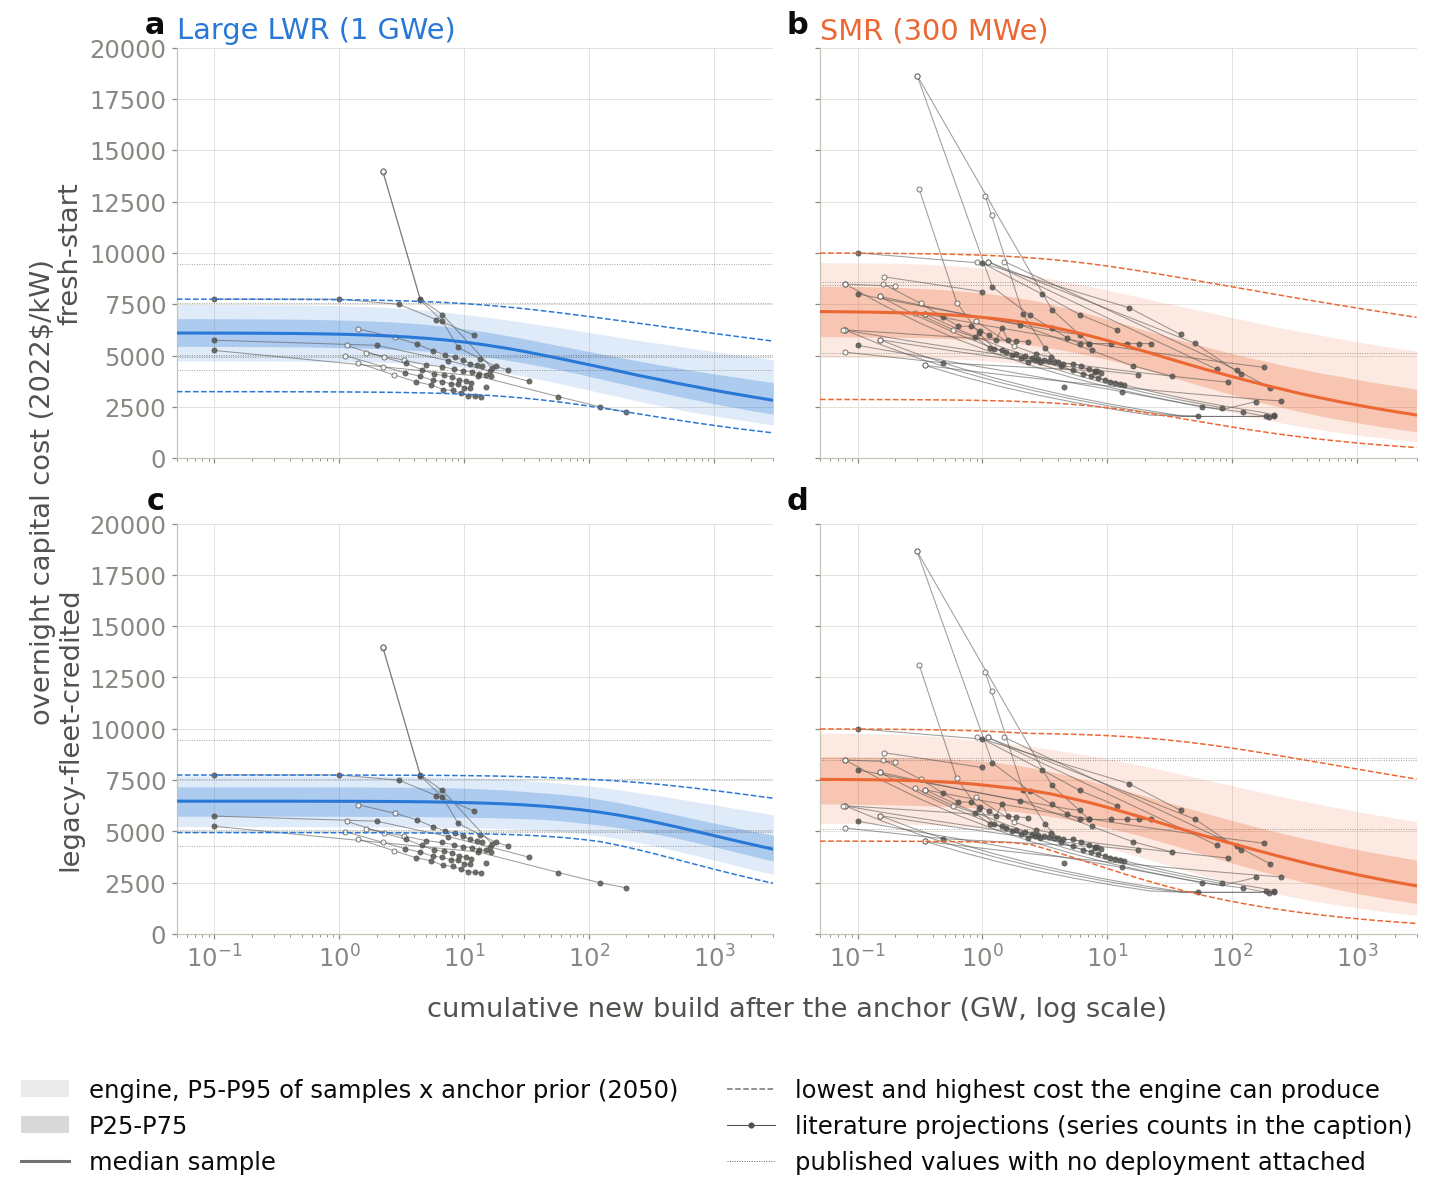

e10: literature series per panel: {'large': 16, 'smr': 33}


In [29]:
# e10 - the engine against the whole literature: the four e06 panels with EVERY literature
# series (the ATB source included) drawn as unlabeled grey lines and markers, so only the
# engine's fans carry colour and the reader sees the model against the literature's range.
# 2026-09-24 (Ethan E11), type only: the sizes come from plotstyle.PAPER_FONT scaled to this
# canvas, so e10 PRINTS at the same 8 / 9 / 9.5 / 8 pt as every other figure in the paper and
# its Supplementary Information. At that size a per-panel legend covers its own panel, so the
# four panels share one legend below the grid and the series counts move to the caption - the
# same two consequences the main-text twin e11 took. Nothing plotted changes.
GREY_SKIP = {"inl_review", "vanatta_micro", "steigerwald_parity"}   # a range statement; an out-of-scope design; a parity illustration
AJ_ANCHOR_GW = 0.1     # where the ATB source's 2030 anchor (zero post-2030 build) is drawn on the log axis (Ethan, 09-09)
def draw_series_grey(ax, g, x="cum_gw"):
    # One literature series in unlabeled grey. The ATB source's 2030 anchor sits at zero
    # post-2030 build (minus infinity on a log axis); it is drawn at AJ_ANCHOR_GW and the line
    # runs through it (the source's own SMR curves start near 0.83 units, ~0.25 GW).
    g = g.sort_values(x).copy()
    sid = g["series_id"].iloc[0]
    if sid in GREY_SKIP:
        return
    st = STYLE[sid]
    if sid.startswith("aj_"):
        g.loc[g[x] <= 0, x] = AJ_ANCHOR_GW
    if st["ls"] != "none":
        ax.plot(g[x], g["occ_2022"], color=MUTED, ls="-", lw=0.7, alpha=0.55, zorder=3)
    g = g[~g["is_curve"]]
    hollow = g["scored"] == 0
    for mask, fc in ((~hollow, MUTED), (hollow, "white")):
        gg = g[mask]
        if len(gg):
            ax.scatter(gg[x], gg["occ_2022"], marker="o", s=11, facecolor=fc, edgecolor=MUTED, lw=0.6, alpha=0.8, zorder=4)

from matplotlib.patches import Patch as _Patch10   # e11 imports it, but e11 runs after e10
_CW10 = 12.91          # measured rendered width of e10_engine_vs_all_literature.png, in inches
_PF10 = ps.fonts(_CW10)   # PAPER_FONT scaled to this canvas: it PRINTS at the specification
fig, axes = plt.subplots(2, 2, figsize=(ps.W3, 9.0), sharex=True, sharey=True)
n_series = {}
for c_, tech in enumerate(TECH):
    for r_, conv in enumerate(CONV_GRID):
        ax = axes[r_, c_]
        q = _FAN[(tech, conv)]
        ax.fill_between(D_PLANE_GW_LIT, q[:, 0], q[:, 4], color=TECH_COLOR[tech], alpha=0.14, lw=0,
                        label="engine, P5-P95 of samples x anchor prior (2050)")
        ax.fill_between(D_PLANE_GW_LIT, q[:, 1], q[:, 3], color=TECH_COLOR[tech], alpha=0.28, lw=0, label="P25-P75")
        ax.plot(D_PLANE_GW_LIT, q[:, 2], color=TECH_COLOR[tech], lw=2.0, label="median sample", zorder=5)
        ax.plot(D_PLANE_GW_LIT, _ENV[(tech, conv)][:, 0], color=TECH_COLOR[tech], lw=1.0, ls="--", zorder=5,
                label="lowest and highest cost the engine can produce")
        ax.plot(D_PLANE_GW_LIT, _ENV[(tech, conv)][:, 1], color=TECH_COLOR[tech], lw=1.0, ls="--", zorder=5)
        sub = pts[(pts.tech == tech) & pts.paired]
        for sid, g in sub.groupby("series_id", sort=False):
            draw_series_grey(ax, g)
        for r in pts[(pts.tech == tech) & ~pts.paired].itertuples():
            ax.axhline(r.occ_2022, color=MUTED, lw=0.6, ls=":", alpha=0.6, zorder=1)
        n_series[tech] = int(len(set(sub["series_id"]) - GREY_SKIP)) + int(pts[(pts.tech == tech) & ~pts.paired]["series_id"].nunique())
        ax.set_xscale("log")
        ax.set_xlim(0.05, 3000.0)
        ax.set_ylim(0, 20000)                      # one y range on all four panels (Ethan, 09-08)
        if r_ == 0:
            ax.set_title(TECH_LABEL[tech], color=TECH_COLOR[tech], loc="left",
                         fontsize=_PF10["panel_title"])
        if c_ == 0:
            # The stratum name alone. At the specification the old two-line rotated label
            # ran 3.7 in against a 2.9 in panel, so the two rows collided; the unit moves
            # to one shared y label below (09-24, E11).
            ax.set_ylabel("fresh-start" if conv == 0 else "legacy-fleet-credited",
                          fontsize=_PF10["axis_label"])
        ax.tick_params(axis="both", labelsize=_PF10["tick"])
# One shared legend below the grid (09-24, Ethan E11). Every panel draws the same six series,
# and at the printed type specification a legend inside a panel covers the panel, so the four
# share one. Neutral grey swatches, because the grid carries two technology colours; the
# per-panel series counts (n_series, printed below) move to the caption, as in e11.
_G10 = "0.45"
_h10 = [_Patch10(facecolor=_G10, alpha=0.14,
                 label="engine, P5-P95 of samples x anchor prior (2050)"),
        _Patch10(facecolor=_G10, alpha=0.28, label="P25-P75"),
        Line2D([], [], color=_G10, lw=2.0, label="median sample"),
        Line2D([], [], color=_G10, lw=1.0, ls="--",
               label="lowest and highest cost the engine can produce"),
        Line2D([], [], color=MUTED, lw=0.7, marker="o", ms=3,
               label="literature projections (series counts in the caption)"),
        Line2D([], [], color=MUTED, lw=0.6, ls=":",
               label="published values with no deployment attached")]
ps.letter_panels(axes.ravel(), size=_PF10["panel_letter"])
# One shared y unit and one shared x label under the grid. At the specification each
# per-panel label is longer than the panel it belongs to, so the four share both.
fig.supylabel("overnight capital cost (2022$/kW)", fontsize=_PF10["axis_label"],
              color=MUTED)
fig.tight_layout()
_xc10 = 0.5 * (axes[1, 0].get_position().x0 + axes[1, 1].get_position().x1)
fig.text(_xc10, -0.01, "cumulative new build after the anchor (GW, log scale)",
         ha="center", va="top", fontsize=_PF10["axis_label"], color=MUTED)
fig.legend(handles=_h10, ncol=2, fontsize=_PF10["legend"], frameon=False,
           loc="upper center", bbox_to_anchor=(0.5, -0.07))
ps.savefig(fig, paths.FIGS_SI / "SF01_engine_vs_literature.png")
plt.show()
print("e10: literature series per panel:", n_series)

saved -> analysis\results\exports\02\e11_engine_vs_literature_2panel.png


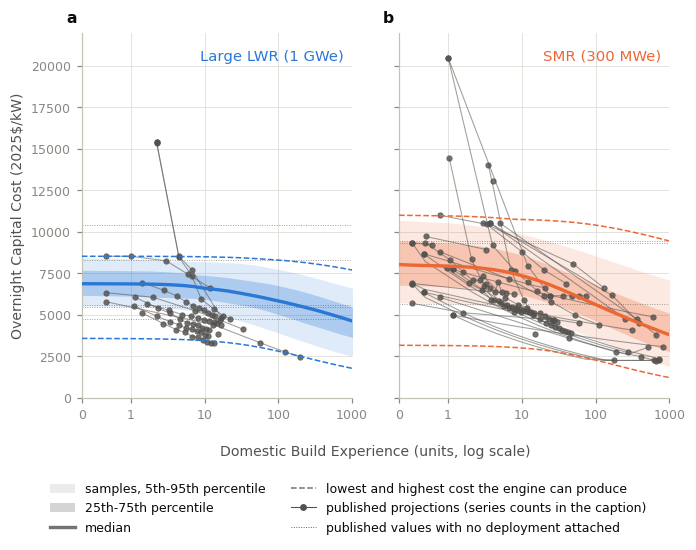

e11: literature series per panel: {'large': 16, 'smr': 33}
e11: 2022$ -> 2025$ multiplier x1.0990; x axis in units of 1 GW (large), 0.3 GW (smr)
pooled vs per-stratum median at 10 / 100 / 1000 units (2025$/kW):
  large 10 units: pooled 6,581  fresh-start 6,212  legacy-credited 7,042
  large 86 units: pooled 5,883  fresh-start 5,099  legacy-credited 6,657
  large 1,034 units: pooled 4,598  fresh-start 3,626  legacy-credited 5,253
  smr 8 units: pooled 7,444  fresh-start 7,212  legacy-credited 7,678
  smr 99 units: pooled 5,614  fresh-start 5,372  legacy-credited 5,859
  smr 834 units: pooled 3,914  fresh-start 3,699  legacy-credited 4,128


In [30]:
# e11 - the paper-ready two-panel version of e10 (main-text Fig 1, 09-09; rebuilt 2026-09-23 for
# Ethan's comment C3 and Wesley Cole's comment C4): one panel per technology; the engine's fan
# pooled over BOTH experience accountings (the grid holds the two strata in equal numbers, as the
# Monte Carlo samples them), every literature series in unlabeled grey. The split by accounting
# stays in e10 (SI).
#
# 2026-09-23, e11 ONLY - e06, e10 and every export keep their GW axis and their 2022 dollars:
#  (1) the x axis counts UNITS of domestic build experience, not GW. One unit is the model's own
#      reference size for the technology (1.0 GW for a large reactor, 0.3 GW for an SMR), so the
#      axis is the old GW axis divided by that size. The fans and every published series use the
#      same divisor, so no point moves relative to any other.
#  (2) the scale is symlog with linthresh = 1, so zero experience plots AT zero instead of being
#      pushed off a log axis. The fan grid therefore starts at n = 0, the 2030 cost itself.
#  (3) the ATB source's 2030 points sit at the experience the source itself starts from, not at
#      the 0.1 GW stand-in the log axis used to force. AJ_X_UNITS_2030 holds that position and is
#      the dial. The source attaches his SMR cost at his first 1 GW, which is 3.33 units of 0.3 GW
#      and, across his four vendors, 0.83 units PER VENDOR; his large cost attaches at 2 industry
#      units, 0.5 per vendor (the replication in mc_cost_trajectories QA4b). Ethan asked for the
#      per-vendor numbers (09-23, comment C3), so 0.83 and 0.5 are what the figure draws. The
#      industry-wide equivalents are {"smr": 3.33, "large": 2.0}, and the model's own n - units
#      built after 2030, counted industry-wide - puts them at {"smr": 0.0, "large": 0.0}; either
#      is one edit of this dial away.
#  (4) one marker style for every published point: the first-/second-of-a-kind split is gone.
#  (5) costs are converted to 2025 dollars at the point of display (the paper's dollar year);
#      occ_2022 and every export stay in 2022 dollars.
#  (6) type from plotstyle.PAPER_FONT (09-24, E11), one shared y range, so only the
#      left panel carries a y label.
USD25 = ps.to2025(2022)                        # 2022$ -> 2025$, applied only where this cell draws
D_PLANE_UNITS = {t: np.concatenate([[0.0], D_PLANE_GW_LIT / TECH[t]["unit_gw"]]) for t in TECH}
AJ_X_UNITS_2030 = {"smr": 0.83, "large": 0.5}  # per-vendor experience (Ethan, 09-23); see (3)
X_UNITS_LIM = (0.0, 1000.0)                    # one x range for both panels
Y_LIM_2025 = (0.0, 22000.0)                    # one y range for both panels, 2025$/kW
# 09-24 (Ethan E11): one type specification for every main figure. The sizes are
# scaled to this figure's composed canvas, so they PRINT at plotstyle.PAPER_FONT.
_PF = ps.fonts(ps.PAPER_CANVAS_IN["fig1"])
FS_TICK, FS_LAB, FS_PANEL, FS_LEG = (_PF["tick"], _PF["axis_label"],
                                     _PF["panel_title"], _PF["legend"])

_FAN2, _ENV2 = {}, {}
for tech in TECH:
    strat = SUPPORT[tech]
    nu = D_PLANE_UNITS[tech]
    q = np.empty((len(nu), 5))
    env = np.empty((len(nu), 2))
    for k, n_ in enumerate(nu):
        sh = shape_at(tech, G["lr"][strat], G["s"][strat], G["u"][strat], G["m"][strat], G["conv"][strat],
                      G["rho"][strat], n_, 2050)
        allc = np.outer(BOAK_Q[tech], sh).ravel()
        q[k] = np.quantile(allc, [0.05, 0.25, 0.5, 0.75, 0.95])
        env[k] = (allc.min(), allc.max())      # lowest / highest supported sample x 2030 cost prior
    _FAN2[tech], _ENV2[tech] = q, env
    # consistency: the pooled fan lies between the two per-stratum fans (e06/e10) at every build.
    # Compared on the shared grid, i.e. every column but the prepended zero-experience one.
    lo = np.minimum(_FAN[(tech, 0.0)], _FAN[(tech, 1.0)]); hi = np.maximum(_FAN[(tech, 0.0)], _FAN[(tech, 1.0)])
    assert np.all(q[1:, 2] >= lo[:, 2] - 1e-6) and np.all(q[1:, 2] <= hi[:, 2] + 1e-6), tech

from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter
from matplotlib.patches import Patch as _Patch

def x_units(g, tech):
    # Where a published series sits on the experience axis, in units of the reference size.
    x = g["cum_gw"].to_numpy(float) / TECH[tech]["unit_gw"]
    if str(g["series_id"].iloc[0]).startswith("aj_"):
        x = np.where(x <= 0.0, AJ_X_UNITS_2030[tech], x)
    return x

def draw_series_units(ax, g, tech):
    # One published series in unlabeled grey, on the units axis, in 2025 dollars. One marker
    # style for every point: e11 draws no first-/second-of-a-kind distinction (Ethan, 09-23).
    g = g.sort_values("cum_gw")
    sid = g["series_id"].iloc[0]
    if sid in GREY_SKIP:
        return
    x, y = x_units(g, tech), g["occ_2022"].to_numpy(float) * USD25
    if STYLE[sid]["ls"] != "none":
        ax.plot(x, y, color=MUTED, ls="-", lw=0.7, alpha=0.55, zorder=3)
    pt = ~g["is_curve"].to_numpy(bool)
    if pt.any():
        ax.scatter(x[pt], y[pt], marker="o", s=12, facecolor=MUTED, edgecolor=MUTED,
                   lw=0.6, alpha=0.8, zorder=4)

fig, axes = plt.subplots(1, 2, figsize=(ps.W1, 4.0), sharex=True, sharey=True)
n11 = {}
for c_, tech in enumerate(TECH):
    ax = axes[c_]
    nu, q, env = D_PLANE_UNITS[tech], _FAN2[tech] * USD25, _ENV2[tech] * USD25
    ax.fill_between(nu, q[:, 0], q[:, 4], color=TECH_COLOR[tech], alpha=0.14, lw=0,
                    label="samples, 5th-95th percentile")
    ax.fill_between(nu, q[:, 1], q[:, 3], color=TECH_COLOR[tech], alpha=0.28, lw=0, label="25th-75th percentile")
    ax.plot(nu, q[:, 2], color=TECH_COLOR[tech], lw=2.2, label="median", zorder=5)
    ax.plot(nu, env[:, 0], color=TECH_COLOR[tech], lw=1.0, ls="--", zorder=5,
            label="lowest and highest cost the engine can produce")
    ax.plot(nu, env[:, 1], color=TECH_COLOR[tech], lw=1.0, ls="--", zorder=5)
    sub = pts[(pts.tech == tech) & pts.paired]
    for sid, g in sub.groupby("series_id", sort=False):
        draw_series_units(ax, g, tech)
    for r in pts[(pts.tech == tech) & ~pts.paired].itertuples():
        ax.axhline(r.occ_2022 * USD25, color=MUTED, lw=0.6, ls=":", alpha=0.6, zorder=1)
    n11[tech] = int(len(set(sub["series_id"]) - GREY_SKIP)) + int(pts[(pts.tech == tech) & ~pts.paired]["series_id"].nunique())
    ax.set_xscale("symlog", linthresh=1.0, linscale=0.6)
    ax.set_xlim(*X_UNITS_LIM)
    ax.set_ylim(*Y_LIM_2025)
    ax.xaxis.set_major_locator(FixedLocator([0, 1, 10, 100, 1000]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.tick_params(axis="both", labelsize=FS_TICK)
    ax.text(0.97, 0.955, TECH_LABEL[tech], transform=ax.transAxes, color=TECH_COLOR[tech],
            fontsize=FS_PANEL, ha="right", va="top")   # top RIGHT: the tall SMR points sit top left
    if c_ == 0:
        ax.set_ylabel(f"Overnight Capital Cost {ps.usd('kW', 2025)}", fontsize=FS_LAB)
# one shared legend for both technologies: neutral grey swatches for the engine entries (09-10 review)
_G = "0.45"
_h11 = [_Patch(facecolor=_G, alpha=0.14, label="samples, 5th-95th percentile"),
        _Patch(facecolor=_G, alpha=0.30, label="25th-75th percentile"),
        Line2D([], [], color=_G, lw=2.2, label="median"),
        Line2D([], [], color=_G, lw=1.0, ls="--", label="lowest and highest cost the engine can produce"),
        Line2D([], [], color=MUTED, lw=0.7, marker="o", ms=3.5,
               label="published projections (series counts in the caption)"),
        Line2D([], [], color=MUTED, ls=":", lw=0.6, label="published values with no deployment attached")]
ps.panel_letter(axes[0], "a", size=_PF["panel_letter"])
ps.panel_letter(axes[1], "b", size=_PF["panel_letter"])
fig.tight_layout()
# One x label for both panels, centred under them: at FS_LAB the label is wider than one panel,
# so a per-axes label would collide with its neighbour. The legend sits below it.
_xc = 0.5 * (axes[0].get_position().x0 + axes[1].get_position().x1)
fig.text(_xc, -0.02, "Domestic Build Experience (units, log scale)", ha="center", va="top",
         fontsize=FS_LAB, color=MUTED)
fig.legend(handles=_h11, ncol=2, fontsize=FS_LEG, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ps.savefig(fig, EXPORTS / "e11_engine_vs_literature_2panel.png")
plt.show()
print("e11: literature series per panel:", n11)
print(f"e11: 2022$ -> 2025$ multiplier x{USD25:.4f}; x axis in units of "
      + ", ".join(f"{TECH[t]['unit_gw']:g} GW ({t})" for t in TECH))
print("pooled vs per-stratum median at 10 / 100 / 1000 units (2025$/kW):")
for tech in TECH:
    for un in (10.0, 100.0, 1000.0):
        k = int(np.argmin(np.abs(D_PLANE_GW_LIT / TECH[tech]["unit_gw"] - un)))
        print(f"  {tech} {D_PLANE_GW_LIT[k]/TECH[tech]['unit_gw']:,.0f} units: pooled {_FAN2[tech][k+1, 2]*USD25:,.0f}  "
              f"fresh-start {_FAN[(tech, 0.0)][k, 2]*USD25:,.0f}  legacy-credited {_FAN[(tech, 1.0)][k, 2]*USD25:,.0f}")

## B6 — Per-series reading and the verdict

The next cell prints a plain-language reading of every series from `c04` and `c05` (read R1;
dated or 2050 mode). The main findings:

- **The Abou-Jaoude trajectories, scored at ±$125/kW at all five milestones, are reproduced by
  few worlds** (0–0.5 % of the support). This is the designed difference of the 2030
  convention, not the paper's criterion, which is the one-sided 2050 endpoint of Section A5.
- **Single-design large-reactor chains lie outside the sampled space.** MIT's AP1000 chain has
  no feasible world under either read; the Liftoff chain needs learning rates of 26.5–30 %.
  Their first-to-Nth-of-a-kind slopes (22–26 % per doubling) lie above the engine's large
  support (3–12 %).
- **SMR series with a plateau, and most bottom-up small architectures, are reproduced broadly**,
  because their levels sit inside the anchor range and their slopes inside the sampled support.
- **Legacy-fleet-credited worlds reproduce no large-reactor series** but do reproduce the SMR
  plateaus.

The last cell writes `c99_verdict.csv` (every gate and kill disposition) and checks that
every table re-reads to what is in memory.

In [31]:
# Plain-language reading per series, generated from c04/c05 (primary read/mode).
def _fmt_range(row, d, pct=False):
    lo, hi = row[f"{d}_min"], row[f"{d}_max"]
    return f"{lo:.1%}-{hi:.1%}" if pct else f"{lo:g}-{hi:g}"
print("Per-series reading (read R1; dated or 2050 mode; feasible-set ranges over the whole grid):\n")
for key in RUNS:
    sid, tech, read, mode = key
    if read != "R1" or mode == "2030":
        continue
    if mode == "dated (+-250)":
        a = c04[(c04.series_id == sid) & (c04.tech == tech) & (c04.read == read) & (c04.year_mode == mode)].iloc[0]
        print(f"    (at the sibling's +-$250 trajectory tolerance: {a.n_feasible:,} feasible worlds, {a.share_support:.1%} of the support)")
        continue
    a = c04[(c04.series_id == sid) & (c04.tech == tech) & (c04.read == read) & (c04.year_mode == mode)].iloc[0]
    b = c05[(c05.series_id == sid) & (c05.tech == tech) & (c05.read == read) & (c05.year_mode == mode)].iloc[0]
    r2 = c04[(c04.series_id == sid) & (c04.tech == tech) & (c04.read == "R2") & (c04.year_mode == mode)]
    r2s = f"; under R2 {r2.iloc[0].share_support:.1%} of the support" if len(r2) else ""
    if a.n_feasible == 0:
        print(f"- {STYLE[sid]['label']} [{tech}]: no feasible world (nearest miss ${a.nearest_miss_usd:,.0f} of anchor){r2s}.")
        continue
    print(f"- {STYLE[sid]['label']} [{tech}]: {a.n_feasible:,} feasible worlds ({a.share_grid:.1%} of the grid, "
          f"{a.share_support:.1%} of the sampled LR support; fresh-start {a.share_support_fresh:.1%}, "
          f"legacy-credited {a.share_support_legacy:.1%}){r2s}. Learning rate {_fmt_range(b, 'lr', True)}, "
          f"spillover {_fmt_range(b, 's')}, vendors {_fmt_range(b, 'm')}, anchor "
          f"${b.boak_interval_min:,.0f}-{b.boak_interval_max:,.0f}/kW.")

Per-series reading (read R1; dated or 2050 mode; feasible-set ranges over the whole grid):

- ATB 2024 / Abou-Jaoude advanced [large]: 485 feasible worlds (0.4% of the grid, 0.0% of the sampled LR support; fresh-start 0.1%, legacy-credited 0.0%). Learning rate 12.0%-16.0%, spillover 0.1-1, vendors 4-8, anchor $5,250-5,375/kW.
    (at the sibling's +-$250 trajectory tolerance: 3,500 feasible worlds, 0.5% of the support)
- ATB 2024 / Abou-Jaoude conservative [large]: no feasible world (nearest miss $150 of anchor).
    (at the sibling's +-$250 trajectory tolerance: 87 feasible worlds, 0.0% of the support)
- ATB 2024 / Abou-Jaoude moderate [large]: 3,197 feasible worlds (2.8% of the grid, 0.5% of the sampled LR support; fresh-start 0.9%, legacy-credited 0.0%). Learning rate 11.5%-19.5%, spillover 0-1, vendors 4-8, anchor $5,625-5,875/kW.
    (at the sibling's +-$250 trajectory tolerance: 12,474 feasible worlds, 5.4% of the support)
- DOE Liftoff 2024 AP1000 chain [large]: 37 feasible worl

- IEA 2025 SMR NZE, US-and-EU cost at global capacity (digitized, exact) [smr]: 28,839 feasible worlds (25.4% of the grid, 56.3% of the sampled LR support; fresh-start 52.4%, legacy-credited 60.1%). Learning rate 4.0%-18.0%, spillover 0-1, vendors 4-8, anchor $5,500-10,000/kW.
- IEA 2025 SMR STEPS, US-and-EU cost at global capacity (digitized, exact) [smr]: 35,434 feasible worlds (31.2% of the grid, 50.9% of the sampled LR support; fresh-start 43.6%, legacy-credited 58.1%). Learning rate 0.5%-17.5%, spillover 0-1, vendors 4-8, anchor $6,630-10,000/kW.
- INL 2023 review, parametric (band = its quartiles) [smr]: 105,084 feasible worlds (92.7% of the grid, 100.0% of the sampled LR support; fresh-start 100.0%, legacy-credited 100.0%); under R2 99.1% of the support. Learning rate 0.5%-30.0%, spillover 0-1, vendors 4-8, anchor $5,500-10,000/kW.


- INL cost pathways, Concept A 4x264 MW (digitized, exact) [smr]: no feasible world (nearest miss $151 of anchor); under R2 0.0% of the support.
- INL cost pathways, Concept B 1x311 MW (digitized, exact) [smr]: 76,211 feasible worlds (67.2% of the grid, 61.4% of the sampled LR support; fresh-start 65.5%, legacy-credited 57.2%); under R2 90.0% of the support. Learning rate 4.5%-30.0%, spillover 0-1, vendors 4-8, anchor $5,514-10,000/kW.
- MIT ANP-201 SMR, 23 GW program (digitized) [smr]: 57,742 feasible worlds (50.9% of the grid, 89.4% of the sampled LR support; fresh-start 86.2%, legacy-credited 92.5%); under R2 57.7% of the support. Learning rate 0.5%-26.5%, spillover 0-1, vendors 4-8, anchor $6,354-10,000/kW.
- MIT ANP-201 SMR, 7 GW program (digitized) [smr]: 67,105 feasible worlds (59.2% of the grid, 45.4% of the sampled LR support; fresh-start 55.0%, legacy-credited 35.8%); under R2 69.9% of the support. Learning rate 6.5%-30.0%, spillover 0-1, vendors 4-8, anchor $7,534-10,000/kW.

In [32]:
c99 = pd.DataFrame(VERDICT, columns=["kind", "name", "result", "detail"])
c99.to_csv(EXPORTS / "c99_verdict.csv", index=False)
print(c99.to_string(index=False))
assert (c99[c99.kind == "gate"]["result"] == "PASS").all(), "every gate must pass"
# Round trip: every table re-reads to what is in memory.
for name, df in (("c02_points_2022usd.csv", pts), ("c04_feasible_shares.csv", c04), ("c05_parameter_ranges.csv", c05),
                 ("c06_aj_regression.csv", c06)):
    back = pd.read_csv(EXPORTS / name)
    assert len(back) == len(df) and list(back.columns) == list(df.columns), name
print("round-trip PASS")

kind name                result                                                                         detail
gate   G0                  PASS     ported engine reproduces mc_perdraw.npz (6 schedules x 2 techs, rtol 1e-9)
gate  G0b                  PASS                     closed form at any year == full engine, worst diff 0.0e+00
gate   G1                  PASS                              8 text anchors reproduced by the digitized series
gate  G1b                  PASS                            40 anchors reproduced by the 09-08 digitized series
kill   K5             CITE-ONLY                               21 studies listed in c08, none plotted or scored
kill   K3 OUTSIDE-SAMPLED-SPACE aj_conservative/large/R1/dated: no feasible world; nearest miss $150 of anchor
kill   K3 OUTSIDE-SAMPLED-SPACE   liftoff_ap1000/large/R2/2050: no feasible world; nearest miss $481 of anchor
kill   K3 OUTSIDE-SAMPLED-SPACE   liftoff_ap1000/large/R2/2030: no feasible world; nearest miss $481 of anchor
k

round-trip PASS
